# Formula 1 Podium Prediction — Milestone 1 (Part 1: data → modelling table)
**CSEN 903 Advanced Computer Lab — Team 40**

**Task:** for every driver in every race, predict whether he finishes on the podium (`positionOrder ≤ 3`), using
only information available **after qualifying and before the race starts**.

This notebook runs top to bottom with *Run All* and covers the milestone up to the modelling table:

| # | Section | Milestone item |
|---|---|---|
| 1 | Setup & loading | 14 raw tables, kept unchanged |
| 2 | EDA **before** cleaning | sentinels, keys, grain, distributions, coverage |
| 3 | Cleaning | sentinels, semantic typing, grain rule, primary/foreign keys |
| 4 | EDA **after** cleaning | effect of every cleaning step |
| 5 | Data-engineering questions Q1–Q3 | multi-hop joins, plots, grain/missingness/cutoff |
| 6 | Feature engineering | leakage-safe form, standings, grid & qualifying features → `all_features.csv` |
| 7 | Pre-training EDA & feature selection | distributions, correlation matrix, evidence for every feature |
| 7.6 | Bonus data-engineering questions | multi-hop joins that test the logic behind our engineered features |
| 7.7–7.9 | Feature selection, feature dictionary, limitations | final 21 features, why each is valid before the race |

# 1. Setup & data loading
The notebook finds the data by itself: the Kaggle input folder first, then the local repository folder. The raw CSV
files are **only read, never modified**; every cleaning step works on copies (brief: *"Raw CSV files remain
immutable"*).

Libraries: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy` (Spearman correlation; installed together with
scikit-learn). Tested with pandas 2.2 and pandas 3.0.

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', context='notebook')
BLUE, ORANGE, GREEN, YELLOW, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8c8c8c'

# Data folder: Kaggle first, then the local repository layouts we use
candidates = (glob.glob('/kaggle/input/**/results.csv', recursive=True)
              + glob.glob('../ACL_9th-F1/F1/results.csv') + glob.glob('F1/results.csv'))
DATA_DIR = os.path.dirname(candidates[0])
OUT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
print('data folder:', DATA_DIR, '| output folder:', OUT_DIR)

data folder: F1 | output folder: .


In [2]:
TABLES = ['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers',
          'driver_standings', 'races', 'results', 'qualifying', 'lap_times', 'pit_stops',
          'sprint_results', 'seasons', 'status']

def text_columns(df):
    # text columns ('object' in pandas 2, 'str' in pandas 3)
    return df.select_dtypes(include=['object', 'string']).columns

# read every table as it is (the literal "\N" stays a string so we can count it)
raw = {name: pd.read_csv(os.path.join(DATA_DIR, name + '.csv')) for name in TABLES}

overview = pd.DataFrame({name: {'rows': len(df), 'columns': df.shape[1],
                                'text columns': len(text_columns(df)),
                                'cells with \\N': int((df == '\\N').sum().sum())}
                         for name, df in raw.items()}).T
overview.sort_values('rows', ascending=False)

,rows,columns,text columns,cells with \N
lap_times,589081,6,1,0
driver_standings,34863,7,1,0
results,26759,18,9,122887
constructor_standings,13391,7,1,0
constructor_results,12625,5,1,12608
pit_stops,11371,7,2,0
qualifying,10494,9,3,11600
races,1125,18,14,11349
drivers,861,9,8,1559
sprint_results,360,16,6,73


**Observations**
- 14 tables, from 75 rows (`seasons`) to 589,081 rows (`lap_times`). The modelling grain lives in `results`
  (26,759 rows).
- **160,076 cells are the text `\N`** (77 % of them in `results`). Pandas reads these columns as text, so a numeric
  column such as `rank` or `milliseconds` cannot be used before cleaning.

# 2. EDA before cleaning
We look at the raw tables first, so that every cleaning step in Section 3 answers a problem that is visible here.

## 2.1 Sentinel values (`\N`)
The Ergast export writes a missing value as the literal text `\N`. Pandas does not recognise it, so a numeric column
that contains it is read as text.

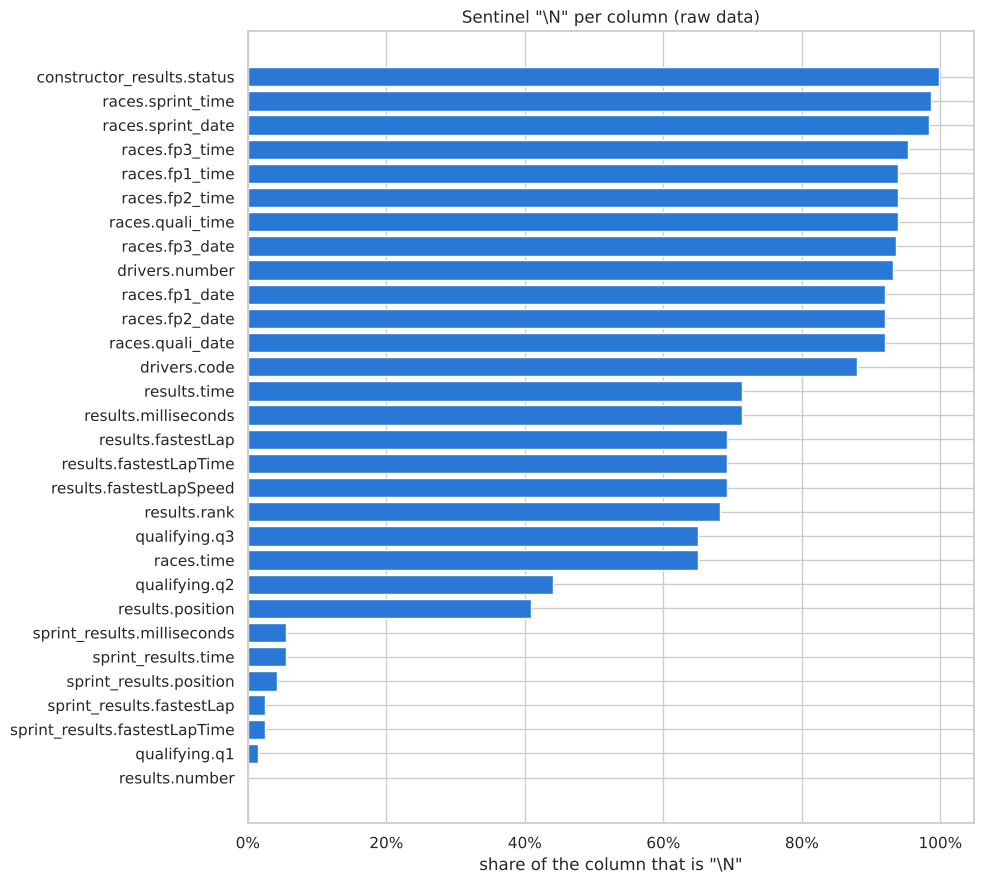

cells with \N  share of column read as
constructor_results status                   12608            0.999     str
races               sprint_time               1110            0.987     str
                    sprint_date               1107            0.984     str
                    fp3_time                  1072            0.953     str
                    fp2_time                  1057            0.940     str
                    fp1_time                  1057            0.940     str
                    quali_time                1057            0.940     str
                    fp3_date                  1053            0.936     str
drivers             number                     802            0.931     str
races               fp1_date                  1035            0.920     str
                    fp2_date                  1035            0.920     str
                    quali_date                1035            0.920     str
drivers             code                       757            0.879     str
results             milliseconds             19079            0.713     str
                    time                     19079            0.713     str
                    fastestLapSpeed          18507            0.692     str
                    fastestLapTime           18507            0.692     str
                    fastestLap               18507            0.692     str
                    rank                     18249            0.682     str
qualifying          q3                        6819            0.650     str
races               time                       731            0.650     str
qualifying          q2                        4625            0.441     str
results             position                 10953            0.409     str
sprint_results      milliseconds                20            0.056     str
                    time                        20            0.056     str
                    position                    15            0.042     str
                    fastestLapTime               9            0.025     str
                    fastestLap                   9            0.025     str
qualifying          q1                         156            0.015     str
results             number                       6            0.000     str

In [3]:
sentinels = pd.concat({name: (df == '\\N').sum() for name, df in raw.items()})
sentinels = sentinels[sentinels > 0].rename('cells with \\N').to_frame()
sentinels['share of column'] = [ (raw[t][c] == '\\N').mean() for t, c in sentinels.index ]
sentinels['read as'] = [ str(raw[t][c].dtype) for t, c in sentinels.index ]

fig, ax = plt.subplots(figsize=(10, 9))
plot_data = sentinels['share of column'].sort_values()
ax.barh([f'{t}.{c}' for t, c in plot_data.index], plot_data.values, color=BLUE)
ax.set_xlabel('share of the column that is "\\N"'); ax.set_title('Sentinel "\\N" per column (raw data)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()
sentinels.sort_values('share of column', ascending=False).round(3)

**Observations**
- `\N` means "does not exist / not recorded", not "zero". In `results` it hits post-race columns: no race time for
  71 % of rows (retired, lapped), no fastest-lap data for 69 % (fastest laps are only recorded from 2004), no official
  `position` for 41 % (retirements).
- `qualifying.q2/q3` are `\N` for 44 % / 65 % of rows: eliminated drivers do not drive Q2/Q3 in the knockout format.
- `races` session dates/times (`fp1_date` … `sprint_time`) are `\N` for 92–99 %: only recorded for recent seasons.
- `constructor_results.status` is almost entirely `\N` (99.9 %), so it carries no information.

**Decision:** every `\N` becomes `NaN` in cleaning (3.1) and the affected columns are converted to numbers.

## 2.2 Primary keys and the grain of the main tables
A primary key must be unique and never empty. Besides each table's id column we also check the **natural key** that
the modelling table needs: one row per (`raceId`, `driverId`).

In [4]:
KEYS = {'circuits': ['circuitId'], 'constructors': ['constructorId'], 'drivers': ['driverId'],
        'races': ['raceId'], 'seasons': ['year'], 'status': ['statusId'],
        'results': ['resultId'], 'sprint_results': ['resultId'], 'qualifying': ['qualifyId'],
        'constructor_results': ['constructorResultsId'], 'constructor_standings': ['constructorStandingsId'],
        'driver_standings': ['driverStandingsId'], 'lap_times': ['raceId', 'driverId', 'lap'],
        'pit_stops': ['raceId', 'driverId', 'stop'],
        # natural keys (one row per driver/team per race)
        'results ': ['raceId', 'driverId'], 'qualifying ': ['raceId', 'driverId'],
        'driver_standings ': ['raceId', 'driverId'], 'constructor_standings ': ['raceId', 'constructorId']}

def key_report(tables):
    rows = []
    for name, key in KEYS.items():
        df = tables[name.strip()]
        rows.append({'table': name.strip(), 'key': ' + '.join(key),
                     'empty key values': int(df[key].isna().sum().sum() + (df[key] == '\\N').sum().sum()),
                     'duplicate keys': int(df.duplicated(subset=key).sum())})
    return pd.DataFrame(rows)

key_report(raw)

,table,key,empty key values,duplicate keys
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,drivers,driverId,0,0
3,races,raceId,0,0
4,seasons,year,0,0
5,status,statusId,0,0
6,results,resultId,0,0
7,sprint_results,resultId,0,0
8,qualifying,qualifyId,0,0
9,constructor_results,constructorResultsId,0,0


**Observations**
- Every id column (`raceId`, `driverId`, …) is unique and never empty, and so are the composite keys of `lap_times`
  (race + driver + lap) and `pit_stops` (race + driver + stop).
- The **only grain problem is `results`: 91 rows repeat a (`raceId`, `driverId`) pair**. `qualifying` and both
  standings tables already have one row per driver (team) per race.

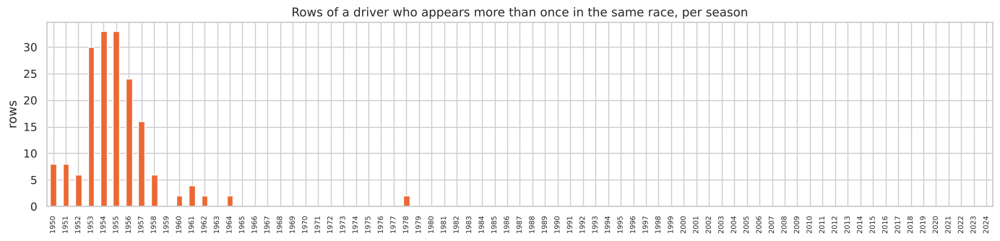

extra rows: 91 | driver-race pairs affected: 85


,year,name,driverId,constructorId,number,grid,positionOrder,positionText,laps,points
13188,1978,Italian Grand Prix,229,54,10,0,26,F,0,0.0
13191,1978,Italian Grand Prix,229,57,23,0,29,F,0,0.0
17362,1964,United States Grand Prix,373,172,1,1,7,7,102,0.0
24298,1964,United States Grand Prix,373,172,2,1,12,R,54,0.0
17740,1962,British Grand Prix,465,172,48,0,22,W,0,0.0
17743,1962,British Grand Prix,465,97,50,0,25,W,0,0.0
17961,1961,British Grand Prix,475,102,26,20,19,D,56,0.0
17963,1961,British Grand Prix,475,172,28,5,21,R,44,0.0


In [5]:
# The 91 repeated (raceId, driverId) pairs in results: when do they happen and what do they look like?
res_raw = raw['results'].merge(raw['races'][['raceId', 'year', 'name']], on='raceId')
dup_mask = res_raw.duplicated(subset=['raceId', 'driverId'], keep=False)

fig, ax = plt.subplots(figsize=(14, 3.5))
res_raw[dup_mask].groupby('year').size().reindex(range(1950, 2025), fill_value=0).plot(kind='bar', ax=ax, color=ORANGE)
ax.set_title('Rows of a driver who appears more than once in the same race, per season')
ax.set_xlabel(''); ax.set_ylabel('rows'); ax.tick_params(axis='x', labelsize=7)
plt.tight_layout(); plt.show()

print('extra rows:', res_raw.duplicated(subset=['raceId', 'driverId']).sum(),
      '| driver-race pairs affected:', res_raw[dup_mask].groupby(['raceId', 'driverId']).ngroups)
res_raw[dup_mask].sort_values(['raceId', 'driverId'])[
    ['year', 'name', 'driverId', 'constructorId', 'number', 'grid', 'positionOrder', 'positionText', 'laps', 'points']].head(8)

**Observations**
- The 91 extra rows belong to **85 driver-race pairs**, almost all in **1950–1958** (peak 1953–1956), plus a few up to
  1964 and two in 1978 — exactly the shared-drive era described in the brief.
- Two causes are visible in the examples:
  - **shared drives**: driver 373 drove cars 1 and 2 of the same team in the 1964 US GP (finished 7th and retired);
  - **double entries that never started**: driver 465 entered two teams in the 1962 British GP (`W`, 0 laps both).

## 2.3 Foreign keys
Every id that points to another table must exist there; otherwise a join silently drops or invents rows.

In [6]:
FOREIGN_KEYS = [  # (child table, column, parent table, parent column)
    ('races', 'circuitId', 'circuits', 'circuitId'), ('races', 'year', 'seasons', 'year'),
    ('results', 'raceId', 'races', 'raceId'), ('results', 'driverId', 'drivers', 'driverId'),
    ('results', 'constructorId', 'constructors', 'constructorId'), ('results', 'statusId', 'status', 'statusId'),
    ('qualifying', 'raceId', 'races', 'raceId'), ('qualifying', 'driverId', 'drivers', 'driverId'),
    ('qualifying', 'constructorId', 'constructors', 'constructorId'),
    ('lap_times', 'raceId', 'races', 'raceId'), ('lap_times', 'driverId', 'drivers', 'driverId'),
    ('pit_stops', 'raceId', 'races', 'raceId'), ('pit_stops', 'driverId', 'drivers', 'driverId'),
    ('driver_standings', 'raceId', 'races', 'raceId'), ('driver_standings', 'driverId', 'drivers', 'driverId'),
    ('constructor_standings', 'raceId', 'races', 'raceId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
    ('constructor_results', 'raceId', 'races', 'raceId'),
    ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'raceId', 'races', 'raceId'), ('sprint_results', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'constructorId', 'constructors', 'constructorId'), ('sprint_results', 'statusId', 'status', 'statusId')]

def foreign_key_report(tables):
    rows = []
    for child, col, parent, pcol in FOREIGN_KEYS:
        orphans = ~tables[child][col].isin(tables[parent][pcol])
        rows.append({'reference': f'{child}.{col} -> {parent}.{pcol}', 'rows checked': len(tables[child]),
                     'missing in parent': int(orphans.sum())})
    # session tables must describe a (race, driver) that exists in results
    for child in ['qualifying', 'lap_times', 'pit_stops']:
        pairs = tables[child][['raceId', 'driverId']].drop_duplicates()
        known = pairs.merge(tables['results'][['raceId', 'driverId']].drop_duplicates(), how='left', indicator=True)
        rows.append({'reference': f'{child}.(raceId, driverId) -> results', 'rows checked': len(pairs),
                     'missing in parent': int((known['_merge'] == 'left_only').sum())})
    return pd.DataFrame(rows)

fk_raw = foreign_key_report(raw)
fk_raw

,reference,rows checked,missing in parent
0,races.circuitId -> circuits.circuitId,1125,0
1,races.year -> seasons.year,1125,0
2,results.raceId -> races.raceId,26759,0
3,results.driverId -> drivers.driverId,26759,0
4,results.constructorId -> constructors.construc...,26759,0
5,results.statusId -> status.statusId,26759,0
6,qualifying.raceId -> races.raceId,10494,0
7,qualifying.driverId -> drivers.driverId,10494,0
8,qualifying.constructorId -> constructors.const...,10494,0
9,lap_times.raceId -> races.raceId,589081,0


**Observations:** **every foreign key reconciles** (0 missing parents in 26 checks), including the session tables:
every (race, driver) in `qualifying`, `lap_times` and `pit_stops` exists in `results`. Joins on these keys cannot
lose or invent rows; we still re-check after cleaning (3.7).

## 2.4 The results table: distributions and odd values
`results` holds the target (`positionOrder`) and the starting grid. Its numeric columns are partly read as text
because of `\N`, so we convert a **temporary copy** only for plotting.

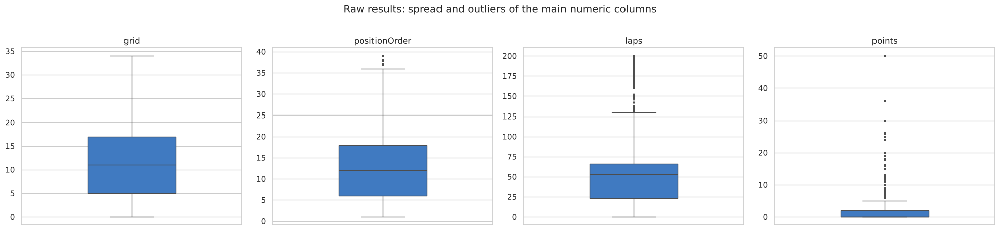

,grid,positionOrder,laps,points,rank
count,26759.00,26759.00,26759.0,26759.00,8510.00
mean,11.13,12.79,46.3,1.99,10.33
std,7.20,7.67,29.5,4.35,6.14
min,0.00,1.00,0.0,0.00,0.00
25%,5.00,6.00,23.0,0.00,5.00
50%,11.00,12.00,53.0,0.00,10.00
75%,17.00,18.00,66.0,2.00,15.00
max,34.00,39.00,200.0,50.00,24.00


In [7]:
res_num = raw['results'].replace('\\N', np.nan)
for col in ['grid', 'positionOrder', 'laps', 'points', 'rank', 'milliseconds']:
    res_num[col] = pd.to_numeric(res_num[col])

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axes, ['grid', 'positionOrder', 'laps', 'points']):
    sns.boxplot(y=res_num[col], ax=ax, color=BLUE, width=0.4, flierprops={'markersize': 2})
    ax.set_title(col); ax.set_ylabel('')
plt.suptitle('Raw results: spread and outliers of the main numeric columns', y=1.02)
plt.tight_layout(); plt.show()
res_num[['grid', 'positionOrder', 'laps', 'points', 'rank']].describe().round(2)

**Observations**
- **`grid` has a minimum of 0**, which is not a starting slot (investigated next).
- **`laps` up to 200** are the Indianapolis 500 (an oval race of 200 laps), far from a normal F1 race (median 53).
- **`points` up to 50**: the 2014 Abu Dhabi GP awarded double points. Raw points are therefore not comparable
  between races and seasons → handled by `points_share` (6.8).
- `positionOrder` goes up to 39 (fields of 30+ cars in the 1950s); `rank` only exists for 8,510 rows (from 2004).

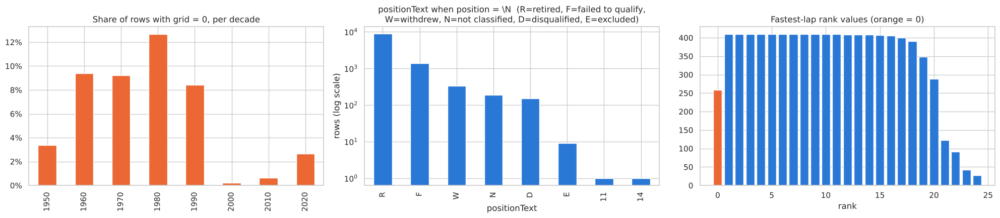

rows with rank = 0: 258 | their positionText: {'R': 179, 'W': 33, 'D': 5, 'F': 4, '5': 3, '1': 2, '2': 2, '3': 2, '4': 2, '6': 2, '7': 2, '8': 2, '9': 2, '10': 2, '11': 2, '12': 2, '13': 2, '14': 2, '15': 2, '16': 2, '17': 1, '18': 1, '19': 1, '20': 1} | median laps: 0.0 | rows with a fastest-lap time: 0


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))

# (a) grid = 0 by decade: not a real starting slot
grid0 = res_num.merge(raw['races'][['raceId', 'year']], on='raceId')
grid0['decade'] = grid0['year'] // 10 * 10
grid0.groupby('decade')['grid'].apply(lambda g: (g == 0).mean()).plot(kind='bar', ax=axes[0], color=ORANGE)
axes[0].set_title('Share of rows with grid = 0, per decade'); axes[0].set_xlabel('')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))

# (b) why is there no official position?  positionText codes
codes = raw['results'].loc[raw['results']['position'] == '\\N', 'positionText'].value_counts()
codes.plot(kind='bar', ax=axes[1], color=BLUE)
axes[1].set_title('positionText when position = \\N  (R=retired, F=failed to qualify,\nW=withdrew, N=not classified, D=disqualified, E=excluded)')
axes[1].set_yscale('log'); axes[1].set_ylabel('rows (log scale)')

# (c) fastest-lap rank: the value 0 is not a rank
rank_counts = res_num['rank'].value_counts().sort_index()
axes[2].bar(rank_counts.index, rank_counts.values, color=[ORANGE if r == 0 else BLUE for r in rank_counts.index])
axes[2].set_title('Fastest-lap rank values (orange = 0)'); axes[2].set_xlabel('rank')
plt.tight_layout(); plt.show()

zero_rank = res_num[res_num['rank'] == 0]
print('rows with rank = 0:', len(zero_rank), '| their positionText:', zero_rank['positionText'].value_counts().to_dict(),
      '| median laps:', zero_rank['laps'].median(),
      '| rows with a fastest-lap time:', int(zero_rank['fastestLapTime'].notna().sum()))

**Observations**
- **`grid = 0` peaks in the 1980s (~13 % of rows)**, when many cars failed to qualify or pre-qualify, and is almost
  zero after 2000; modern grid-0 rows are pit-lane starts. Grid 0 must not be read as "pole position" (→ `grid_pos`, 6.6).
- When there is no official position, `positionText` explains why: mostly **R** (retired, 8,897), **F** (failed to
  qualify), **W** (withdrew), **N**, **D**, **E**.
- **258 rows have fastest-lap rank 0.** They have no fastest-lap time at all and a median of 0 laps: retirements on
  lap 1 (`R` 179), withdrawals (`W` 33), and a few classified finishers in races where no timed lap was recorded.
  0 is a placeholder, not "faster than rank 1" → set to `NaN` (3.3).

## 2.5 Data coverage per season
Some tables only start in a certain year. This decides which features can exist for which seasons, so we measure it
instead of assuming it.

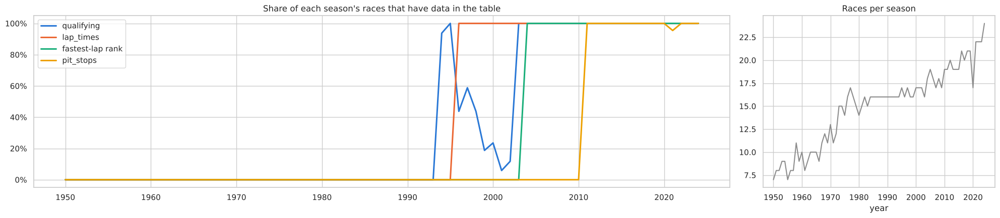

first season in which EVERY race has data: {'qualifying': 1995, 'lap_times': 1996, 'fastest-lap rank': 2004, 'pit_stops': 2011}


,qualifying,lap_times,fastest-lap rank,pit_stops
year,,,,
1993,0.00,0.0,0.0,0.0
1994,0.94,0.0,0.0,0.0
1996,0.44,1.0,0.0,0.0
2002,0.12,1.0,0.0,0.0
2003,1.00,1.0,0.0,0.0
2004,1.00,1.0,1.0,0.0
2010,1.00,1.0,1.0,0.0
2011,1.00,1.0,1.0,1.0


In [9]:
season_races = raw['races'].groupby('year')['raceId'].apply(set)
rank_races = set(res_num.loc[res_num['rank'].notna(), 'raceId'])

def share_of_races(race_ids):
    race_ids = set(race_ids)
    return season_races.apply(lambda ids: len(ids & race_ids) / len(ids))

coverage = pd.DataFrame({'qualifying': share_of_races(raw['qualifying']['raceId']),
                         'lap_times': share_of_races(raw['lap_times']['raceId']),
                         'fastest-lap rank': share_of_races(rank_races),
                         'pit_stops': share_of_races(raw['pit_stops']['raceId'])})

fig, axes = plt.subplots(1, 2, figsize=(20, 4.5), gridspec_kw={'width_ratios': [3, 1]})
for (col, color) in zip(coverage.columns, [BLUE, ORANGE, GREEN, YELLOW]):
    axes[0].plot(coverage.index, coverage[col], label=col, color=color, linewidth=2.2)
axes[0].set_title('Share of each season\'s races that have data in the table')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); axes[0].legend()
raw['races']['year'].value_counts().sort_index().plot(ax=axes[1], color=GREY)
axes[1].set_title('Races per season')
plt.tight_layout(); plt.show()

first_full = {col: int(coverage.index[(coverage[col] == 1)].min()) for col in coverage}
print('first season in which EVERY race has data:', first_full)
coverage.loc[[1993, 1994, 1996, 2002, 2003, 2004, 2010, 2011]].round(2)

**Observations (these dates decide which features are real in which seasons)**
- **Qualifying:** none before 1994; 94–100 % of races in 1994–1995; then **only 6–59 % of races in 1996–2002**; complete
  **from 2003**.
- **Lap times** (running position): complete from **1996**.
- **Fastest-lap rank:** from **2004**.
- **Pit stops:** from **2011** (one race missing in 2021).
- The number of races per season grows from 7 (1950) to 24 (2024), so later seasons weigh more in any pooled number.

Before these years a feature built from the table cannot exist; it will hold a fill value (6.7), and Section 7 checks
how much those fill values distort the correlations.

## 2.6 Durations stored as text, and their outliers
The brief asks for semantic typing of durations. Lap and qualifying times are strings such as `1:27.452`; pit stop
durations as well. Below are the numeric versions that already exist (milliseconds) to see their range.

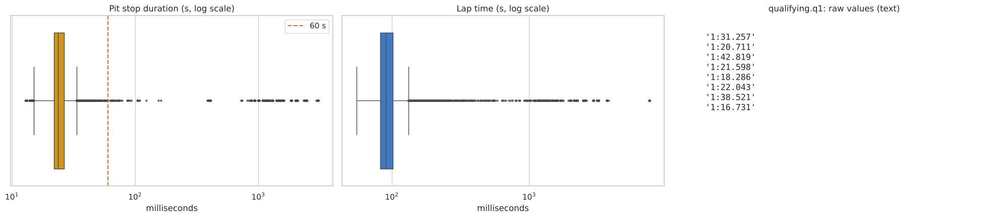

pit stops: 11371 | median 23.6 s | 95th pct 45.9 s | longer than 60 s: 517 (4.5%) | max 51.2 min
dtypes of time columns: {'q1': 'str', 'q2': 'str', 'q3': 'str'} | pit_stops.duration: str | results.fastestLapTime: str


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
sns.boxplot(x=raw['pit_stops']['milliseconds'] / 1000, ax=axes[0], color=YELLOW, flierprops={'markersize': 2})
axes[0].set_xscale('log'); axes[0].set_title('Pit stop duration (s, log scale)')
axes[0].axvline(60, color=ORANGE, linestyle='--', label='60 s'); axes[0].legend()

sns.boxplot(x=raw['lap_times']['milliseconds'] / 1000, ax=axes[1], color=BLUE, flierprops={'markersize': 2})
axes[1].set_xscale('log'); axes[1].set_title('Lap time (s, log scale)')

q1_examples = raw['qualifying']['q1'].sample(8, random_state=1).tolist()
axes[2].axis('off'); axes[2].set_title('qualifying.q1: raw values (text)')
axes[2].text(0.1, 0.9, '\n'.join(map(repr, q1_examples)), va='top', family='monospace', fontsize=12)
plt.tight_layout(); plt.show()

pit = raw['pit_stops']['milliseconds'] / 1000
print('pit stops:', len(pit), '| median', round(pit.median(), 1), 's | 95th pct', round(pit.quantile(.95), 1),
      's | longer than 60 s:', (pit > 60).sum(), f'({(pit > 60).mean():.1%})', '| max', round(pit.max() / 60, 1), 'min')
print('dtypes of time columns:', {c: str(raw['qualifying'][c].dtype) for c in ['q1', 'q2', 'q3']},
      '| pit_stops.duration:', raw['pit_stops']['duration'].dtype, '| results.fastestLapTime:', raw['results']['fastestLapTime'].dtype)

**Observations**
- **Pit stops:** median 23.6 s (time from pit entry to exit), 95 % below 45.9 s — but **517 stops (4.5 %) last longer
  than 60 s, up to 51 minutes**. A normal stop cannot take minutes; see the next cell.
- **Lap times** have a long right tail for the same reason (safety-car and red-flag laps); only the lap *position* is
  used in features, so the times are not changed.
- Qualifying times, pit `duration` and `results.fastestLapTime` are **text** like `'1:27.452'` → converted to seconds (3.2).

In [11]:
# Long pit stops: which races?  (red flags count as a pit stop in this table)
long_stops = (raw['pit_stops'][raw['pit_stops']['milliseconds'] > 60_000]
              .merge(raw['races'][['raceId', 'year', 'name']], on='raceId'))
long_stops.groupby(['year', 'name']).size().sort_values(ascending=False).head(8).rename('stops > 60 s').to_frame()

,,stops > 60 s
year,name,
2023,Australian Grand Prix,49
2016,Brazilian Grand Prix,36
2021,Saudi Arabian Grand Prix,35
2020,Tuscan Grand Prix,25
2021,Emilia Romagna Grand Prix,22
2014,Japanese Grand Prix,22
2021,British Grand Prix,19
2020,Bahrain Grand Prix,19


**Observations:** the races with the most stops above 60 s are well-known **red-flag races** — 2023 Australia (three
red flags), 2016 Brazil (rain), 2021 Saudi Arabia, 2020 Tuscany, 2020 Bahrain (Grosjean's fire), 2014 Japan
(Bianchi's accident). During a red flag every car waits in the pit lane and the table records it as a stop.
These are real events, but they say nothing about a team's pit-stop speed → flagged and left out of the pit-time
average (3.6).

## 2.7 Text consistency (names used in joins)
`is_home_race` and Q2 join a driver's nationality to a circuit's country, so the spelling must match.

In [12]:
nat = raw['drivers']['nationality']
print('nationalities with leading/trailing spaces:', nat[nat != nat.str.strip()].unique().tolist())
print('similar nationality spellings:', sorted(n for n in nat.str.strip().unique() if n.startswith('Argent')))
print('circuit countries for the USA:', sorted(c for c in raw['circuits']['country'].unique() if 'US' in c or 'United' in c))
print('\nIndianapolis 500 races (part of the championship 1950-1960):',
      (raw['races']['name'] == 'Indianapolis 500').sum(), 'races,',
      raw['results'].merge(raw['races'], on='raceId').query('name == "Indianapolis 500"')['driverId'].nunique(), 'drivers')

nationalities with leading/trailing spaces: ['Argentinian ']
similar nationality spellings: ['Argentine', 'Argentine-Italian', 'Argentinian']
circuit countries for the USA: ['USA', 'United States']

Indianapolis 500 races (part of the championship 1950-1960): 11 races, 107 drivers


**Observations**
- `'Argentinian '` has a trailing space and is a second spelling of `Argentine`; the USA appears as both `USA` and
  `United States`. Both would break the nationality → country join used for `is_home_race` and Q2.
- The **Indianapolis 500** (11 races, 107 drivers) was part of the championship in 1950–1960 but run by American
  oval specialists; it behaves like a different series.

# 3. Cleaning
Every step below answers a problem found in Section 2. All steps work on copies in the dictionary `clean`; `raw`
stays exactly as read from disk.

## 3.1 Sentinels, numbers stored as text, stray spaces (all 14 tables)
1. `\N` → `NaN`, a real missing value that pandas understands (2.1).
2. A text column whose every non-missing value is a number becomes numeric (`rank`, `milliseconds`, `number`, …).
3. Leading/trailing spaces are removed from text (e.g. `'Argentinian '`, 2.7).

In [13]:
def numeric_where_possible(df):
    # convert a text column to numbers only if EVERY non-missing value is a number (no value is lost)
    for col in text_columns(df):
        as_number = pd.to_numeric(df[col], errors='coerce')
        if as_number.notna().sum() == df[col].notna().sum():
            df[col] = as_number
    return df

clean = {}
for name, df in raw.items():
    df = df.replace('\\N', np.nan)                      # 1. sentinel -> NaN (replace returns a copy)
    df = numeric_where_possible(df)                      # 2. numbers stored as text -> numbers
    for col in text_columns(df):
        df[col] = df[col].str.strip()                      # 3. stray spaces
    clean[name] = df

converted = pd.DataFrame([{'table': name, 'column': col, 'raw type': str(raw[name][col].dtype),
                           'clean type': str(clean[name][col].dtype)}
                          for name in TABLES for col in raw[name].columns
                          if raw[name][col].dtype != clean[name][col].dtype])
print('\\N cells left in all tables:', sum(int((df == '\\N').sum().sum()) for df in clean.values()))
converted

\N cells left in all tables: 0


,table,column,raw type,clean type
0,drivers,number,str,float64
1,results,number,str,float64
2,results,position,str,float64
3,results,milliseconds,str,float64
4,results,fastestLap,str,float64
5,results,rank,str,float64
6,results,fastestLapSpeed,str,float64
7,sprint_results,position,str,float64
8,sprint_results,milliseconds,str,float64
9,sprint_results,fastestLap,str,float64


**Result:** no `\N` is left in any table, and 10 columns that were text only because of `\N` are numbers now
(`results.rank`, `results.milliseconds`, `results.position`, …). No value was lost: a column is only converted when
every non-missing value is a number.

## 3.2 Semantic typing: dates and durations
- Dates (`races.date`, `drivers.dob`) become real dates, so seasons and ages can be computed.
- Durations stored as text (`m:ss.sss`) become **seconds** (float): qualifying `q1/q2/q3`, `results.fastestLapTime`,
  `sprint_results.fastestLapTime`, `pit_stops.duration`, `lap_times.time`. The text columns are replaced by `*_s`.
- `results.time` is dropped: it mixes the winner's race time with gaps (`+5.478`) and is fully covered by the numeric
  `milliseconds`; it is post-race information anyway.

In [14]:
def to_seconds(t):
    # '1:27.452' -> 87.452 | '27.452' -> 27.452 | '1:34:50.616' -> 5690.616 | missing stays NaN
    if pd.isna(t):
        return np.nan
    try:
        return sum(float(part) * 60 ** i for i, part in enumerate(reversed(str(t).split(':'))))
    except ValueError:
        return np.nan

clean['races']['date'] = pd.to_datetime(clean['races']['date'], format='%Y-%m-%d')
clean['drivers']['dob'] = pd.to_datetime(clean['drivers']['dob'], format='%Y-%m-%d')

DURATIONS = {'qualifying': ['q1', 'q2', 'q3'], 'results': ['fastestLapTime'], 'sprint_results': ['fastestLapTime'],
             'pit_stops': ['duration'], 'lap_times': ['time']}
for table, cols in DURATIONS.items():
    for col in cols:
        clean[table][col + '_s'] = clean[table][col].map(to_seconds)
    clean[table] = clean[table].drop(columns=cols)
clean['results'] = clean['results'].drop(columns=['time'])

# check the conversion against the millisecond columns that already exist
check = pd.DataFrame({
    'pit_stops: duration_s vs milliseconds': (clean['pit_stops']['duration_s'] - clean['pit_stops']['milliseconds'] / 1000).abs().max(),
    'lap_times: time_s vs milliseconds': (clean['lap_times']['time_s'] - clean['lap_times']['milliseconds'] / 1000).abs().max()},
    index=['largest difference (s)']).T
display(check.round(4))
clean['qualifying'][['q1_s', 'q2_s', 'q3_s']].describe().round(2)

,largest difference (s)
pit_stops: duration_s vs milliseconds,0.0
lap_times: time_s vs milliseconds,0.0


,q1_s,q2_s,q3_s
count,10338.00,5847.00,3629.00
mean,88.53,87.77,87.41
std,15.39,12.11,12.26
min,53.90,53.65,53.38
25%,78.77,77.94,77.24
50%,87.14,87.12,87.04
75%,95.91,95.96,95.63
max,1002.64,132.47,129.78


**Result:** the converted durations match the existing millisecond columns exactly (largest difference 0.0 s), so
the parsing is correct. Qualifying laps are now numbers (median ≈ 87 s). One Q1 time of 1,002 s is a recording error
in the source; it is not used by any feature.

## 3.3 Results: the value `rank = 0` and the grain rule
**`rank = 0`.** Fastest-lap rank 0 is not a rank: these drivers set no timed lap (2.4). Left as 0 it would look like
"faster than the fastest driver" in the speed-rank form feature. → set to `NaN`.

**Grain: one row per (`raceId`, `driverId`).** 91 extra rows come from shared drives and double entries (2.2).
Rule: **keep the row with the best `positionOrder`** for that driver in that race.
- The question we predict is "did this driver finish on the podium in this race?" A driver who shared a car is
  credited with his best classified finish, so this rule never removes a real podium (checked below).
- The kept row's `constructorId` and `grid` are those of the car he finished best in.

In [15]:
results = clean['results']
results.loc[results['rank'] == 0, 'rank'] = np.nan

# podium status of each duplicated driver-race BEFORE the rule ...
dup_groups = results[results.duplicated(['raceId', 'driverId'], keep=False)]
podium_before = (dup_groups.assign(podium=dup_groups['positionOrder'] <= 3)
                           .groupby(['raceId', 'driverId'])['podium'].max())

rows_before = len(results)
results = (results.sort_values(['raceId', 'driverId', 'positionOrder'])
                  .drop_duplicates(subset=['raceId', 'driverId'], keep='first')
                  .reset_index(drop=True))

# ... and after: every driver-race keeps the same podium status
podium_after = (results.set_index(['raceId', 'driverId']).loc[podium_before.index, 'positionOrder'] <= 3)
print('rows before:', rows_before, '| after:', len(results), '| removed:', rows_before - len(results))
print('podiums before / after in the duplicated groups:', int(podium_before.sum()), '/', int(podium_after.sum()))
print('duplicate (raceId, driverId) left:', results.duplicated(['raceId', 'driverId']).sum(),
      '| rank = 0 left:', (results['rank'] == 0).sum())

rows before: 26759 | after: 26668 | removed: 91
podiums before / after in the duplicated groups: 22 / 22
duplicate (raceId, driverId) left: 0 | rank = 0 left: 0


**Result:** 26,759 → **26,668 rows**, exactly the 91 extra rows removed; no (`raceId`, `driverId`) pair is repeated
and no `rank = 0` is left. **The 22 podiums inside the duplicated groups are all kept**, so the rule does not change
the target.

## 3.4 Results: who actually started?
Rows that never took the start stay in the table (they are real entries and part of the 26,668 driver-races), but
we flag them, because Q3 must count **race starts** only:
- `F` (failed to qualify) and `W` with 0 laps (withdrew) did not start;
- `grid = 0` with 0 laps did not start (2.4: grid 0 is mostly F/W);
- `grid = 0` **with** laps driven is a pit-lane start.

In [16]:
failed_to_qualify = results['positionText'] == 'F'
withdrew = (results['positionText'] == 'W') & (results['laps'] == 0)
no_slot_no_laps = (results['grid'] == 0) & (results['laps'] == 0)

results['started'] = ~(failed_to_qualify | withdrew | no_slot_no_laps)
results['pit_lane_start'] = (results['grid'] == 0) & results['started']
results['podium'] = (results['positionOrder'] <= 3).astype(int)      # the target
clean['results'] = results

print(results['started'].value_counts().rename({True: 'started', False: 'did not start'}).to_dict(),
      '| pit-lane starts:', int(results['pit_lane_start'].sum()))
print('podiums among non-starters (must be 0):', int(results.loc[~results['started'], 'podium'].sum()))

{'started': 24957, 'did not start': 1711} | pit-lane starts: 72
podiums among non-starters (must be 0): 0


**Result:** 24,957 rows took the start and 1,711 did not (failed to qualify, withdrew, no slot and no laps); 72 are
pit-lane starts. None of the non-starters has a podium, which confirms the flags.

## 3.5 Status categories (needed for Q3)
`status` has 139 free-text reasons. Q3 needs a **mechanical retirement**: a component of the car failed, *not* a
crash, a driver error or a regulation decision (brief). Each status is put in one category:
- **Finished** — `Finished` and `+n Laps` (classified, lapped);
- **Mechanical** — engine, gearbox, hydraulics, brakes, suspension, power unit, … (a car part failed);
- **Accident / driver** — accident, collision, spun off, stalled, damage, debris (crash or driver);
- **Regulation** — disqualified, excluded, did not (pre)qualify, 107 % rule, underweight, not classified;
- **Other** — illness/injury, withdrew, safety concerns, tyres/punctures, pit-stop operations (wheel nut, refuelling,
  out of fuel), unknown `Retired`. Tyres and wings are left out of *Mechanical* on purpose: in F1 these failures
  are usually caused by contact or debris, so they cannot be counted as a car part failing on its own.

In [17]:
MECHANICAL = ['Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Radiator', 'Suspension',
              'Brakes', 'Differential', 'Overheating', 'Mechanical', 'Driveshaft', 'Fuel pressure', 'Water pressure',
              'Throttle', 'Steering', 'Technical', 'Electronics', 'Heat shield fire', 'Exhaust', 'Oil leak',
              'Water leak', 'Fuel pump', 'Track rod', 'Oil pressure', 'Engine fire', 'Engine misfire', 'Pneumatics',
              'Fire', 'Wheel bearing', 'Wheel rim', 'Wheel', 'Fuel system', 'Oil line', 'Launch control', 'Fuel',
              'Power loss', 'Vibrations', 'Drivetrain', 'Ignition', 'Chassis', 'Battery', 'Halfshaft', 'Crankshaft',
              'Alternator', 'Oil pump', 'Fuel leak', 'Injection', 'Distributor', 'Turbo', 'CV joint', 'Water pump',
              'Spark plugs', 'Fuel pipe', 'Oil pipe', 'Axle', 'Water pipe', 'Magneto', 'Supercharger', 'Power Unit',
              'ERS', 'Brake duct', 'Cooling system', 'Driver Seat', 'Seat', 'Safety belt', 'Handling']
ACCIDENT = ['Accident', 'Collision', 'Spun off', 'Collision damage', 'Fatal accident', 'Damage', 'Debris', 'Stalled']
REGULATION = ['Disqualified', 'Excluded', 'Did not qualify', 'Did not prequalify', '107% Rule', 'Underweight',
              'Not classified']

def status_category(text):
    if text == 'Finished' or text.startswith('+'):
        return 'Finished'
    if text in MECHANICAL:
        return 'Mechanical'
    if text in ACCIDENT:
        return 'Accident / driver'
    if text in REGULATION:
        return 'Regulation'
    return 'Other'

clean['status']['category'] = clean['status']['status'].map(status_category)
for cat, names in clean['status'].groupby('category')['status']:
    print(f'{cat:18s} ({len(names):3d}):', ', '.join(names.head(12)), '...' if len(names) > 12 else '')

Accident / driver  (  8): Accident, Collision, Spun off, Stalled, Fatal accident, Collision damage, Damage, Debris 
Finished           ( 34): Finished, +1 Lap, +2 Laps, +3 Laps, +4 Laps, +5 Laps, +6 Laps, +7 Laps, +8 Laps, +9 Laps, +11 Laps, +17 Laps ...
Mechanical         ( 68): Engine, Gearbox, Transmission, Clutch, Hydraulics, Electrical, Radiator, Suspension, Brakes, Differential, Overheating, Mechanical ...
Other              ( 22): Tyre, Puncture, Retired, Front wing, Refuelling, Broken wing, Withdrew, Tyre puncture, Out of fuel, Wheel nut, Rear wing, Physical ...
Regulation         (  7): Disqualified, Not classified, 107% Rule, Did not qualify, Underweight, Excluded, Did not prequalify 


**Result:** 68 status texts are *Mechanical*, 34 *Finished*, 8 *Accident / driver*, 7 *Regulation*, 22 *Other*.
Ambiguous texts (tyres, wings, `Retired`) were put in *Other* on purpose, so the Q3 rate is a slight
**under-count** rather than counting crashes as failures.

## 3.6 Pit stops longer than 60 s, names, Indianapolis 500
- **Pit stops > 60 s** (4.5 %) are red-flag stoppages and garage repairs (2.6): during a red flag all cars stop in
  the pit lane for many minutes, and the table records it as a stop. They are kept but flagged (`is_long_stop`), and
  the pit-time feature only averages normal stops; otherwise one red flag (up to 51 min) would dominate a driver's
  5-race average.
- **Names:** circuit country `United States` → `USA` (one country, two spellings); nationality `Argentinian` →
  `Argentine` (same nationality).
- **Indianapolis 500** (1950–1960) counted for the championship but was run with American oval specialists who never
  raced in other F1 events. It is flagged (`is_indy500`) and left out of the data-engineering questions; its rows stay
  in the modelling table (they only affect seasons long before training).

In [18]:
clean['pit_stops']['is_long_stop'] = clean['pit_stops']['milliseconds'] > 60_000
clean['circuits']['country'] = clean['circuits']['country'].replace({'United States': 'USA'})
clean['drivers']['nationality'] = clean['drivers']['nationality'].replace({'Argentinian': 'Argentine'})
clean['races']['is_indy500'] = clean['races']['name'] == 'Indianapolis 500'

print('long pit stops flagged:', int(clean['pit_stops']['is_long_stop'].sum()),
      '| USA circuits:', int((clean['circuits']['country'] == 'USA').sum()),
      '| Indianapolis 500 races:', int(clean['races']['is_indy500'].sum()))

long pit stops flagged: 517 | USA circuits: 12 | Indianapolis 500 races: 11


## 3.7 Keys after cleaning
Primary keys, the (`raceId`, `driverId`) grain and every foreign key are checked again on the cleaned tables.

In [19]:
keys_after = key_report(clean)
fk_after = foreign_key_report(clean)
display(keys_after)
fk_after.assign(**{'missing in raw data': fk_raw['missing in parent']})

,table,key,empty key values,duplicate keys
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,drivers,driverId,0,0
3,races,raceId,0,0
4,seasons,year,0,0
5,status,statusId,0,0
6,results,resultId,0,0
7,sprint_results,resultId,0,0
8,qualifying,qualifyId,0,0
9,constructor_results,constructorResultsId,0,0


,reference,rows checked,missing in parent,missing in raw data
0,races.circuitId -> circuits.circuitId,1125,0,0
1,races.year -> seasons.year,1125,0,0
2,results.raceId -> races.raceId,26668,0,0
3,results.driverId -> drivers.driverId,26668,0,0
4,results.constructorId -> constructors.construc...,26668,0,0
5,results.statusId -> status.statusId,26668,0,0
6,qualifying.raceId -> races.raceId,10494,0,0
7,qualifying.driverId -> drivers.driverId,10494,0,0
8,qualifying.constructorId -> constructors.const...,10494,0,0
9,lap_times.raceId -> races.raceId,589081,0,0


**Result:** all primary keys are unique and complete, **`results` now has one row per (`raceId`, `driverId`)**, and all
26 foreign-key checks still find 0 missing parents (as in the raw data).

In [20]:
# short names for the cleaned tables
(circuits, constructors, constructor_results, constructor_standings, drivers, driver_standings, races, results,
 qualifying, lap_times, pit_stops, sprint_results, seasons, status) = (clean[name] for name in TABLES)
print({name: clean[name].shape for name in TABLES})

{'circuits': (77, 9), 'constructors': (212, 5), 'constructor_results': (12625, 5), 'constructor_standings': (13391, 7), 'drivers': (861, 9), 'driver_standings': (34863, 7), 'races': (1125, 19), 'results': (26668, 20), 'qualifying': (10494, 9), 'lap_times': (589081, 6), 'pit_stops': (11371, 8), 'sprint_results': (360, 16), 'seasons': (75, 2), 'status': (139, 3)}


# 4. EDA after cleaning
## 4.1 Before vs after

In [21]:
def dup_pairs(name, df):
    keys = {'results': ['raceId', 'driverId'], 'qualifying': ['raceId', 'driverId'],
            'driver_standings': ['raceId', 'driverId'], 'constructor_standings': ['raceId', 'constructorId']}
    return int(df.duplicated(keys[name]).sum()) if name in keys else np.nan

before_after = pd.DataFrame({
    'rows before': {n: len(raw[n]) for n in TABLES}, 'rows after': {n: len(clean[n]) for n in TABLES},
    '\\N before': {n: int((raw[n] == '\\N').sum().sum()) for n in TABLES},
    '\\N after': {n: int((clean[n] == '\\N').sum().sum()) for n in TABLES},
    'text columns before': {n: len(text_columns(raw[n])) for n in TABLES},
    'text columns after': {n: len(text_columns(clean[n])) for n in TABLES},
    'duplicate grain before': {n: dup_pairs(n, raw[n]) for n in TABLES},
    'duplicate grain after': {n: dup_pairs(n, clean[n]) for n in TABLES}})
before_after

,rows before,rows after,\N before,\N after,text columns before,text columns after,duplicate grain before,duplicate grain after
circuits,77,77,0,0,5,5,NaN,NaN
constructors,212,212,0,0,4,4,NaN,NaN
constructor_results,12625,12625,12608,0,1,1,NaN,NaN
constructor_standings,13391,13391,0,0,1,1,0.0,0.0
drivers,861,861,1559,0,8,6,NaN,NaN
driver_standings,34863,34863,0,0,1,1,0.0,0.0
races,1125,1125,11349,0,14,13,NaN,NaN
results,26759,26668,122887,0,9,1,91.0,0.0
qualifying,10494,10494,11600,0,3,0,0.0,0.0
lap_times,589081,589081,0,0,1,0,NaN,NaN


**Effect of cleaning:** the only table that lost rows is `results` (−91 duplicates); all 160,076 `\N` cells are gone;
the duplicate grain in `results` went from 91 to 0. The remaining text columns are real text (names, `positionText`,
URLs), not hidden numbers.

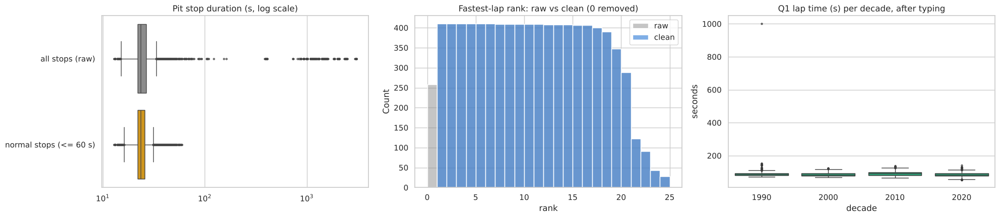

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
# (a) pit stops: all vs normal stops only
pit_s = pit_stops['milliseconds'] / 1000
sns.boxplot(data=pd.DataFrame({'all stops (raw)': pit_s, 'normal stops (<= 60 s)': pit_s[~pit_stops['is_long_stop']]}),
            orient='h', ax=axes[0], palette=[GREY, YELLOW], flierprops={'markersize': 2})
axes[0].set_xscale('log'); axes[0].set_title('Pit stop duration (s, log scale)')

# (b) fastest-lap rank before / after the rank = 0 fix
sns.histplot(res_num['rank'].dropna(), bins=range(0, 26), ax=axes[1], color=GREY, label='raw', alpha=0.5)
sns.histplot(results['rank'].dropna(), bins=range(0, 26), ax=axes[1], color=BLUE, label='clean', alpha=0.6)
axes[1].set_title('Fastest-lap rank: raw vs clean (0 removed)'); axes[1].legend()

# (c) qualifying Q1 time in seconds (now numeric), per decade
q_year = qualifying.merge(races[['raceId', 'year']], on='raceId')
sns.boxplot(x=(q_year['year'] // 10 * 10), y=q_year['q1_s'], ax=axes[2], color=GREEN, flierprops={'markersize': 2})
axes[2].set_title('Q1 lap time (s) per decade, after typing'); axes[2].set_xlabel('decade'); axes[2].set_ylabel('seconds')
plt.tight_layout(); plt.show()

**Effect of cleaning (plots)**
- **Pit stops:** after leaving out stops above 60 s, the distribution is compact (≈ 20–35 s) instead of stretching to
  51 minutes.
- **Fastest-lap rank:** the false bar at 0 is gone; ranks now start at 1.
- **Q1 time:** now numeric and comparable across decades (≈ 75–100 s); the single 1,002 s value is the source error
  mentioned in 3.2.

## 4.2 The target and the grid

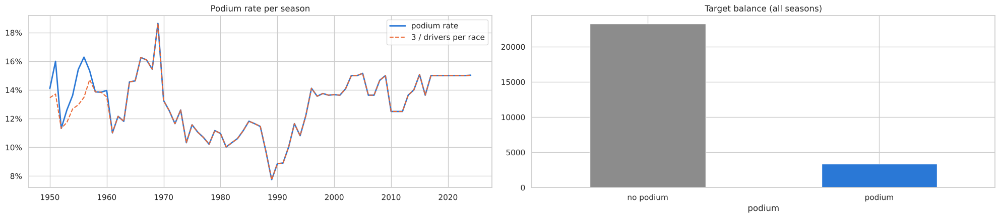

podium rate: 12.7% overall | 14.3% since 2003


In [23]:
res_year = results.merge(races[['raceId', 'year', 'round', 'circuitId', 'is_indy500']], on='raceId')
per_season = res_year.groupby('year').agg(podium_rate=('podium', 'mean'), rows=('podium', 'size'),
                                          races=('raceId', 'nunique'))
per_season['drivers_per_race'] = per_season['rows'] / per_season['races']

fig, axes = plt.subplots(1, 2, figsize=(20, 4.5))
axes[0].plot(per_season.index, per_season['podium_rate'], color=BLUE, linewidth=2, label='podium rate')
axes[0].plot(per_season.index, 3 / per_season['drivers_per_race'], color=ORANGE, linestyle='--', label='3 / drivers per race')
axes[0].set_title('Podium rate per season'); axes[0].legend()
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
results['podium'].value_counts().rename({0: 'no podium', 1: 'podium'}).plot(kind='bar', ax=axes[1], color=[GREY, BLUE])
axes[1].set_title('Target balance (all seasons)'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
print(f"podium rate: {results['podium'].mean():.1%} overall | {res_year.loc[res_year['year'] >= 2003, 'podium'].mean():.1%} since 2003")

**Observations**
- The podium rate follows **3 / drivers per race** almost exactly: it is high when fields are small (1969: 18 %) and
  low with the huge fields of the late 1980s (1989: 8 %). Since 2003 it is stable around **14–15 %** (20–22 cars).
- In a few 1950s races more than 3 drivers have `positionOrder ≤ 3`: two drivers who shared the 3rd-placed car are
  both credited with the result. They are kept as podiums (the official classification).
- **Imbalance:** only 12.7 % of all rows are podiums. Accuracy would look good by always predicting "no podium"
  (87 %), so PR-AUC / F1 are used later.

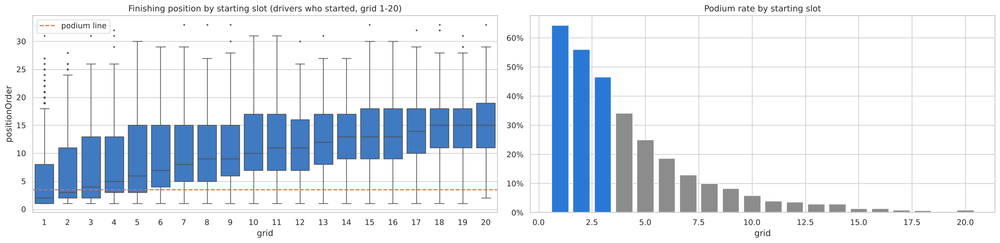

grid,1,2,3,4,5,6,7,8
podium rate,0.644,0.56,0.466,0.343,0.251,0.187,0.131,0.1


In [24]:
started = res_year[res_year['started'] & (res_year['grid'] >= 1) & (res_year['grid'] <= 20)]
fig, axes = plt.subplots(1, 2, figsize=(20, 5))
sns.boxplot(data=started, x='grid', y='positionOrder', ax=axes[0], color=BLUE, flierprops={'markersize': 1.5})
axes[0].axhline(3.5, color=ORANGE, linestyle='--', label='podium line'); axes[0].legend()
axes[0].set_title('Finishing position by starting slot (drivers who started, grid 1-20)')
grid_rate = started.groupby('grid')['podium'].mean()
axes[1].bar(grid_rate.index, grid_rate.values, color=[BLUE if g <= 3 else GREY for g in grid_rate.index])
axes[1].set_title('Podium rate by starting slot'); axes[1].set_xlabel('grid')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()
grid_rate.head(8).round(3).to_frame('podium rate').T

**Observations**
- **Starting position is the strongest single fact:** pole gives a **64 %** podium rate, P2 56 %, P3 47 %, P5 25 %,
  P8 only 10 %.
- The box plots show finishing positions spread widely for every slot (retirements, strategy), but the median finish
  rises steadily with the grid slot. A podium from outside the top 8 is rare.

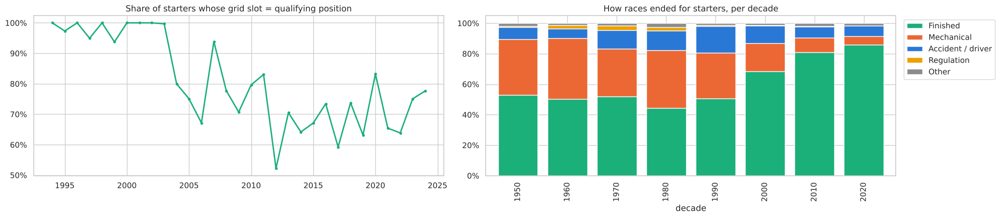

year,1994,2000,2005,2010,2014,2019,2024
grid = qualifying,1.0,1.0,0.75,0.8,0.64,0.63,0.78


category,Accident / driver,Finished,Mechanical,Other,Regulation
year,,,,,
1950,0.08,0.53,0.36,0.02,0.01
1960,0.07,0.50,0.40,0.01,0.02
1970,0.12,0.52,0.32,0.02,0.03
1980,0.13,0.44,0.38,0.03,0.03
1990,0.17,0.51,0.30,0.01,0.01
2000,0.11,0.68,0.18,0.01,0.01
2010,0.07,0.81,0.10,0.02,0.00
2020,0.07,0.86,0.06,0.01,0.00


In [25]:
# Grid vs qualifying: how often does a driver start where he qualified?  (seasons with qualifying data)
gq = res_year.merge(qualifying[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'}),
                    on=['raceId', 'driverId'])
gq = gq[gq['started'] & (gq['grid'] > 0)]
same = gq.assign(same=gq['grid'] == gq['quali_pos']).groupby('year')['same'].mean()

# Why rows stop: status category share per decade (drivers who started)
st = res_year[res_year['started']].merge(status[['statusId', 'category']], on='statusId')
mix = pd.crosstab(st['year'] // 10 * 10, st['category'], normalize='index')

fig, axes = plt.subplots(1, 2, figsize=(20, 4.5))
axes[0].plot(same.index, same.values, color=GREEN, linewidth=2, marker='o', markersize=3)
axes[0].set_title('Share of starters whose grid slot = qualifying position')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
mix[['Finished', 'Mechanical', 'Accident / driver', 'Regulation', 'Other']].plot(
    kind='bar', stacked=True, ax=axes[1], color=[GREEN, ORANGE, BLUE, YELLOW, GREY], width=0.8)
axes[1].set_title('How races ended for starters, per decade'); axes[1].set_xlabel('decade')
axes[1].legend(bbox_to_anchor=(1.01, 1), loc='upper left')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()
display(same.loc[[1994, 2000, 2005, 2010, 2014, 2019, 2024]].round(2).to_frame('grid = qualifying').T)
mix.round(2)

**Observations**
- Until ~2003 grid and qualifying are almost always the same. In the modern era they differ for **20–37 % of
  starters** (2014: only 64 % start where they qualified): engine/gearbox penalties, pit-lane starts after parc-fermé
  changes, and everyone behind moving up one place. → `grid_pos` and `quali_position` carry different information
  (Q1 and 6.6).
- **Reliability changed the sport:** mechanical failures ended 32–40 % of starts from the 1950s to the 1980s, but
  only 6 % in the 2020s, while the finish rate rose from ~50 % to 86 %. Old seasons are much more random, which is
  one reason to train on recent seasons later.

# 5. Data-engineering questions
Common choices for all three questions:
- **Grain:** one row per (`raceId`, `driverId`) from the cleaned `results` (3.3).
- **Indianapolis 500 excluded** (3.6): a different series' drivers on an oval.
- Only **drivers who started** (3.4), because a driver who never took the start cannot convert a grid slot or
  retire with a broken car.
- Every rate is shown with its number of cases; groups with few cases are left out (stated per question).

## Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?
**Joins:** `results` → `races` (year, circuit) → `circuits` (name), and `results` → `qualifying` (qualifying
position). **Front row = slot 1 or 2.** Measured twice, because the brief asks to distinguish them:
- by **grid** (where the car actually started, after penalties);
- by **qualifying position** (pace on Saturday, before penalties).

**Eras:** 1994–2013 vs 2014–2024 (hybrid era). The earlier era starts in 1994 because qualifying data starts then
(2.5), so both definitions use the same seasons. A circuit needs **≥ 10 front-row starts in each era**.

In [26]:
base = (results[results['started']]
        .merge(races[['raceId', 'year', 'circuitId', 'is_indy500']], on='raceId')
        .merge(circuits[['circuitId', 'name']].rename(columns={'name': 'circuit'}), on='circuitId')
        .merge(qualifying[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'}),
               on=['raceId', 'driverId'], how='left'))
base = base[~base['is_indy500'] & (base['year'] >= 1994)]
base['era'] = np.where(base['year'] >= 2014, '2014-2024', '1994-2013')

def front_row_conversion(df, slot_col, min_starts=10):
    front = df[df[slot_col].isin([1, 2])]
    table = front.pivot_table(index='circuit', columns='era', values='podium', aggfunc=['mean', 'size'])
    table.columns = [f'{stat} {era}' for stat, era in table.columns]
    table = table.rename(columns=lambda c: c.replace('mean', 'rate').replace('size', 'starts'))
    table = table[(table['starts 1994-2013'] >= min_starts) & (table['starts 2014-2024'] >= min_starts)]
    table[['starts 1994-2013', 'starts 2014-2024']] = table[['starts 1994-2013', 'starts 2014-2024']].astype(int)
    table['rank 1994-2013'] = table['rate 1994-2013'].rank(ascending=False, method='min')
    table['rank 2014-2024'] = table['rate 2014-2024'].rank(ascending=False, method='min')
    return table.sort_values('rank 2014-2024')

q1_grid = front_row_conversion(base, 'grid')
q1_quali = front_row_conversion(base[base['quali_pos'].notna()], 'quali_pos')
for name, t in [('grid', q1_grid), ('qualifying', q1_quali)]:
    r = t['rate 1994-2013'].corr(t['rate 2014-2024'], method='spearman')
    print(f'front row by {name:10s}: {len(t)} circuits | rank correlation between eras = {r:.2f}')
q1_grid.round(2)

front row by grid      : 15 circuits | rank correlation between eras = -0.04
front row by qualifying: 14 circuits | rank correlation between eras = 0.14


,rate 1994-2013,rate 2014-2024,starts 1994-2013,starts 2014-2024,rank 1994-2013,rank 2014-2024
circuit,,,,,,
Circuit de Monaco,0.65,0.89,40,19,5.0,1.0
Suzuka Circuit,0.75,0.89,36,18,1.0,2.0
Yas Marina Circuit,0.60,0.86,10,22,10.0,3.0
Circuit de Barcelona-Catalunya,0.67,0.82,39,22,3.0,4.0
Circuit de Spa-Francorchamps,0.50,0.82,36,22,15.0,4.0
Autódromo José Carlos Pace,0.55,0.79,40,19,14.0,6.0
Shanghai International Circuit,0.65,0.79,20,14,5.0,7.0
Circuit Gilles Villeneuve,0.58,0.78,38,18,12.0,8.0
Silverstone Circuit,0.62,0.75,40,24,9.0,9.0


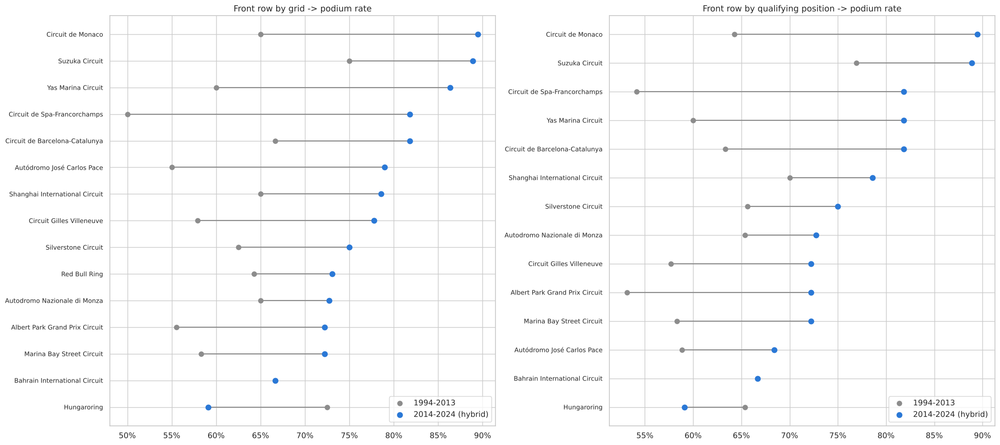

,front row by grid,front row by qualifying
era,,
1994-2013,0.646,0.649
2014-2024,0.762,0.742


front-row qualifiers who did NOT start on the front row (penalties): 36 | started on the front row without qualifying there: 36 | front-row starts with qualifying data: 983


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(20, 9), sharey=False)
for ax, (name, t) in zip(axes, [('grid', q1_grid), ('qualifying position', q1_quali)]):
    t = t.sort_values('rate 2014-2024')
    y = np.arange(len(t))
    ax.hlines(y, t['rate 1994-2013'], t['rate 2014-2024'], color=GREY, linewidth=1.5)
    ax.scatter(t['rate 1994-2013'], y, color=GREY, s=45, label='1994-2013', zorder=3)
    ax.scatter(t['rate 2014-2024'], y, color=BLUE, s=55, label='2014-2024 (hybrid)', zorder=3)
    ax.set_yticks(y); ax.set_yticklabels(t.index, fontsize=9)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.set_title(f'Front row by {name} -> podium rate'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

overall = base.assign(fr_grid=base['grid'].isin([1, 2]), fr_quali=base['quali_pos'].isin([1, 2]))
summary = pd.DataFrame({'front row by grid': overall[overall['fr_grid']].groupby('era')['podium'].mean(),
                        'front row by qualifying': overall[overall['fr_quali']].groupby('era')['podium'].mean()})
display(summary.round(3))
with_q = overall[overall['quali_pos'].notna()]                    # rows where both are known
print('front-row qualifiers who did NOT start on the front row (penalties):',
      int((with_q['fr_quali'] & ~with_q['fr_grid']).sum()),
      '| started on the front row without qualifying there:', int((~with_q['fr_quali'] & with_q['fr_grid']).sum()),
      '| front-row starts with qualifying data:', int(with_q['fr_grid'].sum()))

**Answer Q1**
- **2014–2024, by grid:** **Monaco (89 %)**, **Suzuka (89 %)** and **Yas Marina (86 %)** convert a front-row start
  into a podium most often; **Hungaroring (59 %)** least often among the 15 circuits.
- **Does the ranking change after 2014? Yes, almost completely.** The rank correlation between the two eras is
  **−0.04 (grid)** and **0.14 (qualifying)**, i.e. a circuit's rank before 2014 says almost nothing about its rank
  after. Example: Hungaroring was **2nd** in 1994–2013 (72 %) and is **last** in 2014–2024. Only Suzuka stays at
  the top in both eras.
- **The level rose for almost every circuit:** front-row conversion went from **65 % → 76 %** (grid) and
  65 % → 74 % (qualifying). In the hybrid era one or two teams dominated (Mercedes, then Red Bull) and reliability
  improved (4.2), so a front-row car was rarely beaten.
- **Grid vs qualifying:** of 983 front-row starts with qualifying data, 36 qualifiers lost the front row through a
  penalty and 36 drivers moved onto it. The two rankings are therefore similar but not identical (e.g. Spa is 4th by
  grid and 3rd by qualifying).

**Grain / missingness / cutoff:** one row per starter per race; qualifying is missing for parts of 1996–2002 (2.5),
so the qualifying version uses fewer rows; grid and qualifying are both known before the race.

**What this means for the model**
- Starting at the front converts to a podium only 59–89 % of the time, so even the best pre-race fact leaves
  uncertainty: the model needs more than the grid (form, car, reliability).
- **Grid and qualifying disagree for some front-row starters** → both are kept (`grid_pos`, `quali_position`) plus
  their difference (`grid_penalty_delta`); B3 tests whether the difference matters.
- **The conversion rate moved between eras and circuit rankings did not survive 2014** → a fixed "circuit
  conversion rate" feature would be unstable, so we do not add one; the circuit enters only through the driver's own
  history there (`driver_avg_pos_at_circuit`, tested in B4). The era shift is also a reason to test which seasons to
  train on in the modelling part.

## Q2. Do drivers podium more often at home, after controlling for starting position?
**Joins:** `results` → `races` → `circuits` (country) and `results` → `drivers` (nationality). A nationality is mapped
to a country (`British` → `UK`, …); nationalities without an F1 circuit at home never count as home.

**Controlling for the start:** home drivers might simply start further forward. So we compare home and away drivers
**on the same grid slot** and average the differences, weighting each slot by how many home starts it has
(standardisation). The 95 % interval comes from resampling whole races 1,000 times (a bootstrap), because drivers in
the same race are not independent.

In [28]:
NATIONALITY_TO_COUNTRY = {
    'British': 'UK', 'German': 'Germany', 'East German': 'Germany', 'Spanish': 'Spain', 'Finnish': 'Finland',
    'Japanese': 'Japan', 'French': 'France', 'Polish': 'Poland', 'Brazilian': 'Brazil', 'Italian': 'Italy',
    'Australian': 'Australia', 'Austrian': 'Austria', 'American': 'USA', 'Dutch': 'Netherlands',
    'Colombian': 'Colombia', 'Portuguese': 'Portugal', 'Canadian': 'Canada', 'Indian': 'India',
    'Hungarian': 'Hungary', 'Irish': 'Ireland', 'Danish': 'Denmark', 'Argentine': 'Argentina',
    'Belgian': 'Belgium', 'South African': 'South Africa', 'Swiss': 'Switzerland', 'Swedish': 'Sweden',
    'Mexican': 'Mexico', 'Russian': 'Russia', 'Chinese': 'China', 'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand', 'Malaysian': 'Malaysia'}

home_df = (results[results['started'] & (results['grid'] >= 1)]
           .merge(races[['raceId', 'year', 'circuitId', 'is_indy500']], on='raceId')
           .merge(circuits[['circuitId', 'country']], on='circuitId')
           .merge(drivers[['driverId', 'nationality']], on='driverId'))
home_df = home_df[~home_df['is_indy500']].copy()
home_df['home'] = (home_df['nationality'].map(NATIONALITY_TO_COUNTRY) == home_df['country']).astype(int)
home_df['slot'] = home_df['grid'].clip(upper=20)                  # slots above 20 pooled

def adjusted_home_effect(df):
    # podium-rate difference home - away on the SAME grid slot, weighted by home starts per slot
    rates = df.pivot_table(index='slot', columns='home', values='podium', aggfunc='mean').dropna()
    weights = df[df['home'] == 1].groupby('slot').size().reindex(rates.index)
    return np.average(rates[1] - rates[0], weights=weights)

raw_gap = home_df.groupby('home')['podium'].mean()
rng = np.random.default_rng(42)
race_groups = {race: g for race, g in home_df.groupby('raceId')}
race_ids = np.array(list(race_groups))
boot = [adjusted_home_effect(pd.concat([race_groups[r] for r in rng.choice(race_ids, len(race_ids))]))
        for _ in range(1000)]

print('home starts:', int(home_df['home'].sum()), '| away starts:', int((home_df['home'] == 0).sum()))
print(f"raw podium rate: home {raw_gap[1]:.1%} vs away {raw_gap[0]:.1%}  (difference {raw_gap[1] - raw_gap[0]:+.1%})")
print('average grid slot: home', round(home_df.loc[home_df['home'] == 1, 'grid'].mean(), 2),
      '| away', round(home_df.loc[home_df['home'] == 0, 'grid'].mean(), 2))
print(f"same-grid-slot difference: {adjusted_home_effect(home_df):+.1%}  "
      f"(95% interval {np.percentile(boot, 2.5):+.1%} to {np.percentile(boot, 97.5):+.1%})")

home starts: 1926 | away starts: 22578
raw podium rate: home 11.9% vs away 13.9%  (difference -1.9%)
average grid slot: home 12.69 | away 11.69
same-grid-slot difference: -0.2%  (95% interval -1.4% to +1.0%)


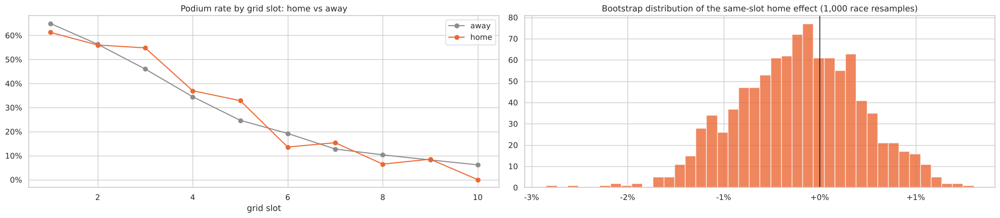

slot,1,2,3,4,5,6,7,8,9,10
away rate,0.650,0.563,0.460,0.345,0.247,0.192,0.128,0.103,0.082,0.062
home rate,0.612,0.560,0.548,0.370,0.329,0.136,0.154,0.065,0.085,0.000
home starts,80.000,75.000,73.000,73.000,70.000,81.000,78.000,77.000,94.000,86.000


In [29]:
by_slot = home_df.pivot_table(index='slot', columns='home', values='podium', aggfunc='mean').loc[1:10]
counts = home_df[home_df['home'] == 1].groupby('slot').size().loc[1:10]
fig, axes = plt.subplots(1, 2, figsize=(20, 4.5))
axes[0].plot(by_slot.index, by_slot[0], marker='o', color=GREY, label='away')
axes[0].plot(by_slot.index, by_slot[1], marker='o', color=ORANGE, label='home')
axes[0].set_title('Podium rate by grid slot: home vs away'); axes[0].set_xlabel('grid slot'); axes[0].legend()
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axes[1].hist(boot, bins=40, color=ORANGE, alpha=0.8)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Bootstrap distribution of the same-slot home effect (1,000 race resamples)')
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:+.0%}'))
plt.tight_layout(); plt.show()
pd.DataFrame({'away rate': by_slot[0], 'home rate': by_slot[1], 'home starts': counts}).round(3).T

**Answer Q2: no — there is no home advantage once the starting position is controlled for.**
- **Raw comparison:** home drivers podium *less* often (11.9 % vs 13.9 %). But they also start further back on
  average (grid 12.7 vs 11.7): many home starts are local drivers in weaker cars (e.g. one-off entries at their home
  GP).
- **Same grid slot:** the difference is **−0.2 percentage points**, with a 95 % interval of **−1.4 to +1.0** points.
  The interval contains 0, so the data shows no home effect. The slot-by-slot plot shows home and away curves
  crossing each other with no consistent gap.
- This is why `is_home_race` is not expected to help the model (7.3).

**Grain / missingness / cutoff:** one row per starter (grid ≥ 1); nationalities without an F1 home circuit count as
away; nationality and circuit country are known before the race.

**What this means for the model:** `is_home_race` has no effect once the grid is known, so it is **dropped** from the
model features (7.7). It stays in the table only because Q2 needs it.

## Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?
**Joins:** `results` → `status` (category from 3.5) → `races` (season) → `constructors` (name).
**Rate = mechanical retirements / race starts** of that constructor in the period (non-starters excluded, 3.4).
Constructors need **≥ 40 starts in a period** (about one season with two cars), so a team with a handful of
races cannot top the list by chance. Renamed teams keep separate `constructorId`s in the data (e.g. Toro Rosso →
AlphaTauri → RB), so they appear as separate rows.

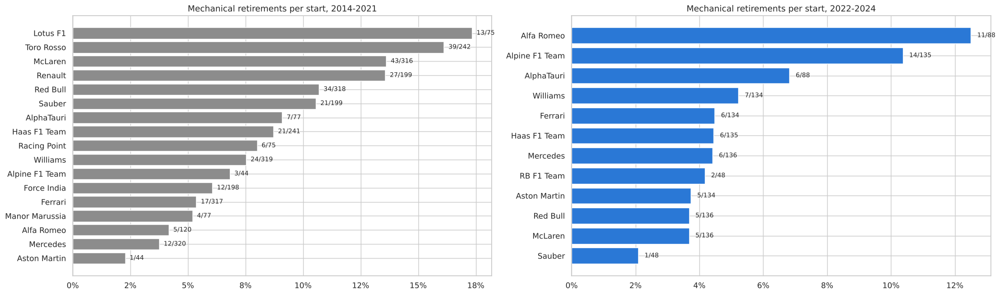

,starts,mechanical,rate
period,,,
2014-2021,3245,299,0.092
2022-2024,1352,74,0.055


,period,constructor,starts,mechanical,rate
7,2014-2021,Lotus F1,75,13,0.173
15,2014-2021,Toro Rosso,242,39,0.161
9,2014-2021,McLaren,316,43,0.136
17,2022-2024,Alfa Romeo,88,11,0.125
19,2022-2024,Alpine F1 Team,135,14,0.104
18,2022-2024,AlphaTauri,88,6,0.068


In [30]:
mech = (results[results['started']]
        .merge(status[['statusId', 'category']], on='statusId')
        .merge(races[['raceId', 'year']], on='raceId')
        .merge(constructors[['constructorId', 'name']].rename(columns={'name': 'constructor'}), on='constructorId'))
mech = mech[mech['year'].between(2014, 2024)].copy()
mech['period'] = np.where(mech['year'] <= 2021, '2014-2021', '2022-2024')
mech['mechanical'] = (mech['category'] == 'Mechanical').astype(int)

q3 = mech.groupby(['period', 'constructor']).agg(starts=('mechanical', 'size'), mechanical=('mechanical', 'sum'))
q3['rate'] = q3['mechanical'] / q3['starts']
q3 = q3[q3['starts'] >= 40].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for ax, (period, t), color in zip(axes, q3.groupby('period'), [GREY, BLUE]):
    t = t.sort_values('rate')
    ax.barh(t['constructor'], t['rate'], color=color)
    for y, (rate, n, s) in enumerate(zip(t['rate'], t['mechanical'], t['starts'])):
        ax.text(rate + 0.002, y, f'{n}/{s}', va='center', fontsize=9)
    ax.set_title(f'Mechanical retirements per start, {period}')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()
display(mech.groupby('period')['mechanical'].agg(['size', 'sum', 'mean']).rename(
    columns={'size': 'starts', 'sum': 'mechanical', 'mean': 'rate'}).round(3))
q3.sort_values(['period', 'rate'], ascending=[True, False]).groupby('period').head(3).round(3)

**Answer Q3**
- **2014–2021:** **Lotus F1 (17 %, 13 / 75 starts)**, **Toro Rosso (16 %)** and **McLaren (14 %)** — McLaren's
  rate covers its Honda power-unit years (2015–2017), which were famous for failures. Renault is level with McLaren.
- **2022–2024:** **Alfa Romeo (12.5 %, 11 / 88)**, **Alpine (10 %)** and **AlphaTauri (7 %)**.
- **Reliability improved overall:** 9.2 % of starts ended with a mechanical failure in 2014–2021, 5.5 % in 2022–2024.
  McLaren went from one of the worst (14 %) to one of the best (3.7 %).
- Mercedes was the most reliable large team in 2014–2021 (3.8 %, 12 / 320). Small samples (e.g. Aston Martin 1 / 44 in
  2014–2021, its first season) should not be over-read.

**Grain / missingness / cutoff:** one row per starter; non-starters are excluded from the denominator; status is a
post-race field, so it is used **only** for this question, never as a model feature.

**What this means for the model**
- About 1 in 11 starts (2014–2021) ended with a broken car, and it depended strongly on the team. This is a large
  part of the uncertainty that no pre-race feature can remove: a front-row car can still break down.
- The team's recent **best finish** (`constructor_avg_pos_last_5`) and its standings already reflect both speed and
  reliability, because a broken car scores nothing. A separate reliability feature (a team's rolling mechanical-DNF
  rate from earlier races) would also be leakage-safe and is a possible extension.
- Reliability changed a lot over time (32–40 % failures per start before the 1990s, 6 % in the 2020s, 4.2), so old
  seasons are much noisier: one more reason the training window is tested in the modelling part.

# 6. Feature engineering: the modelling table
One row per (`raceId`, `driverId`). Every feature must be **known before the start** (after qualifying):

| Source | What we may use | Why it is allowed |
|---|---|---|
| this race | `grid`, qualifying position | fixed before the lights go out |
| earlier races | results, lap positions, fastest-lap ranks, pit stops | computed with `shift(1)`: only races *before* this one |
| standings | points / wins **after the previous round** | the standings row of this race already contains its result, so it is shifted by one |

Not allowed (leakage): this race's `positionOrder`, points, laps, status, fastest lap, lap times, pit stops and the
standings row of this race.

The time order is always **season, then round** (`race_year`, `race_round`), never `raceId`: race ids are not in
date order (2.2 / `races` table).

## 6.1 Per-race summaries of the session tables
Lap times and pit stops have many rows per driver per race. They are reduced to one value per (`raceId`,
`driverId`) — the average running position and the average **normal** pit stop (3.6) — and only used later through
`shift(1)`, i.e. from previous races.

In [31]:
# race_year / race_round: the names used in the modelling table
race_info = races[['raceId', 'year', 'round', 'circuitId']].rename(columns={'year': 'race_year', 'round': 'race_round'})

race_lap_avg = lap_times.groupby(['raceId', 'driverId'])['position'].mean().reset_index(name='race_avg_lap_pos')
pit_avg = (pit_stops[~pit_stops['is_long_stop']]                       # red flags / repairs excluded (3.6)
           .groupby(['raceId', 'driverId'])['milliseconds'].mean().reset_index(name='race_avg_pit_ms'))
print('lap summaries:', race_lap_avg.shape, '| pit summaries:', pit_avg.shape)

lap summaries: (11041, 3) | pit summaries: (5531, 3)


## 6.2 Driver form and career (from earlier races only)
Inside each driver's own races, sorted in time:
- **recent form:** previous finish, previous podium, 5-race averages of finish, running position and fastest-lap rank,
  average pit time;
- **career:** average finish, podium count and number of earlier races;
- **track history:** average finish at *this* circuit in earlier visits.

`groupby(...).transform(lambda s: s.shift(1).rolling(...))` keeps the shift **and** the window inside one driver.
(An earlier version applied `.rolling()` after the grouping had ended, so windows ran across different drivers.)

In [32]:
driver_form = results[['raceId', 'driverId', 'positionOrder', 'podium', 'rank']].copy()
driver_form = driver_form.merge(race_info, on='raceId')
driver_form = driver_form.merge(race_lap_avg, on=['raceId', 'driverId'], how='left')
driver_form = driver_form.merge(pit_avg, on=['raceId', 'driverId'], how='left')
driver_form = driver_form.sort_values(['driverId', 'race_year', 'race_round'])

g = driver_form.groupby('driverId')                      # every calculation stays inside one driver's races
last5 = lambda s: s.shift(1).rolling(5, min_periods=1).mean()

# --- recent form ---
driver_form['driver_prev_position'] = g['positionOrder'].shift(1)
driver_form['driver_prev_podium'] = g['podium'].shift(1).fillna(0)
driver_form['driver_avg_pos_last_5'] = g['positionOrder'].transform(last5)
driver_form['driver_avg_lap_pos_last_5'] = g['race_avg_lap_pos'].transform(last5)
driver_form['driver_avg_pit_ms_last_5'] = g['race_avg_pit_ms'].transform(last5)
driver_form['driver_avg_speed_rank_last_5'] = g['rank'].transform(last5)

# --- career (all earlier races) ---
driver_form['driver_career_avg_pos'] = g['positionOrder'].transform(lambda s: s.shift(1).expanding().mean())
driver_form['driver_career_podiums'] = g['podium'].transform(lambda s: s.shift(1).cumsum()).fillna(0)
driver_form['driver_career_races'] = g.cumcount()                    # number of EARLIER races (0 on debut)

# --- track history: earlier visits to THIS circuit ---
g_circuit = driver_form.groupby(['driverId', 'circuitId'])
driver_form['driver_avg_pos_at_circuit'] = g_circuit['positionOrder'].transform(lambda s: s.shift(1).expanding().mean())

driver_form = driver_form[['raceId', 'driverId', 'driver_prev_position', 'driver_prev_podium',
                           'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5', 'driver_avg_pit_ms_last_5',
                           'driver_avg_speed_rank_last_5', 'driver_career_avg_pos', 'driver_career_podiums',
                           'driver_career_races', 'driver_avg_pos_at_circuit']]
driver_form.describe().T[['count', 'mean', 'min', 'max']].round(2)

,count,mean,min,max
raceId,26668.0,550.86,1.00,1144.0
driverId,26668.0,277.71,1.00,862.0
driver_prev_position,25807.0,12.61,1.00,39.0
driver_prev_podium,26668.0,0.13,0.00,1.0
driver_avg_pos_last_5,25807.0,12.62,1.00,39.0
driver_avg_lap_pos_last_5,11344.0,10.02,1.05,24.0
driver_avg_pit_ms_last_5,5892.0,24639.84,19612.00,55789.0
driver_avg_speed_rank_last_5,8538.0,10.62,1.00,23.0
driver_career_avg_pos,25807.0,13.01,1.00,39.0
driver_career_podiums,26668.0,12.45,0.00,202.0


## 6.3 Championship standings before the race
`driver_standings` / `constructor_standings` give the totals **after** each race. Shifting by one row inside the same
driver (team) **and season** gives the totals before the race; the first race of a season starts at 0.
`won_previous_race` = the season win count went up by one at the previous round.

In [33]:
ds = driver_standings.merge(race_info, on='raceId').sort_values(['driverId', 'race_year', 'race_round'])
gs = ds.groupby(['driverId', 'race_year'])
ds['pre_race_points'] = gs['points'].shift(1).fillna(0)
ds['pre_race_wins'] = gs['wins'].shift(1).fillna(0)
ds['won_previous_race'] = ds.groupby(['driverId', 'race_year'])['pre_race_wins'].diff().fillna(0)
ds = ds[['raceId', 'driverId', 'pre_race_points', 'pre_race_wins', 'won_previous_race']]

cs = constructor_standings.merge(race_info, on='raceId').sort_values(['constructorId', 'race_year', 'race_round'])
gcs = cs.groupby(['constructorId', 'race_year'])
cs['pre_race_constructor_points'] = gcs['points'].shift(1).fillna(0)
cs['pre_race_constructor_wins'] = gcs['wins'].shift(1).fillna(0)
cs = cs[['raceId', 'constructorId', 'pre_race_constructor_points', 'pre_race_constructor_wins']]
print('driver standings rows:', len(ds), '| constructor standings rows:', len(cs))

driver standings rows: 34863 | constructor standings rows: 13391


## 6.4 Constructor (car) form
Per race the team is summarised by its **best finish** and its **number of podiums**, then shifted inside the team.

In [34]:
team_race = (results[['raceId', 'constructorId', 'positionOrder', 'podium']].merge(race_info, on='raceId')
             .groupby(['raceId', 'constructorId', 'race_year', 'race_round'])
             .agg(positionOrder=('positionOrder', 'min'), podium=('podium', 'sum')).reset_index()
             .sort_values(['constructorId', 'race_year', 'race_round']))
gt = team_race.groupby('constructorId')
team_race['constructor_prev_pos'] = gt['positionOrder'].shift(1)
team_race['constructor_avg_pos_last_5'] = gt['positionOrder'].transform(last5)
team_race['constructor_career_podiums'] = gt['podium'].transform(lambda s: s.shift(1).cumsum()).fillna(0)
constructor_form = team_race[['raceId', 'constructorId', 'constructor_prev_pos', 'constructor_avg_pos_last_5',
                              'constructor_career_podiums']]
constructor_form.describe().T[['count', 'mean', 'min', 'max']].round(2)

,count,mean,min,max
raceId,13024.0,536.91,1.0,1144.0
constructorId,13024.0,47.73,1.0,215.0
constructor_prev_pos,12814.0,9.90,1.0,38.0
constructor_avg_pos_last_5,12814.0,9.90,1.0,37.0
constructor_career_podiums,13024.0,90.10,0.0,837.0


## 6.5 Assemble the base table
Start from the cleaned `results` (already one row per driver per race) and add everything with **left joins** on the
keys, so no row can be lost or duplicated (checked at the end).

In [35]:
final_df = results[['raceId', 'driverId', 'constructorId', 'grid', 'podium']].copy()
final_df = final_df.merge(race_info, on='raceId', how='left')
final_df = final_df.merge(qualifying[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_position'}),
                          on=['raceId', 'driverId'], how='left')
final_df = final_df.merge(drivers[['driverId', 'nationality']].rename(columns={'nationality': 'driver_nationality'}),
                          on='driverId', how='left')
final_df = final_df.merge(circuits[['circuitId', 'country']].rename(columns={'country': 'circuit_country'}),
                          on='circuitId', how='left')
final_df = final_df.merge(constructors[['constructorId', 'name']].rename(columns={'name': 'constructor_name'}),
                          on='constructorId', how='left')
final_df = final_df.merge(driver_form, on=['raceId', 'driverId'], how='left')
final_df = final_df.merge(ds, on=['raceId', 'driverId'], how='left')
final_df = final_df.merge(constructor_form, on=['raceId', 'constructorId'], how='left')
final_df = final_df.merge(cs, on=['raceId', 'constructorId'], how='left')

# home race: same nationality -> country map as in Q2
final_df['is_home_race'] = (final_df['driver_nationality'].map(NATIONALITY_TO_COUNTRY)
                            == final_df['circuit_country']).astype(int)
print(final_df.shape, '| duplicate (raceId, driverId):', final_df.duplicated(['raceId', 'driverId']).sum())
missing = final_df.isna().sum()
missing[missing > 0].rename('missing before filling').to_frame()

(26668, 31) | duplicate (raceId, driverId): 0


,missing before filling
quali_position,16174
driver_prev_position,861
driver_avg_pos_last_5,861
driver_avg_lap_pos_last_5,15324
driver_avg_pit_ms_last_5,20776
driver_avg_speed_rank_last_5,18130
driver_career_avg_pos,861
driver_avg_pos_at_circuit,8176
pre_race_points,469
pre_race_wins,469


**Observations (gaps before filling, all explainable)**
- `quali_position` missing for 16,174 rows: no qualifying table before 1994 and gaps in 1996–2002 (2.5).
- Lap-position / speed-rank / pit-time averages missing for 15,324 / 18,129 / 20,776 rows: these tables start in
  1996 / 2004 / 2011.
- **861 rows have no previous race = 861 drivers' debuts** (exactly one per driver).
- `driver_avg_pos_at_circuit` missing for 8,176 rows: first visits to a circuit.
- Constructor standings missing for 1,785 rows: the **Constructors' Championship only started in 1958**, so 1950–57 has
  no standings.
- The table still has one row per (`raceId`, `driverId`): the left joins added no rows.

## 6.6 Grid and qualifying features
- **`grid_pos`:** `grid = 0` means a pit-lane start or no slot (2.4). As a number 0 would look like "better than
  pole", so it is moved **behind the last car of that race** (max grid of the race + 1).
- **`quali_position`:** missing where the qualifying table has no row (before 1994 and gaps in 1996–2002, 2.5); filled
  with `grid_pos`, the closest pre-race substitute (they agree for ~90 % of starters, 4.2).
- **`grid_penalty_delta`** = `grid_pos − quali_position`: positive = starts behind where he qualified (penalty).
- **`outqualified_teammate`:** 1 = qualified ahead of every teammate, 0 = behind, **0.5 = no comparison possible**
  (no teammate in this race, or tied with him). The tie case happens when qualifying is missing for both teammates.

In [36]:
filled = final_df.isna()                     # remember which values were missing BEFORE filling (used in 7.1)
before_fill = final_df.copy()                # values before 6.6-6.8, to show the effect of each step (6.9)
filled['quali_position'] = final_df['quali_position'].isna()

last_slot = final_df.groupby('raceId')['grid'].transform('max')
final_df['grid_pos'] = final_df['grid'].where(final_df['grid'] != 0, last_slot + 1)
final_df['quali_position'] = final_df['quali_position'].fillna(final_df['grid_pos'])
final_df['grid_penalty_delta'] = final_df['grid_pos'] - final_df['quali_position']

team = final_df.groupby(['raceId', 'constructorId'])['quali_position']
is_best = final_df['quali_position'] == team.transform('min')
best_count = is_best.groupby([final_df['raceId'], final_df['constructorId']]).transform('sum')
team_size = team.transform('size')
no_comparison = (team_size == 1) | (is_best & (best_count > 1))
final_df['outqualified_teammate'] = np.select([no_comparison, is_best], [0.5, 1.0], default=0.0)

print(final_df['outqualified_teammate'].value_counts().sort_index().to_dict())
final_df[['grid', 'grid_pos', 'quali_position', 'grid_penalty_delta']].describe().round(2)

{0.0: 13361, 0.5: 2113, 1.0: 11194}


,grid,grid_pos,quali_position,grid_penalty_delta
count,26668.00,26668.00,26668.00,26668.00
mean,11.14,12.66,12.66,0.00
std,7.20,7.35,7.35,0.98
min,0.00,1.00,1.00,-9.00
25%,5.00,6.00,6.00,0.00
50%,11.00,12.00,12.00,0.00
75%,17.00,18.00,18.00,0.00
max,34.00,34.00,34.00,23.00


## 6.7 Filling the remaining gaps (each value is a pre-race fact)
| Missing because | Columns | Fill | Reason |
|---|---|---|---|
| no earlier race / season start | standings, previous podium, career podiums | **0** | nothing scored yet |
| debut (no earlier race) | previous finish, 5-race / career averages, team averages | **20** | back of a modern field: an unknown driver is not expected to podium |
| first visit to a circuit | `driver_avg_pos_at_circuit` | **his career average** | the best estimate is how he does elsewhere; 20 would call every driver a back-marker at a new track |
| table does not exist yet (lap times < 1996, fastest-lap rank < 2004) | lap position, speed rank | **20** | no information → neutral back-of-field value |
| pit stops before 2011 | `driver_avg_pit_ms_last_5` | **40,000 ms** | a slow stop (normal stops: median ≈ 23 s) |

In [37]:
ZERO_FILL = ['pre_race_points', 'pre_race_wins', 'won_previous_race', 'driver_prev_podium',
             'pre_race_constructor_points', 'pre_race_constructor_wins']
BACK_OF_FIELD = ['driver_prev_position', 'driver_avg_pos_last_5', 'driver_career_avg_pos', 'constructor_prev_pos',
                 'constructor_avg_pos_last_5', 'driver_avg_speed_rank_last_5', 'driver_avg_lap_pos_last_5']

final_df[ZERO_FILL] = final_df[ZERO_FILL].fillna(0)
final_df[BACK_OF_FIELD] = final_df[BACK_OF_FIELD].fillna(20)
final_df['driver_avg_pos_at_circuit'] = final_df['driver_avg_pos_at_circuit'].fillna(final_df['driver_career_avg_pos'])
final_df['driver_avg_pit_ms_last_5'] = final_df['driver_avg_pit_ms_last_5'].fillna(40_000)
print('missing values left:', int(final_df.isna().sum().sum()))

missing values left: 0


## 6.8 Points relative to the leader
Raw points are not comparable between seasons: a win was worth 8–10 points until 2009 and 25 since 2010 (2014 Abu
Dhabi even counted double), and early in a season everybody has few points. Dividing by the **leader's points before
this race** puts every season and round on the same 0–1 scale (1 = championship leader). Round 1: nobody has points
→ 0.

In [38]:
leader = final_df.groupby('raceId')['pre_race_points'].transform('max')
final_df['points_share'] = np.where(leader > 0, final_df['pre_race_points'] / leader, 0)
leader_c = final_df.groupby('raceId')['pre_race_constructor_points'].transform('max')
final_df['constructor_points_share'] = np.where(leader_c > 0, final_df['pre_race_constructor_points'] / leader_c, 0)
final_df[['pre_race_points', 'points_share', 'pre_race_constructor_points', 'constructor_points_share']].describe().round(2)

,pre_race_points,points_share,pre_race_constructor_points,constructor_points_share
count,26668.00,26668.00,26668.00,26668.00
mean,16.83,0.18,34.12,0.25
std,40.74,0.28,78.81,0.33
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00
50%,2.00,0.03,6.00,0.09
75%,13.00,0.25,30.00,0.39
max,549.00,1.00,822.00,1.00


## 6.9 Effect of the preprocessing steps on the data
Each step in 6.6–6.8 changes values, so we show what it did to the range and the distribution.

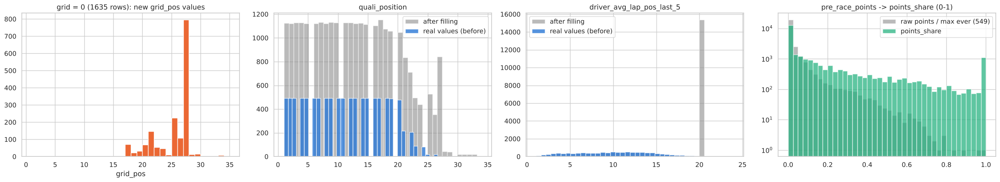

,before,after,missing before,missing after,range before,range after,mean before,mean after
0,grid,grid_pos,0,0,0.00 - 34.00,1.00 - 34.00,11.14,12.66
1,quali_position,quali_position,16174,0,1.00 - 28.00,1.00 - 34.00,11.20,12.66
2,driver_avg_pos_last_5,driver_avg_pos_last_5,861,0,1.00 - 39.00,1.00 - 39.00,12.62,12.86
3,driver_avg_lap_pos_last_5,driver_avg_lap_pos_last_5,15324,0,1.05 - 24.00,1.05 - 24.00,10.02,15.76
4,driver_avg_speed_rank_last_5,driver_avg_speed_rank_last_5,18130,0,1.00 - 23.00,1.00 - 23.00,10.62,17.00
5,driver_avg_pos_at_circuit,driver_avg_pos_at_circuit,8176,0,1.00 - 39.00,1.00 - 39.00,12.27,13.25
6,driver_avg_pit_ms_last_5,driver_avg_pit_ms_last_5,20776,0,19612.00 - 55789.00,19612.00 - 55789.00,24639.84,36606.34
7,pre_race_points,points_share,469,0,0.00 - 549.00,0.00 - 1.00,17.13,0.18


In [39]:
STEP_COLS = ['grid', 'quali_position', 'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5',
             'driver_avg_speed_rank_last_5', 'driver_avg_pos_at_circuit', 'driver_avg_pit_ms_last_5', 'pre_race_points']
AFTER_COLS = {'grid': 'grid_pos', 'pre_race_points': 'points_share'}       # these steps create a new column
step_effect = pd.DataFrame([{
    'before': col, 'after': AFTER_COLS.get(col, col),
    'missing before': int(before_fill[col].isna().sum()), 'missing after': int(final_df[AFTER_COLS.get(col, col)].isna().sum()),
    'range before': f"{before_fill[col].min():.2f} - {before_fill[col].max():.2f}",
    'range after': f"{final_df[AFTER_COLS.get(col, col)].min():.2f} - {final_df[AFTER_COLS.get(col, col)].max():.2f}",
    'mean before': round(before_fill[col].mean(), 2), 'mean after': round(final_df[AFTER_COLS.get(col, col)].mean(), 2)}
    for col in STEP_COLS])

fig, axes = plt.subplots(1, 4, figsize=(24, 4.5))
grid0 = before_fill['grid'] == 0
axes[0].hist(final_df.loc[grid0, 'grid_pos'], bins=range(1, 36), color=ORANGE)
axes[0].set_title(f'grid = 0 ({grid0.sum()} rows): new grid_pos values'); axes[0].set_xlabel('grid_pos')
for ax, col in zip(axes[1:3], ['quali_position', 'driver_avg_lap_pos_last_5']):
    ax.hist(final_df[col], bins=40, color=GREY, alpha=0.6, label='after filling')
    ax.hist(before_fill[col].dropna(), bins=40, color=BLUE, alpha=0.8, label='real values (before)')
    ax.set_title(col); ax.legend()
axes[3].hist(before_fill['pre_race_points'] / before_fill['pre_race_points'].max(), bins=40, color=GREY, alpha=0.6,
             label='raw points / max ever (549)')
axes[3].hist(final_df['points_share'], bins=40, color=GREEN, alpha=0.7, label='points_share')
axes[3].set_yscale('log'); axes[3].set_title('pre_race_points -> points_share (0-1)'); axes[3].legend()
plt.tight_layout(); plt.show()
step_effect

**Effect of each step**
- **Grid 0 → `grid_pos`:** the 1,635 rows with grid 0 now sit **behind the last car** of their race (slots 17–34)
  instead of looking like pole position; range 0–34 → 1–34.
- **`quali_position`:** 16,174 missing values filled from `grid_pos`; the mean moves from 11.2 to 12.7 because older
  seasons had larger fields. The shape stays the same (one slot per driver), only more rows.
- **Lap position / speed rank / pit time:** the fill value creates **one large spike** (20, 20, 40,000 ms) next to the
  real distribution; means move from 10.0 → 15.8 (lap position) and 10.6 → 17.0 (speed rank). The spike is the
  reason these features look weak in the all-season correlations (7.4a).
- **`driver_avg_pos_at_circuit`:** filled with the career average, so no spike appears (mean 12.3 → 13.3).
- **Points → `points_share`:** raw points span 0–549 and are squeezed near 0 for most seasons; the share spreads the
  same information over 0–1 in every season, with a visible group at 1 (the championship leaders).

## 6.10 Leakage check (only past races)
For 200 random rows, two form features are recomputed **by hand** from races strictly before the row's race
(season × 100 + round), then compared with the table.

In [40]:
hist = results[['raceId', 'driverId', 'positionOrder', 'podium']].merge(race_info, on='raceId')
hist['order'] = hist['race_year'] * 100 + hist['race_round']

checks = []
for _, row in final_df.sample(200, random_state=42).iterrows():
    now = row['race_year'] * 100 + row['race_round']
    past = hist[(hist['driverId'] == row['driverId']) & (hist['order'] < now)].sort_values('order')
    expected_avg5 = past['positionOrder'].tail(5).mean() if len(past) else 20
    checks.append({'avg_pos_last_5 matches': np.isclose(row['driver_avg_pos_last_5'], expected_avg5),
                   'career_podiums matches': row['driver_career_podiums'] == past['podium'].sum(),
                   'career_races matches': row['driver_career_races'] == len(past)})
pd.DataFrame(checks).mean().rename('share of 200 rows matching').to_frame()

,share of 200 rows matching
avg_pos_last_5 matches,1.0
career_podiums matches,1.0
career_races matches,1.0


**Result:** 200 / 200 rows match for all three checks. Every value is computed only from races before the one being
predicted, so the form and career features are leakage-safe.

## 6.11 Final table checks and export
Same 36 columns, in the same order, as our `all_features.csv`.

In [41]:
ALL_FEATURES_COLUMNS = [
    'raceId', 'driverId', 'constructorId', 'grid', 'podium', 'race_year', 'race_round', 'circuitId', 'quali_position',
    'driver_nationality', 'circuit_country', 'constructor_name', 'driver_prev_position', 'driver_prev_podium',
    'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5', 'driver_avg_pit_ms_last_5', 'driver_avg_speed_rank_last_5',
    'driver_career_avg_pos', 'driver_career_podiums', 'driver_career_races', 'driver_avg_pos_at_circuit',
    'pre_race_points', 'pre_race_wins', 'won_previous_race', 'constructor_prev_pos', 'constructor_avg_pos_last_5',
    'constructor_career_podiums', 'pre_race_constructor_points', 'pre_race_constructor_wins', 'is_home_race',
    'grid_pos', 'outqualified_teammate', 'grid_penalty_delta', 'points_share', 'constructor_points_share']

final_df = final_df[ALL_FEATURES_COLUMNS]
assert len(final_df) == len(results), 'a join added or lost rows'
assert not final_df.duplicated(['raceId', 'driverId']).any(), 'grain broken'
assert final_df.isna().sum().sum() == 0, 'missing values left'

final_df.to_csv(os.path.join(OUT_DIR, 'all_features.csv'), index=False)
print('saved all_features.csv:', final_df.shape, '| seasons', final_df['race_year'].min(), '-', final_df['race_year'].max())
final_df.head()

saved all_features.csv: (26668, 36) | seasons 1950 - 2024


,raceId,driverId,constructorId,grid,podium,race_year,race_round,circuitId,quali_position,driver_nationality,circuit_country,constructor_name,driver_prev_position,driver_prev_podium,driver_avg_pos_last_5,driver_avg_lap_pos_last_5,driver_avg_pit_ms_last_5,driver_avg_speed_rank_last_5,driver_career_avg_pos,driver_career_podiums,driver_career_races,driver_avg_pos_at_circuit,pre_race_points,pre_race_wins,won_previous_race,constructor_prev_pos,constructor_avg_pos_last_5,constructor_career_podiums,pre_race_constructor_points,pre_race_constructor_wins,is_home_race,grid_pos,outqualified_teammate,grid_penalty_delta,points_share,constructor_points_share
0,1,1,1,18,0,2009,1,1,15.0,British,Australia,McLaren,5.0,0.0,5.6,6.263638,40000.0,5.0,4.600000,22.0,35,2.000000,0.0,0.0,0.0,5.0,4.6,415.0,0.0,0.0,0,18,0.0,3.0,0.0,0.0
1,1,2,2,9,0,2009,1,1,11.0,German,Australia,BMW Sauber,10.0,0.0,7.0,8.424819,40000.0,7.6,10.576159,11.0,151,10.222222,0.0,0.0,0.0,10.0,5.2,15.0,0.0,0.0,0,9,0.0,-2.0,0.0,0.0
2,1,3,3,5,0,2009,1,1,5.0,German,Australia,Williams,12.0,0.0,10.8,10.746244,40000.0,9.4,12.283019,2.0,53,10.333333,0.0,0.0,0.0,12.0,9.8,297.0,0.0,0.0,0,5,1.0,0.0,0.0,0.0
3,1,4,4,10,0,2009,1,1,12.0,Spanish,Australia,Renault,2.0,1.0,2.4,4.252168,40000.0,5.6,7.056911,52.0,123,4.571429,0.0,0.0,0.0,2.0,2.4,94.0,0.0,0.0,0,10,1.0,-2.0,0.0,0.0
4,1,5,1,12,0,2009,1,1,14.0,Finnish,Australia,McLaren,7.0,0.0,10.8,6.344951,40000.0,9.4,8.142857,4.0,35,7.500000,0.0,0.0,0.0,5.0,4.6,415.0,0.0,0.0,0,12,1.0,-2.0,0.0,0.0


# 7. Pre-training EDA and feature selection
## 7.1 Where are the features real, and where are they fill values?
A filled value is a placeholder, not information. The share of filled rows per season shows which seasons can teach a
model what a feature means.

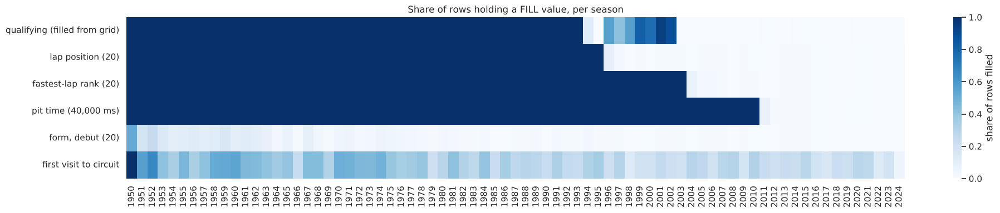

,qualifying (filled from grid),lap position (20),fastest-lap rank (20),"pit time (40,000 ms)","form, debut (20)",first visit to circuit
race_year,,,,,,
1993,1.00,1.00,1.00,1.00,0.02,0.25
1995,0.00,1.00,1.00,1.00,0.01,0.36
2002,0.88,0.02,1.00,1.00,0.01,0.22
2003,0.00,0.02,1.00,1.00,0.02,0.20
2004,0.00,0.01,0.07,1.00,0.01,0.30
2005,0.00,0.02,0.02,1.00,0.02,0.27
2010,0.00,0.01,0.01,1.00,0.01,0.31
2011,0.01,0.01,0.01,0.07,0.01,0.24
2024,0.00,0.01,0.01,0.01,0.01,0.05


In [42]:
FILL_CHECK = {'quali_position': 'qualifying (filled from grid)', 'driver_avg_lap_pos_last_5': 'lap position (20)',
              'driver_avg_speed_rank_last_5': 'fastest-lap rank (20)', 'driver_avg_pit_ms_last_5': 'pit time (40,000 ms)',
              'driver_avg_pos_last_5': 'form, debut (20)', 'driver_avg_pos_at_circuit': 'first visit to circuit'}
fill_share = (filled[list(FILL_CHECK)].groupby(final_df['race_year']).mean().rename(columns=FILL_CHECK))

fig, ax = plt.subplots(figsize=(20, 4))
sns.heatmap(fill_share.T, cmap='Blues', vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'share of rows filled'})
ax.set_title('Share of rows holding a FILL value, per season'); ax.set_xlabel('')
plt.tight_layout(); plt.show()
fill_share.loc[[1993, 1995, 2002, 2003, 2004, 2005, 2010, 2011, 2024]].round(2)

**Observations**
- Before 1994 qualifying is 100 % "filled from grid", lap position and speed rank are 100 % fill values.
- **2003 is the first season with real qualifying, real lap positions and real form** for (almost) every row; the
  fastest-lap rank becomes real in 2004 (2003 still 100 % filled) and the pit time only in 2011.
- First visits to a circuit stay frequent (20–30 % of rows) in every era: new drivers and new tracks.
- Correlations computed on all seasons therefore mix real values with placeholders. Section 7.4(a) measures how
  much this matters.

## 7.2 Feature distributions by class (all seasons, 1950–2024)
Box plots of the main features for podium vs no-podium rows, on the whole table. Fill values (7.1) are part of the
data, so features such as lap position show a block of values at exactly 20.

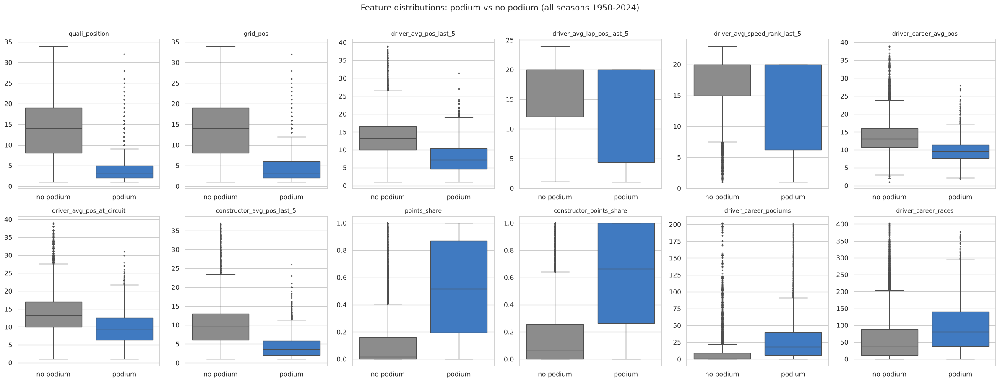

podium,median: no podium,median: podium
quali_position,14.00,3.00
grid_pos,14.00,3.00
driver_avg_pos_last_5,13.20,7.20
driver_avg_lap_pos_last_5,20.00,20.00
driver_avg_speed_rank_last_5,20.00,20.00
driver_career_avg_pos,13.01,9.56
driver_avg_pos_at_circuit,13.20,9.25
constructor_avg_pos_last_5,9.60,3.60
points_share,0.02,0.51
constructor_points_share,0.06,0.66


In [43]:
BOX_FEATURES = ['quali_position', 'grid_pos', 'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5',
                'driver_avg_speed_rank_last_5', 'driver_career_avg_pos', 'driver_avg_pos_at_circuit',
                'constructor_avg_pos_last_5', 'points_share', 'constructor_points_share',
                'driver_career_podiums', 'driver_career_races']
fig, axes = plt.subplots(2, 6, figsize=(24, 9))
for ax, col in zip(axes.ravel(), BOX_FEATURES):
    sns.boxplot(data=final_df, x='podium', y=col, ax=ax, palette=[GREY, BLUE], flierprops={'markersize': 1.5})
    ax.set_title(col, fontsize=10); ax.set_xlabel(''); ax.set_ylabel('')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['no podium', 'podium'])
plt.suptitle('Feature distributions: podium vs no podium (all seasons 1950-2024)', y=1.01, fontsize=14)
plt.tight_layout(); plt.show()
final_df.groupby('podium')[BOX_FEATURES].median().T.rename(columns={0: 'median: no podium', 1: 'median: podium'}).round(2)

**Observations (all seasons)**
- **Clear separation:** podium finishers start around **P3** (median) vs **P14**; their team's recent best finish
  averages **3.6** vs 9.6; they hold **51 %** of the leader's points vs 2 %.
- **Experience matters too:** podium finishers have a median of 18 career podiums vs 1, and 81 career races vs 39.
  Good drivers stay in F1 longer and in better cars.
- **Lap position and speed rank have a median of 20 in both classes:** more than half of all rows hold the fill value
  (no lap data before 1996, no fastest-lap rank before 2004, 7.1). The real values are compressed into the lower part
  of the box, which is why these two features look weak in the all-season matrix (checked in 7.4a).

## 7.3 Correlation matrix: all features vs the target
This is the team's correlation cell. It reads the table we just exported (`all_features.csv`) and uses **all seasons
1950–2024**, so fill values are included.

--- Correlation with podium (sorted) ---
quali_position                 -0.437
grid_pos                       -0.437
driver_avg_pos_last_5          -0.351
constructor_avg_pos_last_5     -0.331
driver_career_avg_pos          -0.289
constructor_prev_pos           -0.289
driver_prev_position           -0.274
driver_avg_pos_at_circuit      -0.232
driver_avg_lap_pos_last_5      -0.203
driver_avg_speed_rank_last_5   -0.173
driver_avg_pit_ms_last_5       -0.037
is_home_race                   -0.020
grid_penalty_delta              0.005
outqualified_teammate           0.116
driver_career_races             0.162
constructor_career_podiums      0.240
won_previous_race               0.255
driver_career_podiums           0.268
pre_race_constructor_points     0.292
pre_race_points                 0.317
driver_prev_podium              0.350
pre_race_constructor_wins       0.367
pre_race_wins                   0.370
constructor_points_share        0.410
points_share                    0.464
Name: pod

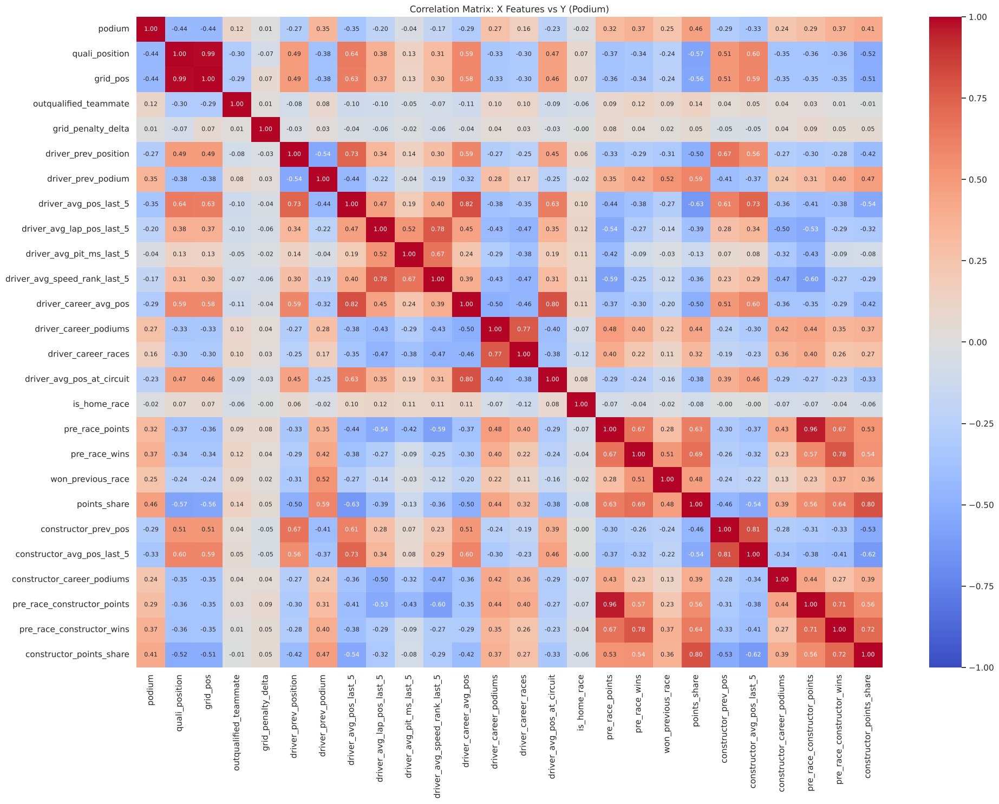

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
# 1. Define all numeric features and the target variable
selected_columns = [
    # --- Target ---
    "podium",

    # --- Grid & Qualifying ---
    "quali_position",
    "grid_pos",
    "outqualified_teammate",
    "grid_penalty_delta",

    # --- Driver Recent Form ---
    "driver_prev_position",
    "driver_prev_podium",
    "driver_avg_pos_last_5",
    "driver_avg_lap_pos_last_5",
    "driver_avg_pit_ms_last_5",
    "driver_avg_speed_rank_last_5",

    # --- Driver Career & Momentum ---
    "driver_career_avg_pos",
    "driver_career_podiums",
    "driver_career_races",
    "driver_avg_pos_at_circuit",
    "is_home_race",

    # --- Driver Championship Standings ---
    "pre_race_points",
    "pre_race_wins",
    "won_previous_race",
    "points_share",

    # --- Constructor (Car) Form & Standings ---
    "constructor_prev_pos",
    "constructor_avg_pos_last_5",
    "constructor_career_podiums",
    "pre_race_constructor_points",
    "pre_race_constructor_wins",
    "constructor_points_share"
]

final_df = pd.read_csv(os.path.join(OUT_DIR, 'all_features.csv'))   # the table exported in 6.11

# 2. Calculate the correlation matrix
matrix = final_df[selected_columns].corr()

print("--- Correlation with podium (sorted) ---")
print(matrix['podium'].drop('podium').sort_values().round(3))

# 3. Plot a clean heatmap to visualize the relationships
plt.figure(figsize=(20, 15))
sns.heatmap(matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", annot_kws={'size': 8})
plt.title("Correlation Matrix: X Features vs Y (Podium)")
plt.tight_layout()
plt.show()

### Reading the correlation matrix (all seasons, Pearson)
**Strongest links with `podium`:** `points_share` **+0.46**, `quali_position` / `grid_pos` **−0.44**,
`constructor_points_share` +0.41, `pre_race_wins` +0.37, `pre_race_constructor_wins` +0.37, `driver_prev_podium` +0.35,
`driver_avg_pos_last_5` −0.35. Negative signs only mean "smaller number = better" (positions).

**1. Why `points_share` has the highest correlation (+0.46)**
- It is a **summary of the whole season so far**: every result of the driver *and* his car (pace, reliability,
  consistency) up to the previous race, compressed into one number.
- It is **on the same 0–1 scale in every season and every round** (1 = leader). Raw `pre_race_points` (+0.32) is not:
  the leader has a median of ~15 points after a few races in the 1950–90 era but ~232 points late in a modern season
  (7.4b). Pooling such different scales hides the signal, so the raw count correlates less.
- It has **no fill values** (every row has a real standing) and its relationship with podium is **steady over the
  whole range** (podium rate climbs from ~4 % to ~59 %, 7.4a plot), which is exactly what Pearson measures.
- But it is **not the most important feature by itself:** with Spearman (rank-based), qualifying is stronger
  (−0.45 vs +0.37), because the qualifying effect is steep and non-linear: P1 64 %, P5 26 %, then below 10 % from
  P9 on. Pearson "punishes" this shape since P12 vs P22 makes almost no difference to the podium chance.

**2. `outqualified_teammate`: weak alone (+0.12) but linked to the grid (−0.30)**
- Its correlation with `quali_position` / `grid_pos` (−0.30) is **almost three times** its correlation with podium:
  beating your teammate usually means a better grid slot, and the grid slot drives the podium. So part of its effect
  on podium goes **indirectly through the starting position**.
- The rest of its value is an **interaction with the car** (7.4c): in a top team, beating the teammate raises the
  podium rate from 29 % to 58 % (r = +0.29 in that group); in a back-marker team, from 1.4 % to 3.1 % (r = +0.06).
  Since two thirds of the rows are midfield/back teams, the overall correlation is diluted to +0.12. A linear
  correlation cannot see "useful only when the car is fast"; a tree model can.

**3. The same logic applies to other "indirect" features**
- `driver_career_races` (+0.16) and `driver_career_podiums` (+0.27) describe *who* the driver is. They correlate more
  with the standings and form features (0.4–0.5) than with podium itself: experienced, successful drivers sit in
  good cars.
- `driver_avg_pos_at_circuit` (−0.23) is strongly tied to the driver's career average (+0.80): it mostly repeats
  general ability, plus a small track-specific part.

**4. Features with almost no linear link**
- `grid_penalty_delta` (+0.01): 0 for most rows (and always 0 where qualifying was filled from the grid). Rows with
  a difference podium less often (7.5: ~6 % vs 13 %), whether the driver moved back or forward, so the effect has no
  single direction and Pearson ≈ 0.
- `is_home_race` (−0.02): matches Q2, no home advantage.
- `driver_avg_pit_ms_last_5` (−0.04): **filled with 40,000 ms for every season before 2011** (78 % of rows), so for
  most rows it is a constant placeholder.

**5. Redundant groups (red blocks off the diagonal)**
- `quali_position` ~ `grid_pos` **0.99**; `pre_race_points` ~ `pre_race_constructor_points` **0.96** (two drivers per
  team share the team's points); `driver_avg_pos_last_5` ~ `driver_career_avg_pos` 0.82;
  `constructor_prev_pos` ~ `constructor_avg_pos_last_5` 0.81; `points_share` ~ `constructor_points_share` 0.80.
- Each pair largely carries the same information. We keep both members only when they still differ in meaningful
  cases (grid penalties, teammates of different level) and do not read logistic-regression coefficients one by one.

**6. Era artefacts (correlations caused by fill values, not by racing)**
- `driver_avg_lap_pos_last_5` ~ `pre_race_points` **−0.54** and ~ `driver_career_races` −0.47: lap positions are a
  placeholder (20) before 1996, exactly when points totals and careers were small. The correlation measures "old
  season vs new season", not "good driver vs bad driver".
- `driver_avg_pit_ms_last_5` ~ `driver_avg_speed_rank_last_5` **0.67**: both are placeholders in the same old seasons.
  On rows where both values are real the pair is only 0.23 (7.4d).
- This is also why the lap-position and speed-rank features look weak here (−0.20 / −0.17) but are among the
  strongest features on the rows where they hold real values (−0.48 / −0.47, 7.4a).

**Important:** correlation shows association, not cause, and it only sees straight-line relationships. The
following cells test the statements above directly.

## 7.4 Evidence behind the observations
### (a) Pearson vs Spearman, and the effect of fill values (all seasons)
Pearson measures a *straight-line* relationship. Spearman only asks "does podium become more likely as the value
gets better?" (any monotonic shape). For features that contain fill values we also compute the correlation on the
rows where the value is **real** (any season), which shows how much the placeholders dilute the feature.

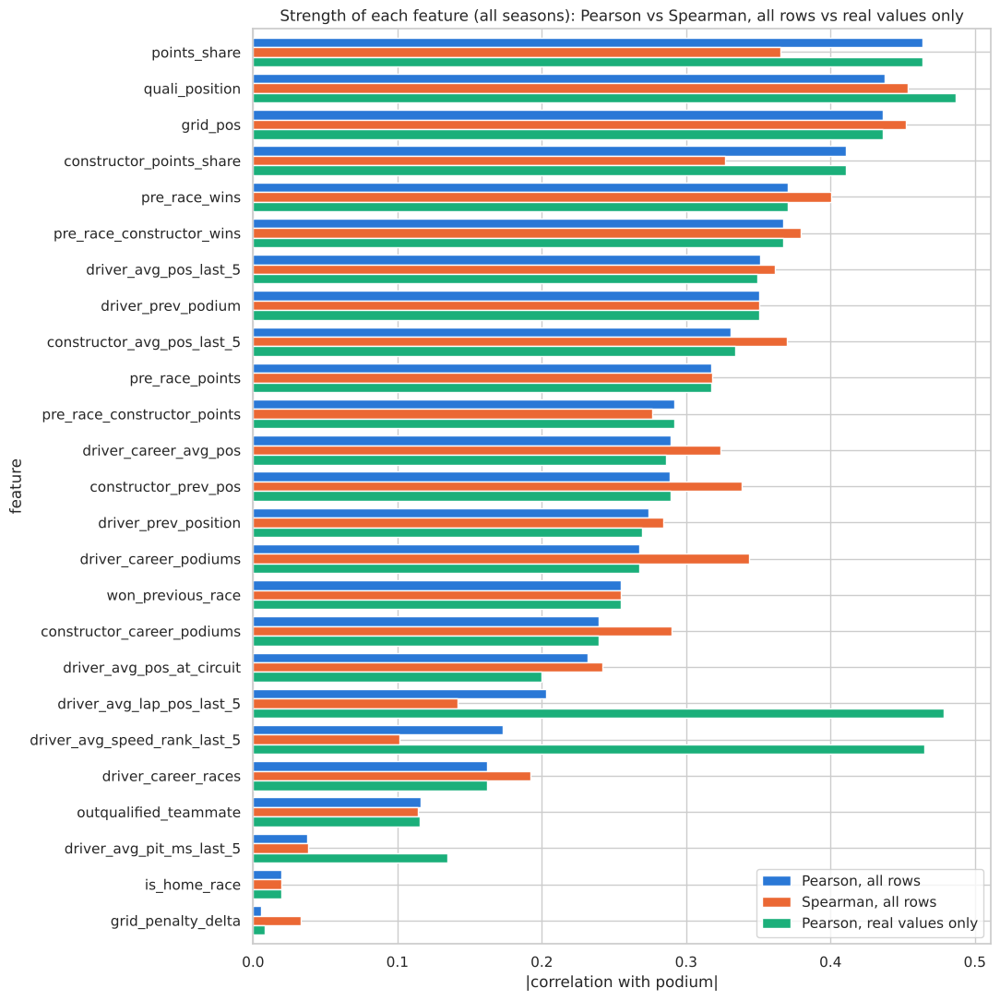

,share real,"Pearson, all rows","Spearman, all rows","Pearson, real values only"
feature,,,,
points_share,1.000,0.464,0.365,0.464
quali_position,0.394,-0.437,-0.453,-0.487
grid_pos,1.000,-0.437,-0.453,-0.437
constructor_points_share,1.000,0.410,0.327,0.410
pre_race_wins,1.000,0.370,0.400,0.370
pre_race_constructor_wins,1.000,0.367,0.379,0.367
driver_avg_pos_last_5,0.968,-0.351,-0.362,-0.349
driver_prev_podium,1.000,0.350,0.350,0.350
constructor_avg_pos_last_5,0.987,-0.331,-0.370,-0.334


In [45]:
features = [c for c in selected_columns if c != 'podium']

# which fill flag (from 6.6) tells whether a feature's value is real
FILL_SOURCE = {f: f for f in ['quali_position', 'driver_prev_position', 'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5',
                              'driver_avg_pit_ms_last_5', 'driver_avg_speed_rank_last_5', 'driver_career_avg_pos',
                              'driver_avg_pos_at_circuit', 'constructor_prev_pos', 'constructor_avg_pos_last_5']}
FILL_SOURCE.update({'grid_penalty_delta': 'quali_position', 'outqualified_teammate': 'quali_position'})

def is_real(col):
    # True where the feature holds a real value (not a fill value); features without fills are always real
    return ~filled[FILL_SOURCE[col]] if col in FILL_SOURCE else pd.Series(True, index=final_df.index)

rows = []
for col in features:
    real = is_real(col)
    rows.append({'feature': col, 'share real': real.mean(),
                 'Pearson, all rows': final_df[col].corr(final_df['podium']),
                 'Spearman, all rows': final_df[col].corr(final_df['podium'], method='spearman'),
                 'Pearson, real values only': final_df.loc[real, col].corr(final_df.loc[real, 'podium'])})
r_table = pd.DataFrame(rows).set_index('feature')
r_table = r_table.reindex(r_table['Pearson, all rows'].abs().sort_values(ascending=False).index)

ax = r_table[['Pearson, all rows', 'Spearman, all rows', 'Pearson, real values only']].abs().plot(
    kind='barh', figsize=(11, 11), color=[BLUE, ORANGE, GREEN], width=0.8)
ax.invert_yaxis(); ax.set_xlabel('|correlation with podium|')
ax.set_title('Strength of each feature (all seasons): Pearson vs Spearman, all rows vs real values only')
plt.tight_layout(); plt.show()
r_table.round(3)

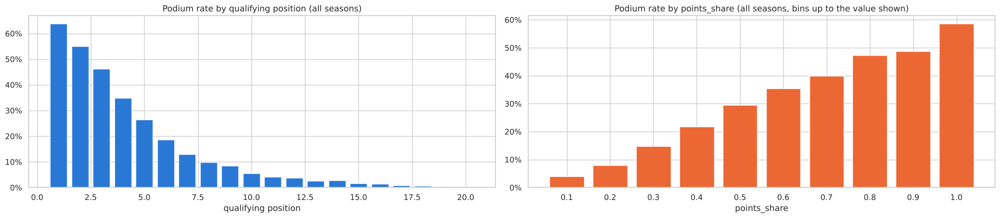

In [46]:
# Podium rate across qualifying positions: the shape Pearson cannot follow
rate_by_q = final_df.groupby(final_df['quali_position'].clip(upper=20))['podium'].mean()
rate_by_share = final_df.groupby(pd.cut(final_df['points_share'], np.linspace(0, 1, 11), include_lowest=True),
                               observed=True)['podium'].mean()
fig, axes = plt.subplots(1, 2, figsize=(20, 4.5))
axes[0].bar(rate_by_q.index, rate_by_q.values, color=BLUE)
axes[0].set_title('Podium rate by qualifying position (all seasons)'); axes[0].set_xlabel('qualifying position')
axes[1].bar(range(len(rate_by_share)), rate_by_share.values, color=ORANGE)
axes[1].set_xticks(range(len(rate_by_share))); axes[1].set_xticklabels([f'{iv.right:.1f}' for iv in rate_by_share.index])
axes[1].set_title('Podium rate by points_share (all seasons, bins up to the value shown)'); axes[1].set_xlabel('points_share')
for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()

**Observations (all seasons)**
- **Fill values hide real signal:** on the rows where the value is real, `driver_avg_lap_pos_last_5` goes from −0.20 to
  **−0.48** (42 % of rows are real) and `driver_avg_speed_rank_last_5` from −0.17 to **−0.47** (32 % real) — as strong as
  qualifying. The pit time also strengthens (−0.04 → −0.13) but stays the weakest of the form features.
- Features without placeholders (`points_share`, standings, grid) are unchanged, as expected.
- **Spearman vs Pearson:** for qualifying, team form and win counts Spearman ≥ Pearson (e.g. `constructor_avg_pos_last_5`
  −0.37 vs −0.33): the effect is monotonic but curved. For `points_share` Pearson > Spearman (0.46 vs 0.37): many rows
  tie at 0 (early rounds, non-scorers), and the steady climb at the top is what Pearson rewards.
- **Shapes:** qualifying position: 64 % → 55 % → 46 % → 35 % → 26 % for P1–P5, ~10 % at P8 and almost nothing after
  P15. `points_share`: below 0.1 a podium is rare (~4 %); in the 0.9–1.0 group it is 59 %.

### (b) Why `points_share` beats raw points
Raw points depend on the points system and on how far into the season we are. If that is the reason, the raw-points
correlation should change between scoring systems and between early and late rounds, while `points_share` should stay
stable.

In [47]:
eras = final_df.assign(points_system=pd.cut(final_df['race_year'], [1949, 1990, 2002, 2009, 2024],
                                            labels=['1950-90', '1991-2002', '2003-09 (10-8-6)', '2010-24 (25-18-15)']),
                       season_part=np.where(final_df['race_round'] <= 6, 'rounds 1-6', 'round 7+'))
rows = []
for (system, part), d in eras.groupby(['points_system', 'season_part'], observed=True):
    rows.append({'points system': system, 'part of season': part,
                 'leader points (median)': d.groupby('raceId')['pre_race_points'].max().median(),
                 'r pre_race_points': d['pre_race_points'].corr(d['podium']),
                 'r points_share': d['points_share'].corr(d['podium'])})
pd.DataFrame(rows).round(3)

,points system,part of season,leader points (median),r pre_race_points,r points_share
0,1950-90,round 7+,43.0,0.421,0.444
1,1950-90,rounds 1-6,14.5,0.317,0.321
2,1991-2002,round 7+,67.0,0.534,0.551
3,1991-2002,rounds 1-6,20.0,0.409,0.437
4,2003-09 (10-8-6),round 7+,78.0,0.499,0.515
5,2003-09 (10-8-6),rounds 1-6,19.5,0.418,0.440
6,2010-24 (25-18-15),round 7+,232.0,0.562,0.599
7,2010-24 (25-18-15),rounds 1-6,50.0,0.444,0.488


**Observations**
- The leader's points differ hugely between groups: a median of **14.5** points (1950–90, early rounds) vs **232**
  (2010–24, late season), so raw points mean different things in different rows.
- **Within every group, `points_share` correlates at least as well as raw points** (e.g. 2010–24 late season: 0.60
  vs 0.56). The big gain comes from **pooling**: all seasons together, raw points reach only +0.32 vs +0.46 for the
  share, because the share puts every group on the same scale.
- Early in a season both are weaker (fewer races behind each number): standings become informative as the season goes on.

### (c) `outqualified_teammate`: weak alone, informative together with the car
Beating your teammate only matters if the car can reach the podium at all. If that is true, the feature should be
nearly useless for slow teams and clearly useful for fast teams.

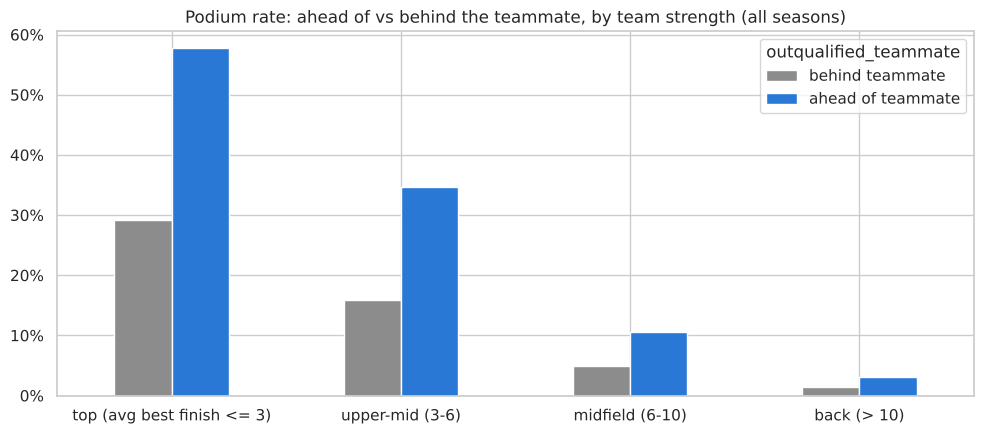

r(outqualified_teammate, quali_position): -0.296 | r(outqualified_teammate, podium): 0.116


outqualified_teammate,behind teammate,ahead of teammate,rows,r with podium in this group
team_strength,,,,
top (avg best finish <= 3),0.291,0.577,3488,0.285
upper-mid (3-6),0.160,0.347,4928,0.217
midfield (6-10),0.049,0.105,6919,0.107
back (> 10),0.014,0.031,9220,0.058


In [48]:
car = final_df.assign(team_strength=pd.cut(final_df['constructor_avg_pos_last_5'], [0, 3, 6, 10, 40],
                                         labels=['top (avg best finish <= 3)', 'upper-mid (3-6)', 'midfield (6-10)', 'back (> 10)']))
compared = car[car['outqualified_teammate'] != 0.5]
outq_table = compared.pivot_table(index='team_strength', columns='outqualified_teammate', values='podium',
                                  aggfunc='mean', observed=True).rename(columns={0.0: 'behind teammate', 1.0: 'ahead of teammate'})
outq_table['rows'] = compared.groupby('team_strength', observed=True).size()
outq_table['r with podium in this group'] = compared.groupby('team_strength', observed=True).apply(
    lambda d: d['outqualified_teammate'].corr(d['podium']))

ax = outq_table[['behind teammate', 'ahead of teammate']].plot(kind='bar', figsize=(10, 4.5), color=[GREY, BLUE], rot=0)
ax.set_title('Podium rate: ahead of vs behind the teammate, by team strength (all seasons)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.set_xlabel('')
plt.tight_layout(); plt.show()
print('r(outqualified_teammate, quali_position):', round(final_df['outqualified_teammate'].corr(final_df['quali_position']), 3),
      '| r(outqualified_teammate, podium):', round(final_df['outqualified_teammate'].corr(final_df['podium']), 3))
outq_table.round(3)

**Observations (all seasons)**
- **The value of beating the teammate depends on the car:** top teams 29 % → **58 %** podium rate, upper-midfield
  16 % → 35 %, midfield 5 % → 11 %, back-markers 1.4 % → 3.1 %.
- Inside the top-team group the correlation is **+0.29**, more than twice the overall +0.12; in back-marker teams
  it is +0.06.
- Its correlation with qualifying position is −0.30: part of what it says is already in the grid slot (indirect
  effect). The extra part is "who is the faster of two identical cars" — information the grid alone does not hold.
- **Decision:** keep it. Its value shows up in combination with team strength, which tree models and neural networks
  can learn; the ablation after training will measure it.

### (d) Redundant pairs and era-driven correlations
Pairs with |r| ≥ 0.75 carry largely the same information. Pairs whose correlation changes strongly when only rows
with real values for **both** features are used are driven by fill values, not by racing.

In [49]:
corr_all = final_df[features].corr()
pairs = (corr_all.where(np.triu(np.ones(corr_all.shape, dtype=bool), k=1)).stack().rename('r all rows').to_frame())
pairs['r real values only'] = [final_df.loc[is_real(a) & is_real(b), a].corr(final_df.loc[is_real(a) & is_real(b), b])
                               for a, b in pairs.index]
pairs['change'] = pairs['r real values only'] - pairs['r all rows']

display(pairs[pairs['r all rows'].abs() >= 0.75].sort_values('r all rows', key=abs, ascending=False).round(2))
pairs.reindex(pairs['change'].abs().sort_values(ascending=False).index).head(8).round(2)

,,r all rows,r real values only,change
quali_position,grid_pos,0.99,0.97,-0.02
pre_race_points,pre_race_constructor_points,0.96,0.96,0.00
driver_avg_pos_last_5,driver_career_avg_pos,0.82,0.81,-0.01
constructor_prev_pos,constructor_avg_pos_last_5,0.81,0.80,-0.01
driver_career_avg_pos,driver_avg_pos_at_circuit,0.80,0.69,-0.11
points_share,constructor_points_share,0.80,0.80,-0.00
pre_race_wins,pre_race_constructor_wins,0.78,0.78,0.00
driver_avg_lap_pos_last_5,driver_avg_speed_rank_last_5,0.78,0.90,0.12
driver_career_podiums,driver_career_races,0.77,0.77,-0.00


,,r all rows,r real values only,change
driver_avg_speed_rank_last_5,constructor_avg_pos_last_5,0.29,0.86,0.57
driver_avg_lap_pos_last_5,constructor_avg_pos_last_5,0.34,0.88,0.54
driver_avg_speed_rank_last_5,constructor_prev_pos,0.23,0.73,0.50
driver_avg_pos_last_5,driver_avg_speed_rank_last_5,0.40,0.87,0.47
driver_avg_lap_pos_last_5,constructor_prev_pos,0.28,0.73,0.45
driver_avg_speed_rank_last_5,constructor_points_share,-0.29,-0.74,-0.45
driver_avg_pit_ms_last_5,driver_avg_speed_rank_last_5,0.67,0.23,-0.44
driver_avg_lap_pos_last_5,constructor_points_share,-0.32,-0.75,-0.43


**Observations**
- **Redundant pairs (|r| ≥ 0.75)** stay redundant on real values: grid/qualifying (0.99 → 0.97), driver/constructor
  points (0.96), recent/career finish (0.82 → 0.81), constructor previous/average (0.81 → 0.80), points shares (0.80).
- **The largest changes are all pairs with a placeholder feature:** speed rank vs team form jumps from 0.29 to
  **0.86**, lap position vs team form from 0.34 to **0.88**, while pit time vs speed rank falls from 0.67 to 0.23.
  The real relationship between pace and car only appears on real values; the placeholders create false links
  between features that share the same missing seasons.
- **Consequence for modelling:** the fill values are a property of the old seasons, not of the drivers. Which seasons
  to train on is therefore tested in the modelling part (training-window experiment), not decided here.

## 7.5 Podium rate across the range of each feature (all seasons)
Each feature is cut into 10 equal-size groups (deciles); yes/no features get one bar per value. A useful feature has
bars far above and below the red line (the overall podium rate).

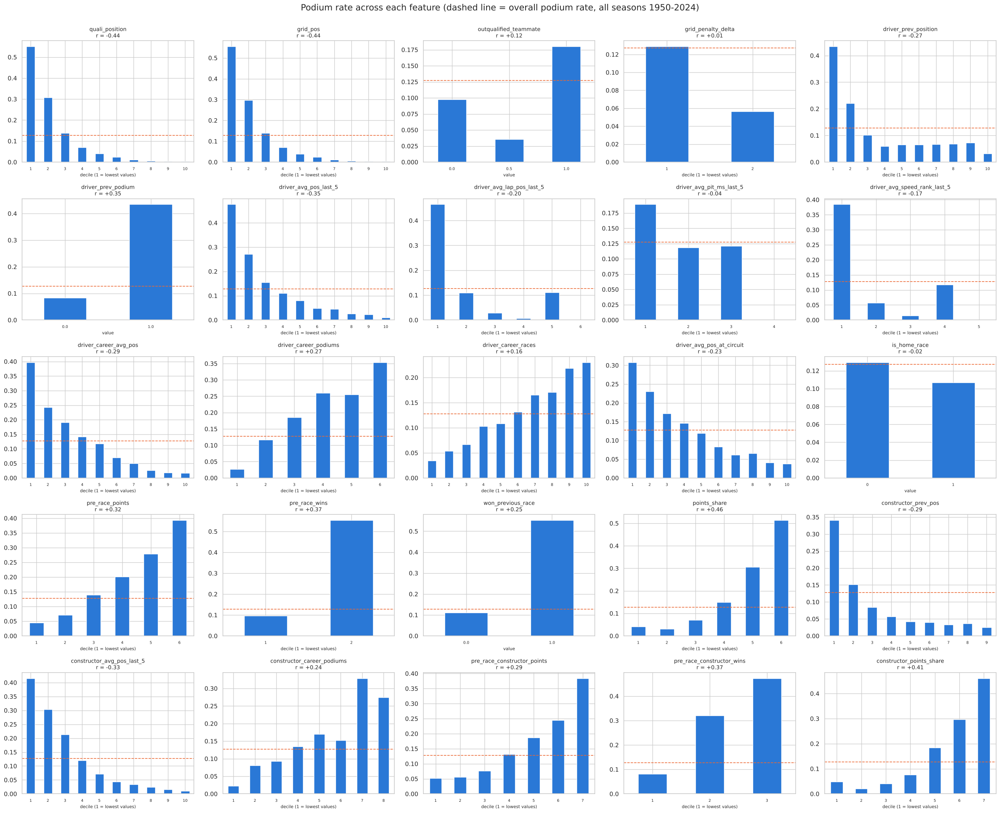

In [50]:
base_rate = final_df['podium'].mean()
fig, axes = plt.subplots(5, 5, figsize=(26, 21))
for ax, col in zip(axes.ravel(), features):
    d = final_df[[col, 'podium']]
    if d[col].nunique() <= 10:
        rate = d.groupby(col)['podium'].mean(); xlabel = 'value'
    else:
        groups = pd.qcut(d[col], 10, duplicates='drop')
        rate = d.groupby(groups, observed=True)['podium'].mean()
        rate.index = range(1, len(rate) + 1); xlabel = 'decile (1 = lowest values)'
    rate.plot(kind='bar', ax=ax, color=BLUE)
    ax.axhline(base_rate, color=ORANGE, linestyle='--', linewidth=1.2)
    ax.set_title(f'{col}\nr = {final_df[col].corr(final_df["podium"]):+.2f}', fontsize=10)
    ax.set_xlabel(xlabel, fontsize=8); ax.set_ylabel(''); ax.tick_params(axis='x', labelsize=7, rotation=0)
for ax in axes.ravel()[len(features):]:
    ax.axis('off')
plt.suptitle('Podium rate across each feature (dashed line = overall podium rate, all seasons 1950-2024)', fontsize=16, y=1.0)
plt.tight_layout(); plt.show()

**Observations (all seasons)**
- **Strong and monotonic:** qualifying/grid, recent finishing form, team form, points shares and wins — the best
  decile reaches 40–55 % podiums, the worst ~0–2 %.
- **Yes/no features split clearly:** podium in the previous race → ~43 % (vs ~8 %); won the previous race → ~55 %
  (vs ~11 %); ahead of the teammate → 18 % vs 10 %, and **no teammate to compare (0.5) → 3.5 %**: single-car entries
  were mostly privateers.
- **The fill-value block is visible:** for lap position and speed rank one decile is entirely the value 20; its podium
  rate (~11–12 %) sits right at the overall rate (12.7 %), i.e. the placeholder carries no information, while the real
  values fall from 46 % / 38 % (best decile) to almost 0.
- **Other shapes:** `driver_career_races` rises steadily (3 % → 23 %); `constructor_career_podiums` is not monotonic at
  the top (big historic teams can be slow today); `grid_penalty_delta` is highest at 0 (13 %) and ~6 % otherwise.
- **Weak:** `is_home_race` (12.9 % away vs 10.7 % home in raw rates — the home group starts further back, Q2);
  `driver_avg_pit_ms_last_5` shows a higher rate only for the fastest stops and is the fill value for 78 % of rows.

## 7.6 Bonus data-engineering questions: testing the logic behind our features
Each engineered feature rests on an assumption about racing. Correlations (7.3) cannot prove an assumption, because
most features also move with the starting slot. So every question below **holds the starting position (or the
driver's general level) fixed** and checks whether the feature still separates podium from no podium.
All seasons are used; each question needs joins across several tables.

### B1. Does recent form add information beyond the starting slot?
**Assumption behind `driver_avg_pos_last_5`:** a driver who finished well in his last races is more likely to podium
*even when he starts from the same slot* as a driver in worse form.
**Joins:** `results` → `races` (time order) → rolling form per driver (6.2) → this race's grid (`results`).

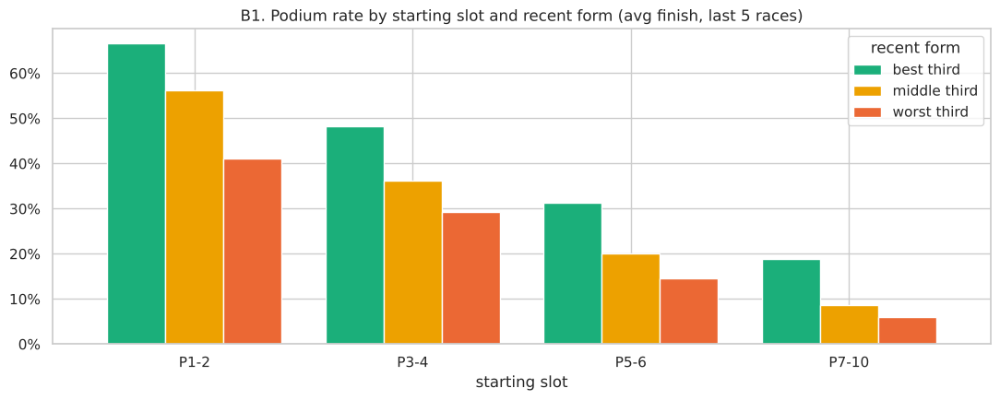

form thirds (avg finish, last 5): ['1.0-7.4', '7.4-11.4', '11.4-33.0']


recent form,best third,middle third,worst third
start,,,
P1-2,0.666 (n=1328),0.562 (n=580),0.41 (n=324)
P3-4,0.483 (n=1023),0.363 (n=739),0.293 (n=484)
P5-6,0.313 (n=715),0.2 (n=785),0.146 (n=727)
P7-10,0.189 (n=792),0.087 (n=1613),0.06 (n=2041)


In [51]:
b1 = final_df[(final_df['grid_pos'] <= 10) & ~filled['driver_avg_pos_last_5']].copy()   # debuts excluded (form unknown)
b1['start'] = pd.cut(b1['grid_pos'], [0, 2, 4, 6, 10], labels=['P1-2', 'P3-4', 'P5-6', 'P7-10'])
b1['recent form'] = pd.qcut(b1['driver_avg_pos_last_5'], 3, labels=['best third', 'middle third', 'worst third'])
b1_rate = b1.pivot_table(index='start', columns='recent form', values='podium', aggfunc='mean', observed=True)
b1_n = b1.pivot_table(index='start', columns='recent form', values='podium', aggfunc='size', observed=True)

ax = b1_rate.plot(kind='bar', figsize=(11, 4.5), color=[GREEN, YELLOW, ORANGE], rot=0, width=0.8)
ax.set_title('B1. Podium rate by starting slot and recent form (avg finish, last 5 races)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.set_xlabel('starting slot')
plt.tight_layout(); plt.show()
print('form thirds (avg finish, last 5):', [f'{iv.left:.1f}-{iv.right:.1f}' for iv in pd.qcut(b1['driver_avg_pos_last_5'], 3).cat.categories])
b1_rate.round(3).astype(str) + '  (n=' + b1_n.astype(str) + ')'

**Answer B1: yes — form adds information beyond the starting slot.**
- From the **same front row (P1–2)**, drivers in the best form third podium **67 %** of the time, drivers in the worst
  third only **41 %**.
- The pattern holds in every band: P3–4 48 % vs 29 %, P5–6 31 % vs 15 %, P7–10 19 % vs 6 %.
- **Logic confirmed:** the grid does not contain everything; recent results describe the car and driver beyond one
  qualifying session. This supports keeping the recent-form group.

### B2. Does the driver who out-qualifies his teammate also beat him in the race?
**Assumption behind `outqualified_teammate`:** two drivers of one team have (nearly) the same car, so the qualifying
duel shows who is faster that weekend, and that should carry over to the race.
**Joins:** `results` (finishing order, constructor) → `qualifying` (via the feature) → `status` (category, 3.5).
Only teams with exactly two drivers where **both were classified finishers** are used, so a breakdown cannot decide
the duel.

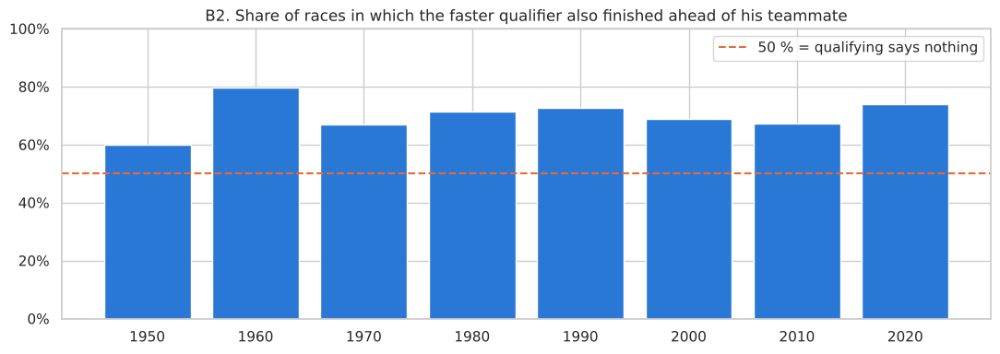

all seasons: 69.9% of 4424 team duels


decade,1950,1960,1970,1980,1990,2000,2010,2020
mean,0.6,0.797,0.668,0.713,0.727,0.688,0.671,0.738
size,20.0,74.000,280.000,421.000,531.000,889.000,1415.000,794.000


In [52]:
duel = final_df.merge(results[['raceId', 'driverId', 'positionOrder', 'statusId']], on=['raceId', 'driverId']) \
               .merge(status[['statusId', 'category']], on='statusId')
duel['team_size'] = duel.groupby(['raceId', 'constructorId'])['driverId'].transform('size')
duel['team_finishers'] = (duel['category'] == 'Finished').groupby([duel['raceId'], duel['constructorId']]).transform('sum')
duel = duel[(duel['team_size'] == 2) & (duel['team_finishers'] == 2) & (duel['outqualified_teammate'] == 1)].copy()

teammate_pos = final_df.merge(results[['raceId', 'driverId', 'positionOrder']], on=['raceId', 'driverId'])
duel = duel.merge(teammate_pos[['raceId', 'constructorId', 'driverId', 'positionOrder']]
                  .rename(columns={'driverId': 'mate', 'positionOrder': 'mate_pos'}), on=['raceId', 'constructorId'])
duel = duel[duel['mate'] != duel['driverId']]
duel['beat teammate in race'] = duel['positionOrder'] < duel['mate_pos']
duel['decade'] = duel['race_year'] // 10 * 10

b2 = duel.groupby('decade')['beat teammate in race'].agg(['mean', 'size'])
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(b2.index.astype(str), b2['mean'], color=BLUE)
ax.axhline(0.5, color=ORANGE, linestyle='--', label='50 % = qualifying says nothing')
ax.set_title('B2. Share of races in which the faster qualifier also finished ahead of his teammate')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.set_ylim(0, 1); ax.legend()
plt.tight_layout(); plt.show()
print(f"all seasons: {duel['beat teammate in race'].mean():.1%} of {len(duel)} team duels")
b2.round(3).T

**Answer B2: yes — the faster qualifier beats his teammate in 70 % of the race duels** (4,424 duels where both
finished), clearly above the 50 % that would mean "qualifying says nothing". The share is 67–80 % in every decade
with enough duels.
**Logic confirmed:** the qualifying duel shows who is faster in equal machinery and carries over to the race, which
is the idea behind `outqualified_teammate` (7.4c showed it matters most in fast cars).

### B3. Grid penalties: does the starting slot or the qualifying position decide the podium?
**Assumption behind keeping both `grid_pos` and `quali_position` (+ `grid_penalty_delta`):** a driver who qualified
well but starts further back (penalty) has a faster car than his new neighbours on the grid, so qualifying holds
information that the grid slot alone does not.
**Joins:** `results` (grid) → `qualifying` (position) → `races`. Only rows with **real** qualifying data and a real
grid slot.

qualified P1-P3: podium rate {'started where qualified': {'mean': 0.641, 'size': 1420}, 'started further back': {'mean': 0.317, 'size': 60}}


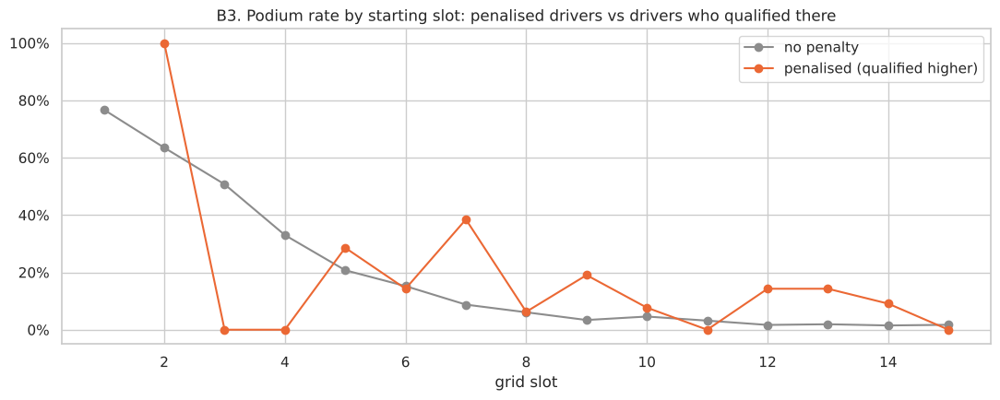

penalised starts: 528 | average places lost: 4.6 | same-slot podium-rate difference (penalised - not): +3.7% (95% interval +1.6% to +5.5%)


In [53]:
b3 = final_df[~filled['quali_position'] & (before_fill['grid'] > 0)].copy()
b3['penalised'] = b3['grid_penalty_delta'] > 0
top_q = b3[b3['quali_position'] <= 3]
print('qualified P1-P3: podium rate', top_q.groupby('penalised')['podium'].agg(['mean', 'size']).round(3)
      .rename(index={False: 'started where qualified', True: 'started further back'}).to_dict('index'))

# compare penalised drivers with drivers who START from the same slot without a penalty
b3['slot'] = b3['grid_pos'].clip(upper=20)

def penalty_gap(df):
    # podium-rate difference penalised - not penalised on the SAME grid slot, weighted by penalised starts
    rates = df.pivot_table(index='slot', columns='penalised', values='podium', aggfunc='mean').dropna()
    weights = df[df['penalised']].groupby('slot').size().reindex(rates.index)
    return np.average(rates[True] - rates[False], weights=weights)

gap = penalty_gap(b3)
rng = np.random.default_rng(42)
b3_races = {race: g for race, g in b3.groupby('raceId')}
b3_ids = np.array(list(b3_races))
b3_boot = [penalty_gap(pd.concat([b3_races[r] for r in rng.choice(b3_ids, len(b3_ids))])) for _ in range(500)]
same_slot = b3.pivot_table(index='slot', columns='penalised', values='podium', aggfunc='mean')
same_slot.columns = ['no penalty', 'penalised (qualified higher)']

ax = same_slot.loc[1:15].plot(marker='o', figsize=(11, 4.5), color=[GREY, ORANGE])
ax.set_title('B3. Podium rate by starting slot: penalised drivers vs drivers who qualified there')
ax.set_xlabel('grid slot'); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()
print(f'penalised starts: {int(b3["penalised"].sum())} | average places lost: {b3.loc[b3["penalised"], "grid_penalty_delta"].mean():.1f}'
      f' | same-slot podium-rate difference (penalised - not): {gap:+.1%}'
      f' (95% interval {np.percentile(b3_boot, 2.5):+.1%} to {np.percentile(b3_boot, 97.5):+.1%})')

**Answer B3: both matter.**
- **The grid slot matters:** drivers who qualified P1–P3 and started where they qualified podium **64 %** of the time;
  the 60 who were moved back by a penalty only **32 %**. → `grid_pos` is needed.
- **Qualifying adds information too:** a penalised driver (on average 4.6 places back) podiums **+3.7 percentage
  points** more often than a non-penalised driver starting from the same slot (95 % interval **+1.6 to +5.5**). His
  car is faster than his new neighbours'. → `quali_position` / `grid_penalty_delta` are kept as well.
- Per-slot rates for penalised drivers are noisy (528 penalised starts in total), so the weighted difference with
  its interval is the result to rely on, not single points of the line plot.

### B4. Track history: is a driver's record at *this* circuit more than his general level?
**Assumption behind `driver_avg_pos_at_circuit`:** some drivers suit some tracks. If true, a driver who historically
finishes better at this circuit than his career average should podium more often than a driver of the **same
career level** without that record.
**Joins:** `results` → `races` (`circuitId`, time order) → per driver-circuit history (6.2). Only rows with a real
circuit history (at least one earlier visit) and at least 10 career races.

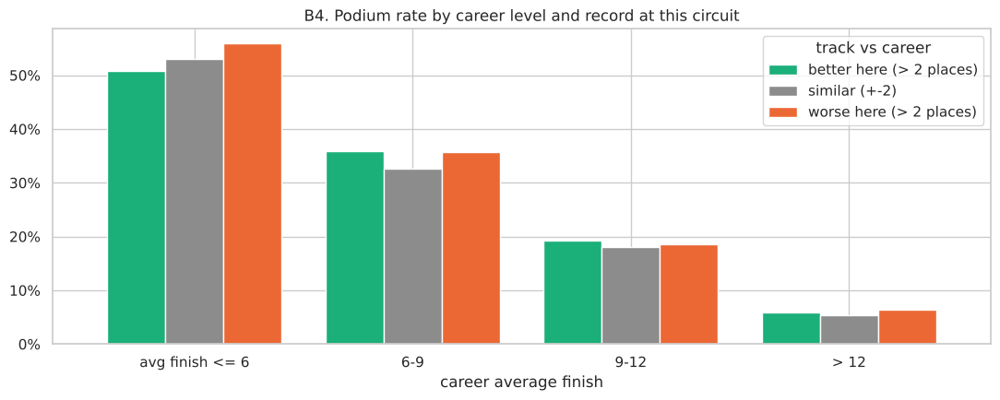

track vs career,better here (> 2 places),similar (+-2),worse here (> 2 places)
career level,,,
avg finish <= 6,0.509 (n=116),0.529 (n=255),0.559 (n=68)
6-9,0.359 (n=785),0.327 (n=1392),0.357 (n=689)
9-12,0.192 (n=1795),0.181 (n=2793),0.186 (n=1547)
> 12,0.058 (n=2566),0.053 (n=3049),0.064 (n=2676)


In [54]:
b4 = final_df[~filled['driver_avg_pos_at_circuit'] & (final_df['driver_career_races'] >= 10)].copy()
b4['track vs career'] = pd.cut(b4['driver_avg_pos_at_circuit'] - b4['driver_career_avg_pos'], [-50, -2, 2, 50],
                               labels=['better here (> 2 places)', 'similar (+-2)', 'worse here (> 2 places)'])
b4['career level'] = pd.cut(b4['driver_career_avg_pos'], [0, 6, 9, 12, 50],
                            labels=['avg finish <= 6', '6-9', '9-12', '> 12'])
b4_rate = b4.pivot_table(index='career level', columns='track vs career', values='podium', aggfunc='mean', observed=True)
b4_n = b4.pivot_table(index='career level', columns='track vs career', values='podium', aggfunc='size', observed=True)

ax = b4_rate.plot(kind='bar', figsize=(11, 4.5), color=[GREEN, GREY, ORANGE], rot=0, width=0.8)
ax.set_title('B4. Podium rate by career level and record at this circuit')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.set_xlabel('career average finish')
plt.tight_layout(); plt.show()
b4_rate.round(3).astype(str) + '  (n=' + b4_n.astype(str) + ')'

**Answer B4: no clear evidence.** Within the same career level, drivers with a better record at this circuit podium
about as often as drivers with a worse record (e.g. career average 6–9: 36 % vs 36 %; 9–12: 19 % vs 19 %). In the best
group (≤ 6) the "worse here" group is even slightly higher, but with only 68 rows.
**Logic not confirmed:** in this data a driver's track history mostly repeats his general level (r = 0.80 with the
career average, 7.3). We keep the feature for now because the brief asks to let the ablation measure each group after
training, but we expect it to add little. This is reported as a negative result, not hidden.

### B5. Is the average running position a better form signal than the finishing position?
**Assumption behind `driver_avg_lap_pos_last_5`:** a retirement gives a fast driver a bad finishing position that
says nothing about his pace; the lap-by-lap running position (from `lap_times`) is not hit as hard. If true, for
drivers whose **previous race ended in a retirement**, the running position should predict the next podium much
better than the finishing position.
**Joins:** `results` → `status` (category) → previous race of the same driver (time order from `races`) →
`lap_times` (averaged per race, 6.1). Only seasons with lap data (real values).

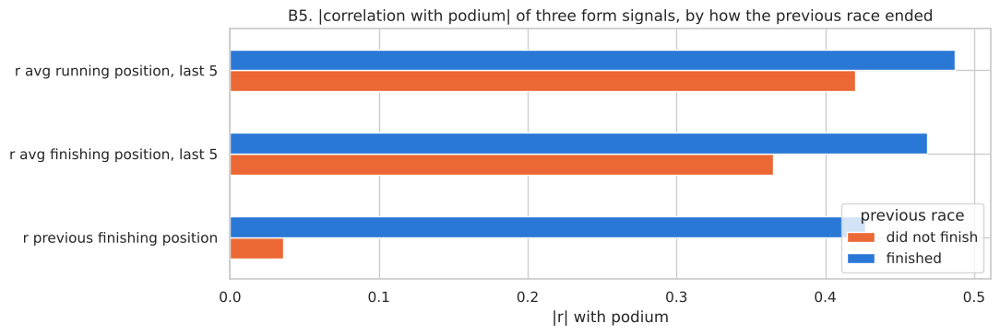

,rows,r previous finishing position,"r avg finishing position, last 5","r avg running position, last 5"
previous race,,,,
did not finish,2938,-0.036,-0.365,-0.420
finished,8406,-0.427,-0.469,-0.487


In [55]:
hist_status = (results[['raceId', 'driverId', 'statusId']].merge(status[['statusId', 'category']], on='statusId')
               .merge(race_info, on='raceId').sort_values(['driverId', 'race_year', 'race_round']))
hist_status['prev_category'] = hist_status.groupby('driverId')['category'].shift(1)
b5 = final_df.merge(hist_status[['raceId', 'driverId', 'prev_category']], on=['raceId', 'driverId'])
b5 = b5[~filled['driver_avg_lap_pos_last_5'].values & ~filled['driver_prev_position'].values]

rows = []
for prev, d in b5.groupby(b5['prev_category'] == 'Finished'):
    rows.append({'previous race': 'finished' if prev else 'did not finish', 'rows': len(d),
                 'r previous finishing position': d['driver_prev_position'].corr(d['podium']),
                 'r avg finishing position, last 5': d['driver_avg_pos_last_5'].corr(d['podium']),
                 'r avg running position, last 5': d['driver_avg_lap_pos_last_5'].corr(d['podium'])})
b5_table = pd.DataFrame(rows).set_index('previous race')
b5_table.drop(columns='rows').abs().T.plot(kind='barh', figsize=(11, 3.8), color=[ORANGE, BLUE])
plt.title('B5. |correlation with podium| of three form signals, by how the previous race ended')
plt.xlabel('|r| with podium'); plt.tight_layout(); plt.show()
b5_table.round(3)

**Answer B5: yes — after a retirement, the finishing position is useless and the running position is not.**
- When the previous race **ended early**, the previous finishing position has almost no link with the next podium
  (r = **−0.04**), while the 5-race average running position keeps **r = −0.42**.
- When the previous race was finished, all three signals are similar (−0.43 to −0.49).
- **Logic confirmed:** lap-by-lap position measures pace that a breakdown does not erase. That is why
  `driver_avg_lap_pos_last_5` is built from `lap_times` and not only from results, and why 5-race averages are
  preferred over the single previous race.

## 7.7 Feature selection (evidence from Sections 5–7)
| Group | Features kept | Evidence |
|---|---|---|
| Grid & qualifying | `quali_position`, `grid_pos`, `grid_penalty_delta`, `outqualified_teammate` | strongest single signal (4.2, 7.4a); grid ≠ qualifying for 20–37 % of modern starters (4.2); both matter after penalties (B3); the qualifying duel carries into the race (B2) and matters most in fast cars (7.4c) |
| Driver recent form | `driver_prev_position`, `driver_prev_podium`, `driver_avg_pos_last_5`, `driver_avg_lap_pos_last_5`, `driver_avg_speed_rank_last_5`, `won_previous_race` | \|r\| 0.17–0.35 on all rows, −0.48 / −0.47 for lap position / speed rank on their real values (7.4a); best deciles 40–55 % podiums (7.5); form adds information on the same grid slot (B1); running position survives a retirement (B5) |
| Driver career & track | `driver_career_avg_pos`, `driver_career_podiums`, `driver_career_races`, `driver_avg_pos_at_circuit` | long-term level; medians 18 vs 1 career podiums (7.2); **track history adds little beyond career level (B4)** — kept for the ablation to decide |
| Championship | `points_share`, `pre_race_wins`, `constructor_points_share`, `pre_race_constructor_wins` | highest Pearson r (+0.46 / +0.41); scale-free across seasons (7.4b) |
| Team form | `constructor_prev_pos`, `constructor_avg_pos_last_5`, `constructor_career_podiums` | car strength; team average best finish 3.6 vs 9.6 (7.2) |

**Dropped**
- `driver_avg_pit_ms_last_5`: a placeholder for every season before 2011 (78 % of rows, 7.1), the weakest form
  feature even on real values (r = −0.13), and its correlations with
  other features are fill-value artefacts (7.4d).
- `is_home_race`: no effect after controlling for the grid (Q2), r ≈ 0.
- `pre_race_points`, `pre_race_constructor_points`: replaced by the shares (same information, comparable scale,
  higher r; 0.96 with each other).
- `grid`: replaced by `grid_pos` (grid 0 is not a slot).

Highly correlated pairs are kept on purpose where they differ in meaningful cases; the feature-group ablation after
training measures each group's real contribution.

In [56]:
# Final feature list for modelling (21): the evidence for each choice is in 7.1-7.5
MODEL_FEATURES = ['quali_position', 'grid_pos', 'outqualified_teammate', 'grid_penalty_delta',
                  'driver_prev_position', 'driver_prev_podium', 'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5',
                  'driver_avg_speed_rank_last_5', 'won_previous_race',
                  'driver_career_avg_pos', 'driver_career_podiums', 'driver_career_races', 'driver_avg_pos_at_circuit',
                  'pre_race_wins', 'points_share',
                  'constructor_prev_pos', 'constructor_avg_pos_last_5', 'constructor_career_podiums',
                  'pre_race_constructor_wins', 'constructor_points_share']
DROPPED = {'driver_avg_pit_ms_last_5': 'fill value for every season before 2011, r ~ 0', 'is_home_race': 'no effect (Q2), r ~ 0',
           'pre_race_points': 'replaced by points_share', 'pre_race_constructor_points': 'replaced by constructor_points_share',
           'grid': 'replaced by grid_pos'}
assert len(MODEL_FEATURES) == 21 and set(MODEL_FEATURES) | set(DROPPED) == set(features) | {'grid'}
print(len(MODEL_FEATURES), 'model features |', len(DROPPED), 'dropped:', list(DROPPED))

21 model features | 5 dropped: ['driver_avg_pit_ms_last_5', 'is_home_race', 'pre_race_points', 'pre_race_constructor_points', 'grid']


## 7.8 Feature dictionary: why each feature is valid at the pre-race cutoff
| Feature | Built from (joins) | How | Known before the start because |
|---|---|---|---|
| `quali_position` | qualifying (→ results grid if missing) | this race's qualifying position | qualifying ends before the race |
| `grid_pos` | results.grid | grid 0 → behind the last car | the grid is set before the start |
| `grid_penalty_delta` | results + qualifying | `grid_pos − quali_position` | both are pre-race |
| `outqualified_teammate` | qualifying + results (team) | 1 / 0 / 0.5 within the team | qualifying order |
| `driver_prev_position`, `driver_prev_podium` | results + races | previous race, `shift(1)` per driver | earlier race |
| `driver_avg_pos_last_5` | results + races | mean of the 5 earlier finishes | earlier races |
| `driver_avg_lap_pos_last_5` | lap_times + races | mean running position, 5 earlier races | earlier races |
| `driver_avg_speed_rank_last_5` | results.rank + races | mean fastest-lap rank, 5 earlier races | earlier races |
| `won_previous_race` | driver_standings + races | season wins went up at the previous round | standings before this race |
| `driver_career_avg_pos`, `driver_career_podiums`, `driver_career_races` | results + races | expanding mean / count of earlier races | earlier races |
| `driver_avg_pos_at_circuit` | results + races (circuitId) | mean finish in earlier visits to this circuit | earlier races |
| `pre_race_wins`, `points_share` | driver_standings + races | standings after the previous round; points ÷ leader's points | previous round's standings |
| `constructor_prev_pos`, `constructor_avg_pos_last_5`, `constructor_career_podiums` | results + races (team) | team's best finish / podiums in earlier races | earlier races |
| `pre_race_constructor_wins`, `constructor_points_share` | constructor_standings + races | as for drivers | previous round's standings |

Every "earlier race" feature uses `shift(1)` inside the driver (team) and the time order season → round; the
leakage check in 6.10 confirmed this on 200 random rows.

## 7.9 Known limitations (for the report)
- **Qualifying-coverage drift:** no qualifying data before 1994 and only 6–59 % of races in 1996–2002 (2.5). There,
  `quali_position` is the grid slot, so `grid_penalty_delta` is always 0 and `outqualified_teammate` compares grid
  slots.
- **Placeholder values by era:** lap position (< 1996), fastest-lap rank (< 2004) and pit time (< 2011) are fill
  values; they weaken correlations on the full table (7.4a) and create false links between features (7.4d).
- **Era sensitivity:** reliability (4.2), field sizes (podium rate 8–18 %, 4.2), points systems (7.4b) and front-row
  conversion (Q1) all changed over time, so relationships learned on old seasons may not hold today.
- **Shared drives (1950s):** a few races have more than three drivers credited with a podium (4.2).
- **Not in the data:** weather, tyre strategy, safety cars, upgrades — the main reasons a podium can come from far back.
- **Correlation is not causation:** every relationship above shows association only.

### Next steps (modelling part, need trained models)
- Train / validation / test split by season and its justification, and the training-window experiment that decides
  which seasons the model learns from (7.4d).
- At least two **preprocessing-order experiments** (e.g. shift-then-roll vs a leaky order; building features on all
  seasons before vs after filtering).
- Models, baseline, metrics, feature-group ablation (which will also test B4), XAI and the inference function.

# Part 2 — Modelling

| # | Section | Milestone item |
|---|---|---|
| 8 | Modelling setup | features, split, metrics (primary / secondary), model definitions |
| 9 | Pre-training EDA on the split | class balance, distribution shift, fill values per split |
| 10 | Training-window experiment | year ablation: which seasons to learn from |
| 11 | Baselines, tuning, training curves | ≥ 2 statistical models + shallow NN, hyperparameters on validation only |
| 12 | Model comparison | all five metrics on train / validation / test, ROC/PR, confusion matrices, calibration, per season |
| 13 | Preprocessing-order experiments | 3 experiments |
| 14 | Feature-group ablation | drop-one, keep-one, extra groups, confidence intervals |
| 15 | Explainability | permutation importance, SHAP global vs correlation, many local SHAP + LIME cases, error-driven ablation |
| 16 | Bonus: race-aware tier | race-relative features, ensemble, race normalisation |
| 17 | Final model and summary of all experiments | winner chosen on validation, visualised |
| 18 | Inference function | complete and partially-missing records |
| 19 | Deliverables checklist | |

# 8. Modelling setup
**Primary metric: PR-AUC.** Podiums are only ~13–15 % of rows; PR-AUC measures how well podium finishers are ranked
above the rest *within the rare class*. **Secondary: ROC-AUC** (overall ranking) and **F1** (quality of the yes/no
decision at the chosen threshold), with precision and recall reported to show *how* F1 is reached. Accuracy is shown
only to illustrate why it is misleading (always "no podium" ≈ 85–87 %).

**Rules used everywhere:**
- Split **by season**: train ≤ 2019 (start year decided in Section 10), validation **2020–2021**, test **2022–2024**.
  Whole races stay together; the model always predicts seasons that come after the ones it learned from.
- Hyperparameters, the probability threshold (best F1) and every choice are made on **train/validation only**; the
  test set is scored, never used to choose.
- The neural network's early stopping watches the validation loss (also a train/validation-only decision).

In [57]:
import time
warnings.filterwarnings('ignore', category=UserWarning)       # sklearn feature-name notes, tqdm
warnings.filterwarnings('ignore', category=RuntimeWarning)    # correlation of a constant column in old eras
try:                                    # Keras runs on PyTorch if available (local/Kaggle), otherwise TensorFlow
    import torch  # noqa: F401
    os.environ.setdefault('KERAS_BACKEND', 'torch')
except ImportError:
    os.environ.setdefault('KERAS_BACKEND', 'tensorflow')
import keras
from keras import layers
from keras.callbacks import EarlyStopping
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             accuracy_score, precision_recall_curve, roc_curve, confusion_matrix, log_loss)
print('Keras backend:', keras.backend.backend())

data = pd.read_csv(os.path.join(OUT_DIR, 'all_features.csv'))        # the modelling table from Section 6
assert len(data) == len(filled)                                        # same row order as in Part 1
MODELS = ['Logistic regression', 'Random forest', 'Gradient boosting', 'Neural network']
MODEL_COLORS = dict(zip(MODELS, [BLUE, ORANGE, GREEN, YELLOW]))
FEATURE_GROUPS = {
    'Grid & qualifying': ['quali_position', 'grid_pos', 'grid_penalty_delta', 'outqualified_teammate'],
    'Driver recent form': ['driver_prev_position', 'driver_prev_podium', 'driver_avg_pos_last_5',
                           'driver_avg_lap_pos_last_5', 'driver_avg_speed_rank_last_5', 'won_previous_race'],
    'Driver career & circuit': ['driver_career_avg_pos', 'driver_career_podiums', 'driver_career_races',
                                'driver_avg_pos_at_circuit'],
    'Championship standing': ['points_share', 'pre_race_wins', 'constructor_points_share', 'pre_race_constructor_wins'],
    'Team form': ['constructor_prev_pos', 'constructor_avg_pos_last_5', 'constructor_career_podiums']}
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(MODEL_FEATURES)   # the 21 features from 7.7
print(len(data), 'rows |', len(MODEL_FEATURES), 'features in', len(FEATURE_GROUPS), 'groups')

I0000 00:00:1792268393.850272   28034 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792268393.886102   28034 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792268395.955367   28034 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras backend: tensorflow
26668 rows | 21 features in 5 groups


In [58]:
# ---------- split, metrics, threshold ----------
VAL_YEARS, TEST_YEARS = (2020, 2021), (2022, 2024)

def split_by_season(df, start):
    sets = {'train': df[df['race_year'].between(start, 2019)],
            'val': df[df['race_year'].between(*VAL_YEARS)],
            'test': df[df['race_year'].between(*TEST_YEARS)]}
    return sets

def best_threshold(y, p):
    # probability cut-off with the best F1 -- chosen on VALIDATION only
    precision, recall, thr = precision_recall_curve(y, p)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return thr[np.argmax(f1[:-1])]

def metrics(y, p, thr):
    pred = (np.asarray(p) >= thr).astype(int)
    return {'PR-AUC': average_precision_score(y, p), 'ROC-AUC': roc_auc_score(y, p), 'F1': f1_score(y, pred),
            'precision': precision_score(y, pred, zero_division=0), 'recall': recall_score(y, pred),
            'accuracy': accuracy_score(y, pred)}

def evaluate(name, probs, sets, thr=None):
    # one row: threshold from validation, all metrics on train / val / test
    thr = best_threshold(sets['val']['podium'], probs['val']) if thr is None else thr
    row = {'model': name, 'threshold': thr}
    for s in ['train', 'val', 'test']:
        row.update({f'{s} {k}': v for k, v in metrics(sets[s]['podium'], probs[s], thr).items()})
    return row

def race_bootstrap(df, p_a, p_b=None, n=300, seed=0):
    # 95 % interval of PR-AUC (or of the difference a - b) when whole races are resampled
    races, y = df['raceId'].values, df['podium'].values
    by_race = {r: np.where(races == r)[0] for r in np.unique(races)}
    ids, rng, out = np.array(list(by_race)), np.random.default_rng(seed), []
    for _ in range(n):
        idx = np.concatenate([by_race[r] for r in rng.choice(ids, len(ids))])
        a = average_precision_score(y[idx], p_a[idx])
        out.append(a - average_precision_score(y[idx], p_b[idx]) if p_b is not None else a)
    return np.percentile(out, [2.5, 97.5])

In [59]:
# ---------- the four models ----------
class ShallowNet:
    # Shallow Keras network (1-2 hidden layers) with an sklearn-like interface.
    # The scaler is fit on the training rows only; early stopping watches the validation loss.
    def __init__(self, hidden=(32, 16), dropout=0.2, balanced=True, seed=42):
        self.hidden, self.dropout, self.balanced, self.seed = hidden, dropout, balanced, seed

    def fit(self, X, y, X_val, y_val):
        self.scaler = StandardScaler().fit(X)
        keras.utils.set_random_seed(self.seed)
        net = [layers.Input(shape=(X.shape[1],))]
        for units in self.hidden:
            net += [layers.Dense(units, activation='relu'), layers.Dropout(self.dropout)]
        self.model = keras.Sequential(net + [layers.Dense(1, activation='sigmoid')])
        self.model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
                           metrics=[keras.metrics.AUC(curve='PR', name='pr_auc')])
        weights = None
        if self.balanced:                              # podium rows count more (~15 % of rows)
            w = compute_class_weight('balanced', classes=np.array([0, 1]), y=y)
            weights = {0: w[0], 1: w[1]}
        self.history = self.model.fit(self.scaler.transform(X), np.asarray(y),
                                      validation_data=(self.scaler.transform(X_val), np.asarray(y_val)),
                                      epochs=200, batch_size=128, class_weight=weights, verbose=0,
                                      callbacks=[EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)])
        return self

    def predict_proba(self, X):
        p = self.model.predict(self.scaler.transform(X), verbose=0).ravel()
        return np.column_stack([1 - p, p])

DEFAULT_PARAMS = {'Logistic regression': {'C': 1.0},
                  'Random forest': {'min_samples_leaf': 20, 'max_features': 'sqrt'},
                  'Gradient boosting': {'max_leaf_nodes': 15, 'max_iter': 200, 'min_samples_leaf': 100},
                  'Neural network': {'hidden': (32, 16), 'dropout': 0.2, 'balanced': True}}

def make_model(name, p):
    if name == 'Logistic regression':
        return make_pipeline(StandardScaler(), LogisticRegression(C=p['C'], max_iter=3000))
    if name == 'Random forest':
        return RandomForestClassifier(n_estimators=300, min_samples_leaf=p['min_samples_leaf'],
                                      max_features=p['max_features'], random_state=42, n_jobs=-1)
    if name == 'Gradient boosting':
        return HistGradientBoostingClassifier(learning_rate=0.03, max_leaf_nodes=p['max_leaf_nodes'],
                                              max_iter=p['max_iter'], min_samples_leaf=p['min_samples_leaf'],
                                              l2_regularization=1.0, random_state=42)
    return ShallowNet(**p)

def train_and_predict(name, features, sets, params=None):
    # fit one model on the training seasons; return it and its probabilities on train / val / test
    p = {**DEFAULT_PARAMS[name], **(params or {})}
    model = make_model(name, p)
    X, y = sets['train'][features], sets['train']['podium']
    if name == 'Neural network':
        model.fit(X, y, sets['val'][features], sets['val']['podium'])
    else:
        model.fit(X, y)
    return model, {s: model.predict_proba(d[features])[:, 1] for s, d in sets.items()}

# 9. Pre-training EDA on the split
Before training we check that the three periods are comparable: same target balance, similar feature
distributions, and how much of each period consists of fill values. The training period is shown in full
(1950–2019); Section 10 decides how much of it is used.

In [60]:
eda_sets = split_by_season(data, 1950)
split_table = pd.DataFrame({name: {'seasons': f"{d['race_year'].min()}-{d['race_year'].max()}",
                                   'races': d['raceId'].nunique(), 'rows': len(d),
                                   'podium rate': round(d['podium'].mean(), 3),
                                   'drivers per race': round(len(d) / d['raceId'].nunique(), 1)}
                            for name, d in eda_sets.items()}).T
display(split_table)

fill_by_split = pd.DataFrame({name: filled.loc[d.index, ['quali_position', 'driver_avg_lap_pos_last_5',
                                                        'driver_avg_speed_rank_last_5', 'driver_avg_pos_at_circuit']].mean()
                              for name, d in eda_sets.items()}).T.round(3)
fill_by_split.columns = ['quali filled from grid', 'lap position = fill', 'speed rank = fill', 'first visit to circuit']
fill_by_split

,seasons,races,rows,podium rate,drivers per race
train,1950-2019,1018,24529,0.125,24.1
val,2020-2021,39,780,0.15,20.0
test,2022-2024,68,1359,0.15,20.0


,quali filled from grid,lap position = fill,speed rank = fill,first visit to circuit
train,0.659,0.624,0.739,0.318
val,0.001,0.009,0.009,0.282
test,0.000,0.006,0.006,0.123


**Observations**
- **Target balance:** 12.5 % podiums in the full training period, 15.0 % in validation and test. The difference is
  only field size (24 drivers per race on average before 2020, 20 now; 3 / 20 = 15 %), not a change in the target.
- **Fill values:** two thirds of all training rows (1950–2019) have qualifying filled from the grid, 62 % a lap-position
  placeholder and 74 % a speed-rank placeholder, while validation and test have almost none (< 1 %). A model trained
  on all seasons learns partly from placeholders it will never see at prediction time — the training-window
  experiment (Section 10) tests whether that hurts.

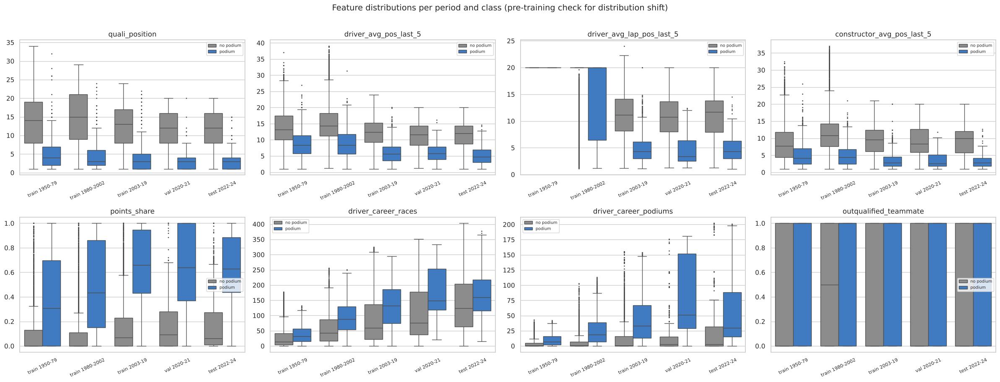

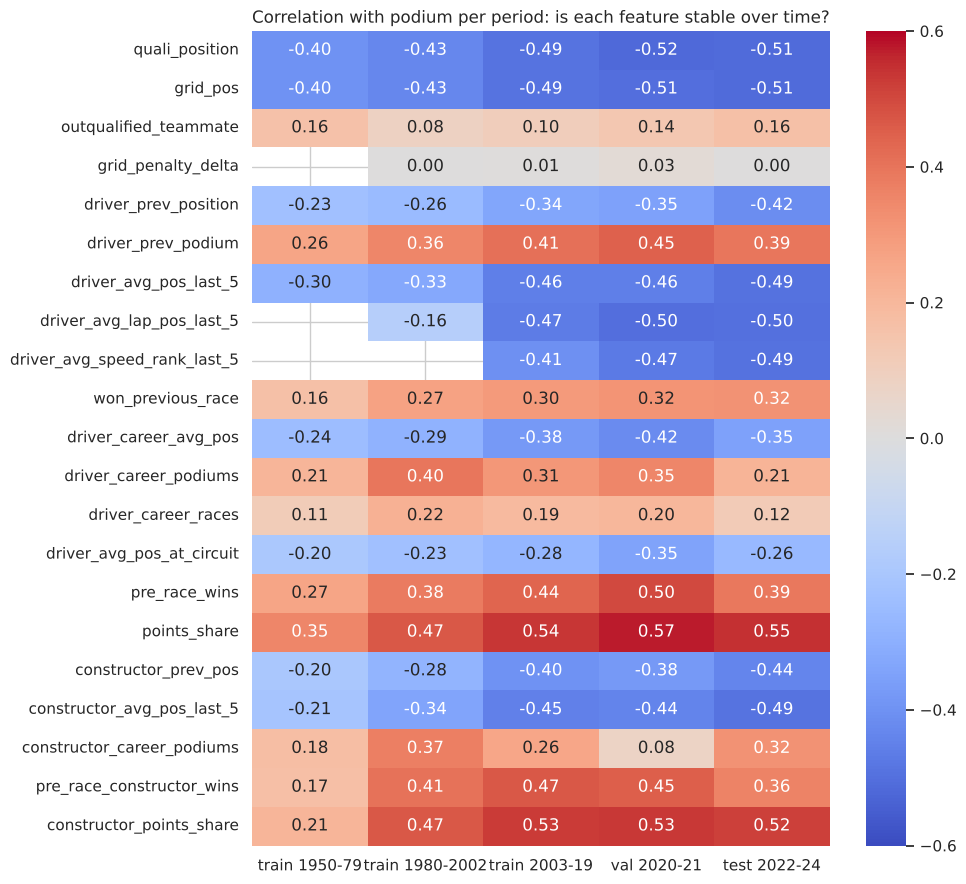

In [61]:
# Distribution shift: the same features in train (by era), validation and test
period = pd.cut(data['race_year'], [1949, 1979, 2002, 2019, 2021, 2024],
                labels=['train 1950-79', 'train 1980-2002', 'train 2003-19', 'val 2020-21', 'test 2022-24'])
SHIFT_FEATURES = ['quali_position', 'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5', 'constructor_avg_pos_last_5',
                  'points_share', 'driver_career_races', 'driver_career_podiums', 'outqualified_teammate']
fig, axes = plt.subplots(2, 4, figsize=(24, 9))
for ax, col in zip(axes.ravel(), SHIFT_FEATURES):
    sns.boxplot(x=period, y=data[col], hue=data['podium'].map({0: 'no podium', 1: 'podium'}), ax=ax,
                palette=[GREY, BLUE], flierprops={'markersize': 1})
    ax.set_title(col); ax.set_xlabel(''); ax.set_ylabel(''); ax.tick_params(axis='x', rotation=25, labelsize=8)
    ax.legend(fontsize=7)
plt.suptitle('Feature distributions per period and class (pre-training check for distribution shift)', y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

corr_by_period = pd.DataFrame({p: data[period == p][MODEL_FEATURES].corrwith(data.loc[period == p, 'podium'])
                               for p in period.cat.categories})
fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(corr_by_period, cmap='coolwarm', center=0, vmin=-0.6, vmax=0.6, annot=True, fmt='.2f', ax=ax)
ax.set_title('Correlation with podium per period: is each feature stable over time?')
plt.tight_layout(); plt.show()

**Observations**
- **Stable direction, changing strength:** every feature keeps the same sign in every period, but most become
  **stronger over time**: `quali_position` −0.40 (1950–79) → −0.51 (test); `points_share` 0.35 → 0.55;
  `constructor_points_share` 0.21 → 0.52. Modern F1 is more predictable (reliability, team dominance, 4.2).
- **The 2003–19 training block looks like validation and test** (e.g. `driver_avg_pos_last_5` −0.46 / −0.46 / −0.49),
  while 1950–79 is clearly different. Lap position and speed rank only exist from 1996 / 2004 (blank cells).
- Some features drift: `constructor_career_podiums` drops to 0.08 in 2020–21 (historic teams such as Williams were
  slow), and `driver_career_podiums` is weaker in the test seasons (0.21), when young drivers (Norris, Piastri,
  Leclerc, Russell) reached podiums without a long podium history.

# 10. Training-window experiment (year ablation)
Which seasons should the model learn from? Each candidate start year marks a change in the data or the rules (2.5,
4.2). Training always ends in 2019 and every window is scored on the **same validation and test seasons**.
All four models use their default settings here (tuning follows on the chosen window, so the comparison is not
circular).

**Decision rule (stated before running):** choose the window with the **highest mean validation PR-AUC over the
four models**. The race-bootstrap interval shows how precise each value is.

In [62]:
WINDOWS = {'1950+ (all)': 1950, '1980+': 1980, '1994+ (qualifying)': 1994, '1996+ (lap times)': 1996,
           '2003+ (full qualifying)': 2003, '2004+ (fastest-lap rank)': 2004, '2011+ (pit stops)': 2011,
           '2014+ (hybrid era)': 2014, '2017+ (last 3 seasons)': 2017}
window_rows, t0 = [], time.time()
for wname, start in WINDOWS.items():
    sets = split_by_season(data, start)
    for name in MODELS:
        _, probs = train_and_predict(name, MODEL_FEATURES, sets)
        row = evaluate(name, probs, sets)
        lo, hi = race_bootstrap(sets['val'], probs['val'], n=200)
        window_rows.append({'window': wname, 'start': start, 'train rows': len(sets['train']), **row,
                            'val PR-AUC low': lo, 'val PR-AUC high': hi})
window_results = pd.DataFrame(window_rows)
print(f'{len(window_rows)} models trained in {time.time() - t0:.0f} s')

window_summary = window_results.pivot_table(index='window', columns='model', values='val PR-AUC', sort=False)
window_summary['mean of 4 models'] = window_summary.mean(axis=1)
window_summary['test mean (not used)'] = window_results.pivot_table(index='window', columns='model', values='test PR-AUC',
                                                                    sort=False).mean(axis=1)
window_summary.round(3)

36 models trained in 272 s


model,Logistic regression,Random forest,Gradient boosting,Neural network,mean of 4 models,test mean (not used)
window,,,,,,
1950+ (all),0.733,0.724,0.710,0.731,0.724,0.702
1980+,0.731,0.728,0.688,0.725,0.718,0.703
1994+ (qualifying),0.736,0.728,0.718,0.730,0.728,0.703
1996+ (lap times),0.738,0.729,0.692,0.731,0.723,0.701
2003+ (full qualifying),0.742,0.724,0.718,0.731,0.729,0.700
2004+ (fastest-lap rank),0.743,0.723,0.702,0.741,0.727,0.700
2011+ (pit stops),0.739,0.721,0.710,0.735,0.726,0.687
2014+ (hybrid era),0.727,0.725,0.692,0.742,0.722,0.687
2017+ (last 3 seasons),0.710,0.735,0.667,0.714,0.707,0.657


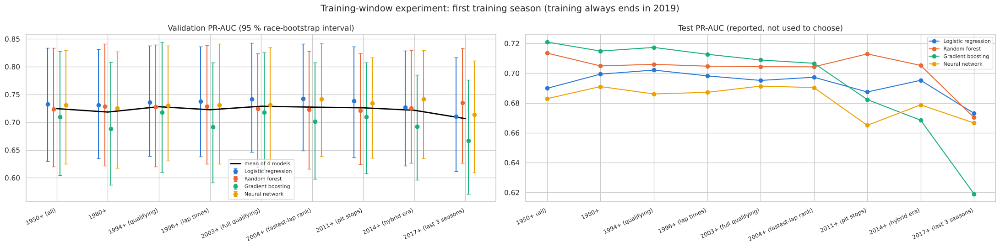

chosen window: 2003+ (full qualifying) (start 2003) | mean validation PR-AUC 0.729


,seasons,races,rows,podiums,podium rate
train,2003-2019,321,6831,963,0.141
val,2020-2021,39,780,117,0.15
test,2022-2024,68,1359,204,0.15


In [63]:
fig, axes = plt.subplots(1, 2, figsize=(22, 5.5))
x = np.arange(len(WINDOWS))
for k, name in enumerate(MODELS):
    d = window_results[window_results['model'] == name]
    axes[0].errorbar(x + (k - 1.5) * 0.12, d['val PR-AUC'], yerr=[d['val PR-AUC'] - d['val PR-AUC low'],
                     d['val PR-AUC high'] - d['val PR-AUC']], fmt='o', color=MODEL_COLORS[name], label=name, capsize=3)
    axes[1].plot(x, d['test PR-AUC'], marker='o', color=MODEL_COLORS[name], label=name)
axes[0].plot(x, window_summary['mean of 4 models'], color='black', linewidth=2, label='mean of 4 models')
for ax, title in zip(axes, ['Validation PR-AUC (95 % race-bootstrap interval)', 'Test PR-AUC (reported, not used to choose)']):
    ax.set_xticks(x); ax.set_xticklabels(list(WINDOWS), rotation=25, ha='right', fontsize=9)
    ax.set_title(title); ax.legend(fontsize=8)
plt.suptitle('Training-window experiment: first training season (training always ends in 2019)', fontsize=14)
plt.tight_layout(); plt.show()

BEST_WINDOW = window_summary['mean of 4 models'].idxmax()
START = WINDOWS[BEST_WINDOW]
print(f'chosen window: {BEST_WINDOW} (start {START}) | mean validation PR-AUC {window_summary.loc[BEST_WINDOW, "mean of 4 models"]:.3f}')
SETS = split_by_season(data, START)
pd.DataFrame({s: {'seasons': f"{d['race_year'].min()}-{d['race_year'].max()}", 'races': d['raceId'].nunique(),
                  'rows': len(d), 'podiums': int(d['podium'].sum()), 'podium rate': round(d['podium'].mean(), 3)}
              for s, d in SETS.items()}).T

**Observations**
- **The windows are very close:** the mean validation PR-AUC ranges from 0.707 (2017+) to 0.729 (2003+); for each
  model the race-bootstrap intervals of almost all windows overlap. No window is clearly better.
- **Following the pre-stated rule, 2003+ is chosen** (highest mean, 0.729; 1994+ is 0.728). It is also the first
  season with qualifying data for every race (2.5), so the choice agrees with the data coverage.
- **Too short is worse:** with only 2017–2019 (3 seasons, ~1,200 rows) gradient boosting drops to 0.667 and the
  test mean to 0.657 — too little data.
- **Very old seasons do not help:** adding 1950–2002 (1950+) gives 0.724, slightly below 2003+, consistent with the
  placeholders and the different era seen in Section 9.
- Final split: **train 2003–2019 (321 races, 6,831 rows), validation 2020–2021 (39 races, 780 rows), test 2022–2024
  (68 races, 1,359 rows)**, podium rate 14–15 % in all three.

# 11. Baselines, tuning and training
## 11.1 Baselines
A model must beat the simplest reasonable approaches, otherwise its complexity is not earned:
- **Rule baseline:** "a driver who starts in the top 3 finishes on the podium" (score = 1 / `grid_pos`, cut-off 1/3).
- **Statistical baseline:** logistic regression on `grid_pos` and `quali_position` only (the starting position).

In [64]:
rule_probs = {s: 1 / d['grid_pos'].values for s, d in SETS.items()}
baseline_rows = [evaluate('Baseline: grid <= 3 rule', rule_probs, SETS, thr=1 / 3)]
_, start_only_probs = train_and_predict('Logistic regression', ['grid_pos', 'quali_position'], SETS)
baseline_rows.append(evaluate('Baseline: logistic regression on grid + qualifying', start_only_probs, SETS))
baselines = pd.DataFrame(baseline_rows).set_index('model')
baselines[[c for c in baselines.columns if c.split()[-1] in ('PR-AUC', 'ROC-AUC', 'F1')] + ['threshold']].round(3)

,train PR-AUC,train ROC-AUC,train F1,val PR-AUC,val ROC-AUC,val F1,test PR-AUC,test ROC-AUC,test F1,threshold
model,,,,,,,,,,
Baseline: grid <= 3 rule,0.626,0.909,0.646,0.639,0.909,0.692,0.647,0.914,0.649,0.333
Baseline: logistic regression on grid + qualifying,0.631,0.912,0.642,0.662,0.920,0.696,0.652,0.919,0.672,0.337


**Observations:** starting position alone is already a strong predictor: the grid rule reaches **PR-AUC 0.64–0.65**
and **F1 0.65–0.69**, and logistic regression on grid + qualifying 0.65–0.66. Any model below these numbers would
be worthless.

## 11.2 Hyperparameter tuning (validation PR-AUC)
Small, readable grids. Every candidate is trained on the training seasons and scored on validation; the best
validation PR-AUC wins. Train PR-AUC is shown next to it to spot overfitting (large train-validation gap).

In [65]:
def tune(name, grid):
    rows = []
    for params in grid:
        _, probs = train_and_predict(name, MODEL_FEATURES, SETS, params)
        rows.append({**{k: str(v) for k, v in params.items()},
                     'train PR-AUC': average_precision_score(SETS['train']['podium'], probs['train']),
                     'val PR-AUC': average_precision_score(SETS['val']['podium'], probs['val'])})
    table = pd.DataFrame(rows)
    best = grid[int(table['val PR-AUC'].idxmax())]
    return table, best

t0 = time.time()
GRIDS = {
    'Logistic regression': [{'C': c} for c in [0.001, 0.01, 0.1, 1, 10]],
    'Random forest': [{'min_samples_leaf': leaf, 'max_features': mf} for leaf in [1, 5, 20, 50] for mf in ['sqrt', 0.5]],
    'Gradient boosting': [{'max_leaf_nodes': n, 'max_iter': it, 'min_samples_leaf': 100}
                          for n in [7, 15, 31] for it in [100, 200, 400]],
    'Neural network': [{'hidden': h, 'dropout': d, 'balanced': b}
                       for h in [(16,), (32, 16), (64, 32)] for d in [0.0, 0.3] for b in [False, True]]}
tuning, BEST_PARAMS = {}, {}
for name, grid in GRIDS.items():
    tuning[name], BEST_PARAMS[name] = tune(name, grid)
    print(f'{name:20s} best: {BEST_PARAMS[name]}')
print(f'tuning took {time.time() - t0:.0f} s')

Logistic regression  best: {'C': 0.1}


Random forest        best: {'min_samples_leaf': 50, 'max_features': 0.5}


Gradient boosting    best: {'max_leaf_nodes': 31, 'max_iter': 100, 'min_samples_leaf': 100}


Neural network       best: {'hidden': (16,), 'dropout': 0.0, 'balanced': True}
tuning took 320 s


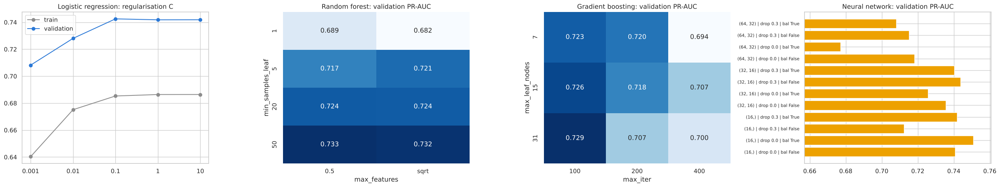

,train PR-AUC,val PR-AUC
Logistic regression,0.685,0.743
Random forest,0.746,0.733
Gradient boosting,0.793,0.729
Neural network,0.729,0.751


In [66]:
fig, axes = plt.subplots(1, 4, figsize=(26, 5))
t = tuning['Logistic regression']
axes[0].plot(t['C'], t['train PR-AUC'], marker='o', label='train', color=GREY)
axes[0].plot(t['C'], t['val PR-AUC'], marker='o', label='validation', color=BLUE)
axes[0].set_title('Logistic regression: regularisation C'); axes[0].legend()
for ax, name, idx, col in [(axes[1], 'Random forest', 'min_samples_leaf', 'max_features'),
                           (axes[2], 'Gradient boosting', 'max_leaf_nodes', 'max_iter')]:
    pivot = tuning[name].pivot_table(index=idx, columns=col, values='val PR-AUC')
    pivot.index = pd.to_numeric(pivot.index); pivot = pivot.sort_index()          # '5' < '20' numerically
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'{name}: validation PR-AUC')
t = tuning['Neural network'].assign(label=lambda d: d['hidden'] + ' | drop ' + d['dropout'] + ' | bal ' + d['balanced'])
axes[3].barh(t['label'], t['val PR-AUC'], color=YELLOW); axes[3].set_xlim(t['val PR-AUC'].min() - 0.02, t['val PR-AUC'].max() + 0.01)
axes[3].set_title('Neural network: validation PR-AUC'); axes[3].tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()
pd.concat({name: t.loc[t['val PR-AUC'].idxmax()] for name, t in tuning.items()}, axis=1).T[['train PR-AUC', 'val PR-AUC']].astype(float).round(3)

**Observations (chosen on validation PR-AUC)**
- **Logistic regression:** C = 0.1 (mild regularisation); validation is flat from 0.1 to 10 and only drops with very strong
  regularisation (0.71 at C = 0.001).
- **Random forest:** larger leaves (`min_samples_leaf` = 50) and half of the features per split win (0.733); leaf
  size 1 lets each tree memorise single rows and scores lowest on validation (0.68–0.69).
- **Gradient boosting:** 31 leaves × 100 trees. It has the **largest train–validation gap** (0.79 vs 0.73), the clearest
  sign of overfitting among the four.
- **Neural network:** the smallest network wins — **one hidden layer of 16 units**, no dropout, balanced class
  weights (validation 0.751). Bigger networks did not help on ~6,800 training rows.
- Validation scores of the winners are slightly optimistic (they were selected on validation); the test seasons give
  the unbiased check.

## 11.3 The four final models
Each model is retrained with its best settings. How they work:
- **Logistic regression** (statistical): a weighted sum of the standardised features turned into a probability by
  the sigmoid function. Limitation: only straight-line effects; it cannot learn "teammate duel matters only in a
  fast car" (7.4c) unless such a feature is built by hand.
- **Random forest** (statistical): hundreds of decision trees, each on a bootstrap sample of rows and a random subset
  of features; their probabilities are averaged. Limitation: probabilities are smoothed toward the average, and it
  cannot extrapolate beyond values seen in training.
- **Gradient boosting** (statistical): small trees built one after another, each correcting the previous errors.
  Limitation: overfits quickly without a small learning rate, leaf-size limits and L2 regularisation.
- **Shallow neural network** (1–2 hidden ReLU layers, sigmoid output, Adam, binary cross-entropy): learns
  non-linear combinations of the features. Limitations: needs scaled inputs, is sensitive to the random start, and
  is the hardest to explain (SHAP/LIME in Section 15).

In [67]:
final_models, final_probs = {}, {}
for name in MODELS:
    final_models[name], final_probs[name] = train_and_predict(name, MODEL_FEATURES, SETS, BEST_PARAMS[name])
final_results = pd.DataFrame([evaluate(name, final_probs[name], SETS) for name in MODELS] + baseline_rows).set_index('model')
THRESHOLDS = final_results['threshold'].to_dict()
show_cols = ['threshold'] + [f'{s} {m}' for m in ['PR-AUC', 'ROC-AUC', 'F1', 'precision', 'recall', 'accuracy']
                             for s in ['train', 'val', 'test']]
final_results[show_cols].round(3)

,threshold,train PR-AUC,val PR-AUC,test PR-AUC,train ROC-AUC,val ROC-AUC,test ROC-AUC,train F1,val F1,test F1,train precision,val precision,test precision,train recall,val recall,test recall,train accuracy,val accuracy,test accuracy
model,,,,,,,,,,,,,,,,,,,
Logistic regression,0.369,0.685,0.743,0.696,0.929,0.928,0.935,0.669,0.715,0.671,0.629,0.712,0.624,0.714,0.718,0.725,0.900,0.914,0.893
Random forest,0.372,0.746,0.733,0.707,0.949,0.935,0.939,0.692,0.709,0.675,0.663,0.700,0.650,0.724,0.718,0.701,0.909,0.912,0.898
Gradient boosting,0.374,0.793,0.729,0.709,0.960,0.932,0.937,0.732,0.704,0.662,0.699,0.717,0.644,0.767,0.692,0.681,0.921,0.913,0.896
Neural network,0.737,0.729,0.751,0.677,0.946,0.931,0.929,0.694,0.718,0.661,0.628,0.718,0.617,0.775,0.718,0.711,0.904,0.915,0.890
Baseline: grid <= 3 rule,0.333,0.626,0.639,0.647,0.909,0.909,0.914,0.646,0.692,0.649,0.647,0.692,0.650,0.646,0.692,0.647,0.900,0.908,0.895
Baseline: logistic regression on grid + qualifying,0.337,0.631,0.662,0.652,0.912,0.920,0.919,0.642,0.696,0.672,0.568,0.609,0.600,0.738,0.812,0.765,0.884,0.894,0.888


**Observations**
- **All four models beat both baselines** on PR-AUC (test 0.68–0.71 vs 0.65), ROC-AUC (0.93–0.94 vs 0.91–0.92) and
  F1 (0.66–0.68 vs 0.65–0.67). The gain over the grid rule is real but moderate: the starting slot carries most of the
  information; the other features add ~0.05–0.06 PR-AUC.
- **Validation ranking:** neural network 0.751 > logistic regression 0.743 > random forest 0.733 > gradient boosting
  0.729. **Test ranking:** gradient boosting 0.709 ≈ random forest 0.707 > logistic regression 0.696 > neural network
  0.677. The models are within a few hundredths of each other and the order changes between periods — none of them is
  clearly best.
- **Test scores are lower than validation** for every model (−0.02 to −0.07 PR-AUC): 2022 brought new technical rules
  and 2024 was an unusually open season (12.2).
- **Precision vs recall:** at the validation threshold the models find **68–73 % of podiums** (recall) and 62–65 % of
  their podium calls are right (precision).
- **Accuracy is ~0.89–0.90 for every model and baseline**, while "always no podium" already scores 0.85 — this is why
  it is not used to compare models.

## 11.4 Training and validation curves
- **Neural network:** loss and PR-AUC per epoch (training loss is class-weighted and has dropout active, so compare
  the *trend*, not the level). The dashed line is the epoch whose weights were kept.
- **Gradient boosting:** log-loss after every added tree.
- **Random forest:** log-loss as trees are added (more trees average more votes; they do not fit harder).
- **Logistic regression:** no iterations to plot; its learning curve below shows train/validation PR-AUC as more
  training seasons are added.

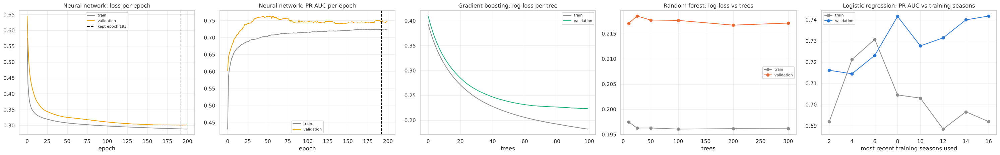

In [68]:
fig, axes = plt.subplots(1, 5, figsize=(30, 4.8))
h = final_models['Neural network'].history.history
best_epoch = int(np.argmin(h['val_loss'])) + 1
axes[0].plot(h['loss'], label='train', color=GREY); axes[0].plot(h['val_loss'], label='validation', color=YELLOW)
axes[0].axvline(best_epoch - 1, color='black', linestyle='--', label=f'kept epoch {best_epoch}')
axes[0].set(title='Neural network: loss per epoch', xlabel='epoch')
axes[1].plot(h['pr_auc'], label='train', color=GREY); axes[1].plot(h['val_pr_auc'], label='validation', color=YELLOW)
axes[1].axvline(best_epoch - 1, color='black', linestyle='--'); axes[1].set(title='Neural network: PR-AUC per epoch', xlabel='epoch')

gb = final_models['Gradient boosting']
gb_train = [log_loss(SETS['train']['podium'], p[:, 1]) for p in gb.staged_predict_proba(SETS['train'][MODEL_FEATURES])]
gb_val = [log_loss(SETS['val']['podium'], p[:, 1]) for p in gb.staged_predict_proba(SETS['val'][MODEL_FEATURES])]
axes[2].plot(gb_train, label='train', color=GREY); axes[2].plot(gb_val, label='validation', color=GREEN)
axes[2].set(title='Gradient boosting: log-loss per tree', xlabel='trees')

rf = RandomForestClassifier(n_estimators=10, warm_start=True, random_state=42, n_jobs=-1,
                            min_samples_leaf=BEST_PARAMS['Random forest']['min_samples_leaf'],
                            max_features=BEST_PARAMS['Random forest']['max_features'])
rf_curve = []
for n in [10, 25, 50, 100, 200, 300]:
    rf.set_params(n_estimators=n).fit(SETS['train'][MODEL_FEATURES], SETS['train']['podium'])
    rf_curve.append((n, log_loss(SETS['train']['podium'], rf.predict_proba(SETS['train'][MODEL_FEATURES])[:, 1]),
                     log_loss(SETS['val']['podium'], rf.predict_proba(SETS['val'][MODEL_FEATURES])[:, 1])))
rf_curve = np.array(rf_curve)
axes[3].plot(rf_curve[:, 0], rf_curve[:, 1], marker='o', label='train', color=GREY)
axes[3].plot(rf_curve[:, 0], rf_curve[:, 2], marker='o', label='validation', color=ORANGE)
axes[3].set(title='Random forest: log-loss vs trees', xlabel='trees')

seasons_lr = sorted(SETS['train']['race_year'].unique())
lr_curve = []
for k in range(2, len(seasons_lr) + 1, 2):
    part = {**SETS, 'train': SETS['train'][SETS['train']['race_year'].isin(seasons_lr[-k:])]}
    _, pr = train_and_predict('Logistic regression', MODEL_FEATURES, part, BEST_PARAMS['Logistic regression'])
    lr_curve.append((k, average_precision_score(part['train']['podium'], pr['train']),
                     average_precision_score(SETS['val']['podium'], pr['val'])))
lr_curve = np.array(lr_curve)
axes[4].plot(lr_curve[:, 0], lr_curve[:, 1], marker='o', label='train', color=GREY)
axes[4].plot(lr_curve[:, 0], lr_curve[:, 2], marker='o', label='validation', color=BLUE)
axes[4].set(title='Logistic regression: PR-AUC vs training seasons', xlabel='most recent training seasons used')
for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Observations**
- **Neural network:** both losses fall and level off together; the validation PR-AUC peaks around epoch 50 and
  stays flat. Early stopping kept epoch 193 (validation loss still slowly improving), and there is no sign of the
  validation loss turning up.
- **Gradient boosting:** training loss keeps falling with every tree while validation loss flattens after ~70 trees:
  more trees would mainly memorise (matches the train–validation gap in 11.2).
- **Random forest:** both curves are flat after ~25 trees; extra trees only stabilise the average.
- **Logistic regression:** validation PR-AUC improves as more seasons are added (0.716 with 2 seasons → 0.742 with
  16), so more data from comparable seasons helps the simplest model most.

# 12. Model comparison
## 12.1 All metrics side by side

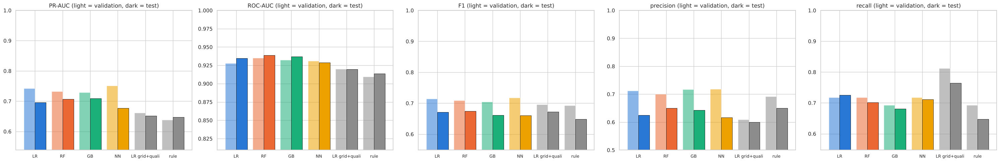

In [69]:
compare = final_results.loc[MODELS + ['Baseline: logistic regression on grid + qualifying', 'Baseline: grid <= 3 rule']]
fig, axes = plt.subplots(1, 5, figsize=(30, 5), sharey=False)
bar_colors = [MODEL_COLORS.get(m, GREY) for m in compare.index]
for ax, metric in zip(axes, ['PR-AUC', 'ROC-AUC', 'F1', 'precision', 'recall']):
    x = np.arange(len(compare))
    ax.bar(x - 0.2, compare[f'val {metric}'], 0.4, color=bar_colors, alpha=0.55, label='validation')
    ax.bar(x + 0.2, compare[f'test {metric}'], 0.4, color=bar_colors, label='test', edgecolor='black', linewidth=0.6)
    ax.set_xticks(x); ax.set_xticklabels(['LR', 'RF', 'GB', 'NN', 'LR grid+quali', 'rule'], fontsize=9)
    ax.set_ylim(max(0, compare[[f'val {metric}', f'test {metric}']].min().min() - 0.1), 1)
    ax.set_title(f'{metric} (light = validation, dark = test)')
plt.tight_layout(); plt.show()

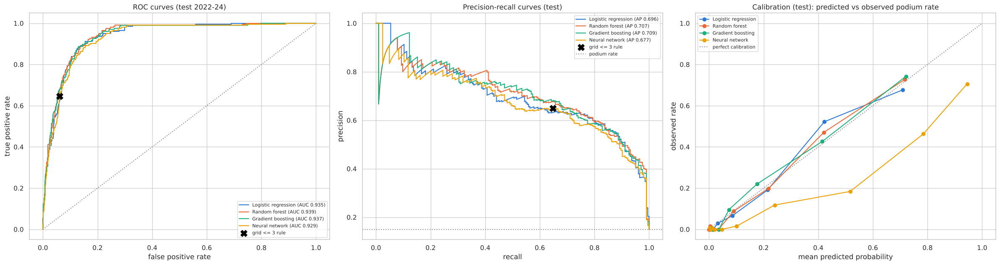

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(24, 6.5))
y_test = SETS['test']['podium']
for name in MODELS:
    p = final_probs[name]['test']
    fpr, tpr, _ = roc_curve(y_test, p); prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rec, prec, color=MODEL_COLORS[name], label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
    frac, mean_p = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    axes[2].plot(mean_p, frac, marker='o', color=MODEL_COLORS[name], label=name)
rule_pred = (rule_probs['test'] >= 1 / 3)
axes[0].scatter(((rule_pred == 1) & (y_test == 0)).sum() / (y_test == 0).sum(), ((rule_pred == 1) & (y_test == 1)).sum() / y_test.sum(),
                color='black', marker='X', s=120, label='grid <= 3 rule', zorder=5)
axes[1].scatter(((rule_pred == 1) & (y_test == 1)).sum() / y_test.sum(), ((rule_pred == 1) & (y_test == 1)).sum() / rule_pred.sum(),
                color='black', marker='X', s=120, label='grid <= 3 rule', zorder=5)
axes[0].plot([0, 1], [0, 1], color=GREY, linestyle=':'); axes[1].axhline(y_test.mean(), color=GREY, linestyle=':', label='podium rate')
axes[2].plot([0, 1], [0, 1], color=GREY, linestyle=':', label='perfect calibration')
axes[0].set(title='ROC curves (test 2022-24)', xlabel='false positive rate', ylabel='true positive rate')
axes[1].set(title='Precision-recall curves (test)', xlabel='recall', ylabel='precision')
axes[2].set(title='Calibration (test): predicted vs observed podium rate', xlabel='mean predicted probability', ylabel='observed rate')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

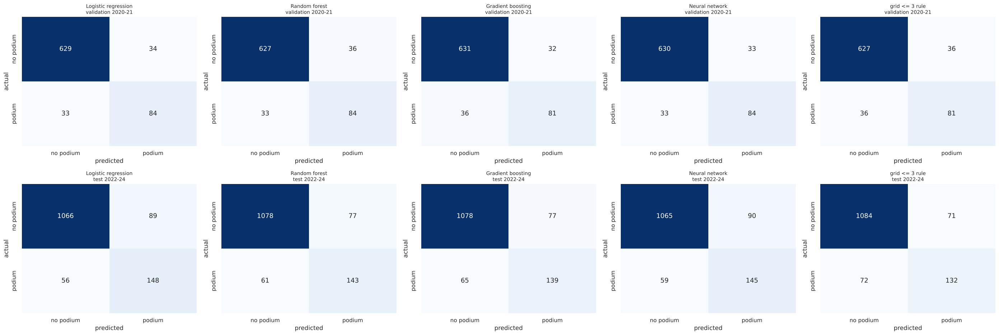

In [71]:
fig, axes = plt.subplots(2, 5, figsize=(28, 9.5))
labels = ['no podium', 'podium']
cm_models = MODELS + ['Baseline: grid <= 3 rule']
for col, name in enumerate(cm_models):
    for row, split in enumerate(['val', 'test']):
        p = rule_probs[split] if name.startswith('Baseline') else final_probs[name][split]
        cm = confusion_matrix(SETS[split]['podium'], (p >= THRESHOLDS[name]).astype(int))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[row, col],
                    xticklabels=labels, yticklabels=labels, annot_kws={'size': 13})
        axes[row, col].set_title(f"{name.replace('Baseline: ', '')}\n{'validation 2020-21' if split == 'val' else 'test 2022-24'}", fontsize=10)
        axes[row, col].set_xlabel('predicted'); axes[row, col].set_ylabel('actual')
plt.tight_layout(); plt.show()

**Observations**
- **ROC curves overlap almost completely** (AUC 0.929–0.939): all models rank drivers in a very similar way. The grid
  rule's single point lies on or just below the curves.
- **PR curves** separate slightly at high recall: tree models keep precision a bit better when they try to find more
  podiums; the grid rule sits on the curves at recall ≈ 0.65.
- **Calibration:** logistic regression, random forest and gradient boosting are close to the diagonal (a predicted
  40 % is ~40 % in reality). The **neural network over-predicts** (balanced class weights inflate probabilities);
  its ranking is unaffected, which is why its validation threshold is high (0.74).
- **Confusion matrices (test):** the models make 56–65 false negatives and 77–90 false positives out of 204 podiums.
  The grid rule misses more podiums (72, with 71 false alarms) — the models trade a few extra false alarms for more
  podiums found.

## 12.2 Performance per test season (year ablation on the test side)

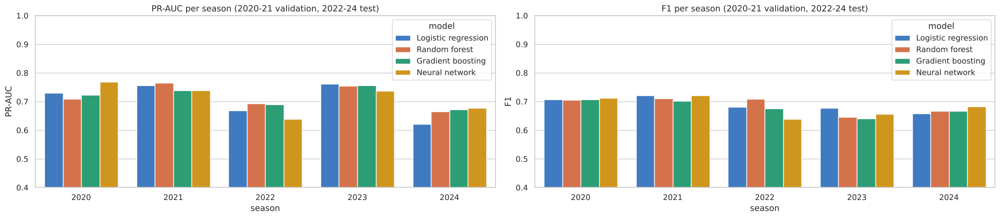

season,2020,2021,2022,2023,2024
model,,,,,
Gradient boosting,0.723,0.739,0.689,0.756,0.672
Logistic regression,0.731,0.757,0.670,0.762,0.622
Neural network,0.769,0.738,0.639,0.737,0.678
Random forest,0.709,0.766,0.693,0.755,0.665


In [72]:
season_rows = []
for name in MODELS:
    for year, d in SETS['test'].groupby('race_year'):
        p = final_probs[name]['test'][SETS['test']['race_year'].values == year]
        season_rows.append({'model': name, 'season': year, 'PR-AUC': average_precision_score(d['podium'], p),
                            'F1': f1_score(d['podium'], (p >= THRESHOLDS[name]).astype(int))})
for year, d in SETS['val'].groupby('race_year'):
    for name in MODELS:
        p = final_probs[name]['val'][SETS['val']['race_year'].values == year]
        season_rows.append({'model': name, 'season': year, 'PR-AUC': average_precision_score(d['podium'], p),
                            'F1': f1_score(d['podium'], (p >= THRESHOLDS[name]).astype(int))})
per_season = pd.DataFrame(season_rows)
fig, axes = plt.subplots(1, 2, figsize=(20, 4.5))
for ax, metric in zip(axes, ['PR-AUC', 'F1']):
    sns.barplot(data=per_season, x='season', y=metric, hue='model', palette=MODEL_COLORS, ax=ax)
    ax.set_ylim(0.4, 1); ax.set_title(f'{metric} per season (2020-21 validation, 2022-24 test)')
plt.tight_layout(); plt.show()
per_season.pivot_table(index='model', columns='season', values='PR-AUC').round(3)

**Observations**
- **2023 is the easiest season** (PR-AUC 0.74–0.76): Red Bull won 21 of 22 races, so the podium was very predictable.
- **2024 is the hardest** (0.62–0.68): four different teams won races (McLaren, Ferrari, Red Bull, Mercedes), so team
  strength changed during the season and form from earlier races was a weaker guide.
- The season-to-season spread (~0.10) is larger than the differences between models (~0.03), so the choice of
  model matters less than the nature of the season.

# 13. Preprocessing-order experiments
Each experiment changes **one** preprocessing choice, rebuilds the affected features, retrains logistic regression
and gradient boosting with their tuned settings on the chosen window, and compares validation and test PR-AUC.

## 13.1 Experiment P1: the order of shift and rolling (leakage)
Three ways to build `driver_avg_pos_last_5` and `driver_career_podiums` from the cleaned results:
- **A. correct:** inside each driver, `shift(1)` first, then the rolling window / running total (only earlier races);
- **B. leaky:** no shift — the window includes **this race's own result**;
- **C. wrong order:** the shift is done per driver, but the window is applied after the grouping ended, so it runs
  across different drivers (the bug in our first version).

variant A equals the table built in Section 6: True True


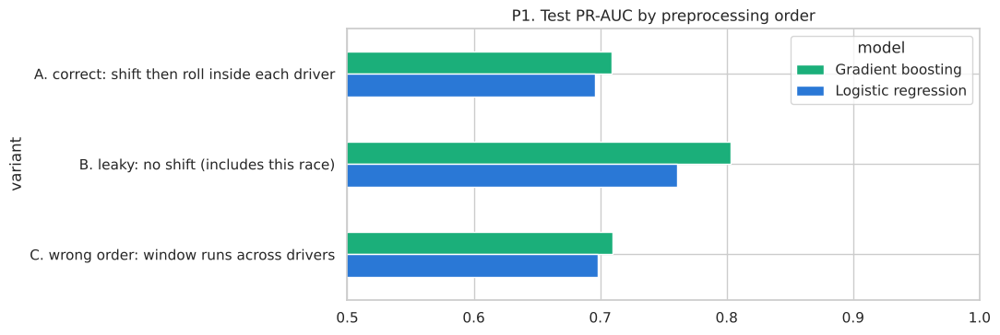

,variant,model,"r(avg finish last 5, podium)","r(career podiums, podium)",val PR-AUC,test PR-AUC,test F1
0,A. correct: shift then roll inside each driver,Logistic regression,-0.351,0.268,0.743,0.696,0.671
1,A. correct: shift then roll inside each driver,Gradient boosting,-0.351,0.268,0.729,0.709,0.662
2,B. leaky: no shift (includes this race),Logistic regression,-0.435,0.280,0.801,0.761,0.701
3,B. leaky: no shift (includes this race),Gradient boosting,-0.435,0.280,0.806,0.803,0.727
4,C. wrong order: window runs across drivers,Logistic regression,-0.351,-0.062,0.739,0.698,0.659
5,C. wrong order: window runs across drivers,Gradient boosting,-0.351,-0.062,0.707,0.710,0.664


In [73]:
hist_p1 = (results[['raceId', 'driverId', 'positionOrder', 'podium']].merge(race_info, on='raceId')
           .sort_values(['driverId', 'race_year', 'race_round']).reset_index(drop=True))
g1 = hist_p1.groupby('driverId')
P1_VARIANTS = {
    'A. correct: shift then roll inside each driver': (g1['positionOrder'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean()),
                                                       g1['podium'].transform(lambda s: s.shift(1).cumsum())),
    'B. leaky: no shift (includes this race)': (g1['positionOrder'].transform(lambda s: s.rolling(5, min_periods=1).mean()),
                                                g1['podium'].transform(lambda s: s.cumsum())),
    'C. wrong order: window runs across drivers': (g1['positionOrder'].shift(1).rolling(5, min_periods=1).mean(),
                                                   g1['podium'].shift(1).cumsum())}

def with_replaced(df, new_cols):
    # replace some feature columns of the modelling table (same rows, same order)
    return df.drop(columns=[c for c in new_cols.columns if c not in ('raceId', 'driverId')]).merge(
        new_cols, on=['raceId', 'driverId'], how='left')

p1_rows = []
for variant, (avg5, podiums) in P1_VARIANTS.items():
    new_cols = hist_p1[['raceId', 'driverId']].assign(driver_avg_pos_last_5=avg5.fillna(20).values,
                                                      driver_career_podiums=podiums.fillna(0).values)
    d = with_replaced(data, new_cols)
    sets = split_by_season(d, START)
    for name in ['Logistic regression', 'Gradient boosting']:
        _, probs = train_and_predict(name, MODEL_FEATURES, sets, BEST_PARAMS[name])
        r = evaluate(name, probs, sets)
        p1_rows.append({'variant': variant, 'model': name,
                        'r(avg finish last 5, podium)': d['driver_avg_pos_last_5'].corr(d['podium']),
                        'r(career podiums, podium)': d['driver_career_podiums'].corr(d['podium']),
                        'val PR-AUC': r['val PR-AUC'], 'test PR-AUC': r['test PR-AUC'], 'test F1': r['test F1']})
    if variant.startswith('A'):
        print('variant A equals the table built in Section 6:',
              np.allclose(d['driver_avg_pos_last_5'], data['driver_avg_pos_last_5']),
              np.allclose(d['driver_career_podiums'], data['driver_career_podiums']))
p1 = pd.DataFrame(p1_rows)
ax = p1.pivot(index='variant', columns='model', values='test PR-AUC').plot(kind='barh', figsize=(11, 3.8),
                                                                       color=[GREEN, BLUE])
ax.set_xlim(0.5, 1); ax.set_title('P1. Test PR-AUC by preprocessing order'); ax.invert_yaxis()
plt.tight_layout(); plt.show()
p1.round(3)

**Observations**
- **A (correct)** reproduces the table from Section 6 exactly.
- **B (leaky, no shift)** looks *better*: validation PR-AUC jumps to **0.80**, test to 0.76–0.80. That is not a better
  model — the feature contains the result it is supposed to predict (a podium in this race lowers the "last-5 average"
  and raises the career podium count). In real use, before the race, this information does not exist. **A sudden
  jump like this is the typical warning sign of leakage.**
- **C (wrong order)** silently breaks the feature: `driver_career_podiums` becomes a running total across *all*
  drivers, its correlation with podium flips from +0.27 to **−0.06**, and gradient boosting loses 0.02 validation
  PR-AUC. This was the bug in our first version (7.3 / Section 6).
- **Conclusion:** the order *shift → window, inside each group* is the only valid one.

## 13.2 Experiment P2: build history features on all seasons, *then* filter vs filter first
The training window starts in a later season (Section 10). If the table is filtered to the window **before** the
history features are built, every driver's career "starts" at the window: a champion in his 10th season looks like
a rookie. We rebuild the career/form features from the filtered results and compare.

rebuilding on all seasons reproduces the table: True


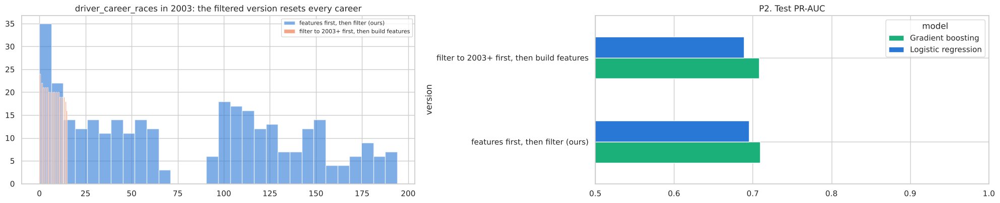

,version,model,val PR-AUC,test PR-AUC
0,"features first, then filter (ours)",Logistic regression,0.743,0.696
1,"features first, then filter (ours)",Gradient boosting,0.729,0.709
2,"filter to 2003+ first, then build features",Logistic regression,0.742,0.689
3,"filter to 2003+ first, then build features",Gradient boosting,0.718,0.708


In [74]:
def driver_history(hist):
    # driver form / career / circuit features from the given results rows (same logic as Section 6)
    hist = hist.sort_values(['driverId', 'race_year', 'race_round'])
    g = hist.groupby('driverId')
    out = hist[['raceId', 'driverId']].copy()
    out['driver_prev_position'] = g['positionOrder'].shift(1).fillna(20)
    out['driver_prev_podium'] = g['podium'].shift(1).fillna(0)
    out['driver_avg_pos_last_5'] = g['positionOrder'].transform(last5).fillna(20)
    out['driver_career_avg_pos'] = g['positionOrder'].transform(lambda s: s.shift(1).expanding().mean()).fillna(20)
    out['driver_career_podiums'] = g['podium'].transform(lambda s: s.shift(1).cumsum()).fillna(0)
    out['driver_career_races'] = g.cumcount()
    out['driver_avg_pos_at_circuit'] = (hist.groupby(['driverId', 'circuitId'])['positionOrder']
                                        .transform(lambda s: s.shift(1).expanding().mean())
                                        .fillna(out['driver_career_avg_pos']))
    return out

P2_START = START if START > 1950 else 2003          # with an all-seasons window there is nothing to filter
hist_all = results[['raceId', 'driverId', 'positionOrder', 'podium']].merge(race_info, on='raceId')
p2_versions = {'features first, then filter (ours)': data,
               f'filter to {P2_START}+ first, then build features': with_replaced(
                   data, driver_history(hist_all[hist_all['race_year'] >= P2_START]))}
print('rebuilding on all seasons reproduces the table:',
      np.allclose(with_replaced(data, driver_history(hist_all))['driver_career_podiums'], data['driver_career_podiums']))

p2_rows = []
for version, d in p2_versions.items():
    sets = split_by_season(d, P2_START)
    for name in ['Logistic regression', 'Gradient boosting']:
        _, probs = train_and_predict(name, MODEL_FEATURES, sets, BEST_PARAMS[name])
        r = evaluate(name, probs, sets)
        p2_rows.append({'version': version, 'model': name, 'val PR-AUC': r['val PR-AUC'], 'test PR-AUC': r['test PR-AUC']})
p2 = pd.DataFrame(p2_rows)

first_season = {v: d[d['race_year'] == P2_START] for v, d in p2_versions.items()}
fig, axes = plt.subplots(1, 2, figsize=(20, 4.2))
for (v, d), color in zip(first_season.items(), [BLUE, ORANGE]):
    axes[0].hist(d['driver_career_races'], bins=30, alpha=0.6, color=color, label=v)
axes[0].set_title(f'driver_career_races in {P2_START}: the filtered version resets every career'); axes[0].legend(fontsize=8)
p2.pivot(index='version', columns='model', values='test PR-AUC').plot(kind='barh', ax=axes[1], color=[GREEN, BLUE])
axes[1].set_xlim(0.5, 1); axes[1].set_title('P2. Test PR-AUC')
plt.tight_layout(); plt.show()
p2.round(3)

**Observations**
- Filtering first resets every career at 2003: in 2003 every driver has between 0 and ~16 "career races" instead of
  up to ~190 (left plot), so experienced champions look like rookies.
- The models lose a little (gradient boosting validation 0.729 → 0.718, logistic regression test 0.696 → 0.689).
  The effect is small because recent form and standings do not depend on the filter, but it is consistently
  negative. **Conclusion:** build history features on all seasons, then filter (our order).

## 13.3 Experiment P3: how placeholders are handled
Features that do not exist yet for a row (debut, no lap data before 1996, no fastest-lap rank before 2004) were
filled with a back-of-field value **before** the split. Alternatives:
- **(a) back-of-field fill (ours);**
- **(b) keep them missing:** gradient boosting handles missing values natively; logistic regression fills them with
  the **training median, learned after the split** (so validation/test do not influence the fill);
- **(c) fill + "was missing" indicator columns**, so the model can treat placeholders separately.

In [75]:
from sklearn.impute import SimpleImputer
PLACEHOLDER_COLS = ['driver_prev_position', 'driver_avg_pos_last_5', 'driver_career_avg_pos', 'driver_avg_lap_pos_last_5',
                    'driver_avg_speed_rank_last_5', 'constructor_prev_pos', 'constructor_avg_pos_last_5']
data_nan = data.copy()
for col in PLACEHOLDER_COLS:
    data_nan.loc[filled[col].values, col] = np.nan
data_flag = data.copy()
FLAG_COLS = []
for col in ['driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5', 'driver_avg_speed_rank_last_5']:
    data_flag[col + '_missing'] = filled[col].values.astype(int)
    FLAG_COLS.append(col + '_missing')

p3_rows = []
for version, d, feats in [('(a) back-of-field fill (ours)', data, MODEL_FEATURES),
                          ('(b) kept missing (GB native / LR train median)', data_nan, MODEL_FEATURES),
                          ('(c) fill + missing indicators', data_flag, MODEL_FEATURES + FLAG_COLS)]:
    sets = split_by_season(d, START)
    for name in ['Logistic regression', 'Gradient boosting']:
        if name == 'Logistic regression' and version.startswith('(b)'):
            lr = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                               LogisticRegression(C=BEST_PARAMS[name]['C'], max_iter=3000))
            lr.fit(sets['train'][feats], sets['train']['podium'])
            probs = {s: lr.predict_proba(x[feats])[:, 1] for s, x in sets.items()}
        else:
            _, probs = train_and_predict(name, feats, sets, BEST_PARAMS[name])
        r = evaluate(name, probs, sets)
        p3_rows.append({'version': version, 'model': name, 'val PR-AUC': r['val PR-AUC'], 'test PR-AUC': r['test PR-AUC']})
p3 = pd.DataFrame(p3_rows)
share_missing = filled.loc[SETS['train'].index, PLACEHOLDER_COLS].mean().round(3)
print('share of TRAINING rows that hold a placeholder:', share_missing.to_dict())
p3.round(3)

share of TRAINING rows that hold a placeholder: {'driver_prev_position': 0.011, 'driver_avg_pos_last_5': 0.011, 'driver_career_avg_pos': 0.011, 'driver_avg_lap_pos_last_5': 0.011, 'driver_avg_speed_rank_last_5': 0.061, 'constructor_prev_pos': 0.005, 'constructor_avg_pos_last_5': 0.005}


,version,model,val PR-AUC,test PR-AUC
0,(a) back-of-field fill (ours),Logistic regression,0.743,0.696
1,(a) back-of-field fill (ours),Gradient boosting,0.729,0.709
2,(b) kept missing (GB native / LR train median),Logistic regression,0.740,0.696
3,(b) kept missing (GB native / LR train median),Gradient boosting,0.719,0.715
4,(c) fill + missing indicators,Logistic regression,0.739,0.696
5,(c) fill + missing indicators,Gradient boosting,0.729,0.709


**Observations**
- **The three ways give almost the same scores** (differences ≤ 0.01). In the 2003–2019 training window only 1–6 % of
  rows hold a placeholder, so how they are encoded hardly matters.
- Keeping them missing helps gradient boosting slightly on test (0.709 → 0.715) but is slightly worse on validation
  (0.729 → 0.719); indicators change nothing. **Conclusion:** we keep the simple back-of-field fill; the real fix for
  placeholders was choosing a training window where they are rare (Section 10).

# 14. Feature-group ablation
Every run retrains **all four models** (tuned settings, chosen window) on a reduced feature set and compares with the
full 21-feature models:
- **drop one group** — how much does the model lose without it?
- **keep only one group** — how much can that group do alone?
- **extra groups** — our 4 new features, the placeholder-prone features, the starting slot alone, track history (B4).

**Decision rule (stated before running):** a group *helps* if dropping it lowers validation PR-AUC and the 95 %
race-bootstrap interval of that change lies below 0 for at least two of the four models.

In [76]:
EXTRA_GROUPS = {'New features (4)': ['outqualified_teammate', 'grid_penalty_delta', 'driver_career_races',
                                     'driver_avg_pos_at_circuit'],
                'Placeholder-prone (lap position, speed rank)': ['driver_avg_lap_pos_last_5', 'driver_avg_speed_rank_last_5'],
                'Starting slot (grid_pos, quali_position)': ['grid_pos', 'quali_position'],
                'Track history (driver_avg_pos_at_circuit)': ['driver_avg_pos_at_circuit']}
ablation_runs = [(f'drop {g}', [f for f in MODEL_FEATURES if f not in cols])
                 for g, cols in {**FEATURE_GROUPS, **EXTRA_GROUPS}.items()]
ablation_runs += [(f'only {g}', cols) for g, cols in FEATURE_GROUPS.items()]

t0, ablation_rows, ablation_probs = time.time(), [], {}
for run, feats in ablation_runs:
    for name in MODELS:
        _, probs = train_and_predict(name, feats, SETS, BEST_PARAMS[name])
        ablation_probs[(run, name)] = probs
        r = evaluate(name, probs, SETS)
        lo, hi = race_bootstrap(SETS['val'], probs['val'], final_probs[name]['val'], n=200)
        ablation_rows.append({'run': run, 'model': name, 'features': len(feats),
                              'val PR-AUC': r['val PR-AUC'], 'test PR-AUC': r['test PR-AUC'], 'test F1': r['test F1'],
                              'Δ val PR-AUC': r['val PR-AUC'] - final_results.loc[name, 'val PR-AUC'],
                              'Δ val low': lo, 'Δ val high': hi,
                              'Δ test PR-AUC': r['test PR-AUC'] - final_results.loc[name, 'test PR-AUC']})
ablation = pd.DataFrame(ablation_rows)
print(f'{len(ablation)} models trained in {time.time() - t0:.0f} s')

56 models trained in 596 s


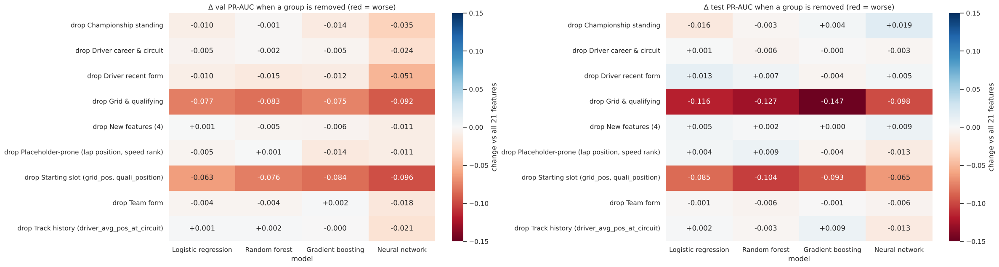

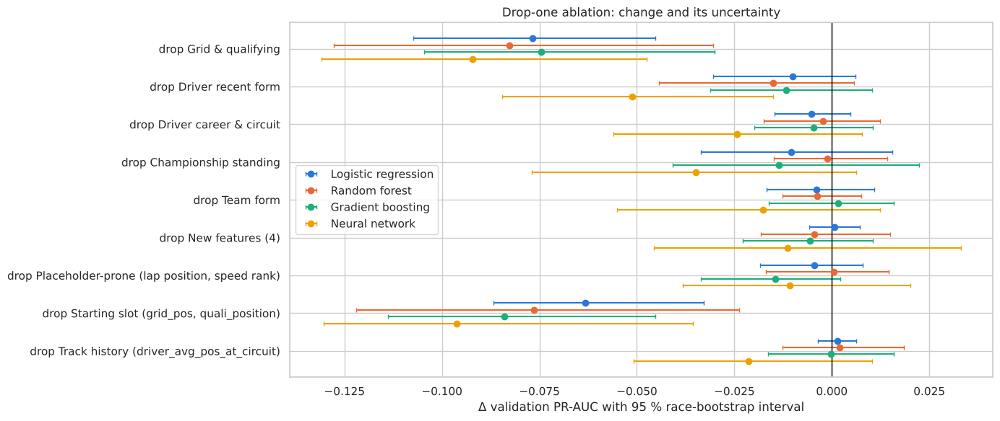

,models where the drop is clearly worse,verdict
run,,
drop Championship standing,0,no clear contribution
drop Driver career & circuit,0,no clear contribution
drop Driver recent form,1,no clear contribution
drop Grid & qualifying,4,helps
drop New features (4),0,no clear contribution
"drop Placeholder-prone (lap position, speed rank)",0,no clear contribution
"drop Starting slot (grid_pos, quali_position)",4,helps
drop Team form,0,no clear contribution
drop Track history (driver_avg_pos_at_circuit),0,no clear contribution


In [77]:
drop = ablation[ablation['run'].str.startswith('drop')]
fig, axes = plt.subplots(1, 2, figsize=(24, 6.5))
for ax, metric in zip(axes, ['Δ val PR-AUC', 'Δ test PR-AUC']):
    sns.heatmap(drop.pivot(index='run', columns='model', values=metric)[MODELS], annot=True, fmt='+.3f',
                cmap='RdBu', center=0, vmin=-0.15, vmax=0.15, ax=ax, cbar_kws={'label': 'change vs all 21 features'})
    ax.set_title(f'{metric} when a group is removed (red = worse)'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 6))
runs_order = list(drop['run'].unique())
for k, name in enumerate(MODELS):
    d = drop[drop['model'] == name].set_index('run').loc[runs_order]
    y = np.arange(len(runs_order)) + (k - 1.5) * 0.18
    ax.errorbar(d['Δ val PR-AUC'], y, xerr=[d['Δ val PR-AUC'] - d['Δ val low'], d['Δ val high'] - d['Δ val PR-AUC']],
                fmt='o', color=MODEL_COLORS[name], label=name, capsize=2)
ax.axvline(0, color='black', linewidth=1); ax.set_yticks(range(len(runs_order))); ax.set_yticklabels(runs_order)
ax.invert_yaxis(); ax.set_xlabel('Δ validation PR-AUC with 95 % race-bootstrap interval'); ax.legend()
ax.set_title('Drop-one ablation: change and its uncertainty')
plt.tight_layout(); plt.show()

helps = (drop.assign(clearly_worse=drop['Δ val high'] < 0).groupby('run')['clearly_worse'].sum()
         .rename('models where the drop is clearly worse').to_frame())
helps['verdict'] = np.where(helps.iloc[:, 0] >= 2, 'helps', 'no clear contribution')
helps

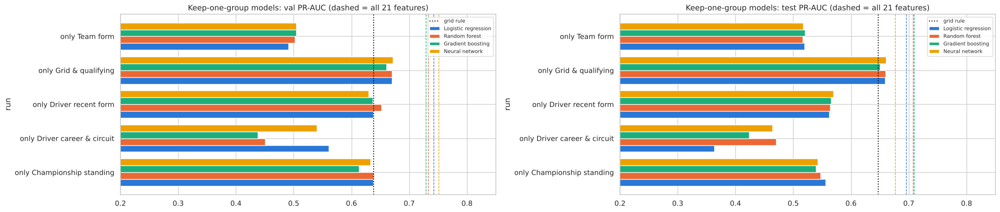

model,Logistic regression,Random forest,Gradient boosting,Neural network
run,,,,
only Championship standing,0.637,0.639,0.613,0.633
only Driver career & circuit,0.561,0.451,0.438,0.540
only Driver recent form,0.638,0.652,0.637,0.630
only Grid & qualifying,0.670,0.670,0.660,0.672
only Team form,0.491,0.502,0.504,0.504


In [78]:
only = ablation[ablation['run'].str.startswith('only')]
fig, axes = plt.subplots(1, 2, figsize=(22, 4.8))
for ax, split in zip(axes, ['val', 'test']):
    pivot = only.pivot(index='run', columns='model', values=f'{split} PR-AUC')[MODELS]
    pivot.plot(kind='barh', ax=ax, color=[MODEL_COLORS[m] for m in MODELS], width=0.8)
    for name in MODELS:
        ax.axvline(final_results.loc[name, f'{split} PR-AUC'], color=MODEL_COLORS[name], linestyle='--', linewidth=1)
    ax.axvline(final_results.loc['Baseline: grid <= 3 rule', f'{split} PR-AUC'], color='black', linestyle=':', label='grid rule')
    ax.set_xlim(0.2, 0.85); ax.set_title(f'Keep-one-group models: {split} PR-AUC (dashed = all 21 features)')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
only.pivot(index='run', columns='model', values='val PR-AUC')[MODELS].round(3)

**Observations (drop-one)**
- **Only one group passes the pre-stated rule: grid & qualifying.** Removing it costs every model 0.075–0.092
  validation PR-AUC and 0.10–0.15 on test; the intervals are far below 0 for all four models. Removing just the two
  starting-slot features does almost the same damage.
- **Every other group, removed alone, changes validation PR-AUC by less than ~0.015** for the three statistical models
  (the neural network shows larger drops, 0.02–0.05, but it is trained once and its scores move more between runs).
  None of the intervals is clearly below 0 for two models.
- **This does not mean those groups are useless — it means they overlap.** Team form, standings and recent form all
  describe "how fast is this car/driver right now"; when one group is removed the others still carry that
  information (correlations 0.6–0.8 between them, 7.3).

**Observations (keep-one)**
- **Grid & qualifying alone: 0.66–0.67 validation PR-AUC**, the same level as the grid baselines.
- Recent form alone 0.63–0.65 and championship standing 0.61–0.64 are almost as good; team form alone ~0.50 and
  career/circuit alone 0.44–0.56 are weak.
- **All groups together reach 0.73–0.75**, about **+0.07–0.08** over the best single group: the groups are weak
  substitutes individually but complement each other.
- **Our 4 new features and track history** (B4) show no clear contribution, as B4 predicted for track history.

# 15. Explainability (XAI)
**Important:** every explanation below shows what a model *relies on* to predict, **not what causes a podium**. A
feature can be important because it is correlated with the real cause (car speed, driver skill, luck), and two
correlated features can share importance in arbitrary ways.

## 15.1 Global: permutation importance for all four models
Each feature is shuffled on the **test** seasons (5 times) and the drop in PR-AUC is measured. Shuffling breaks the
link between that feature and the target while keeping its distribution.

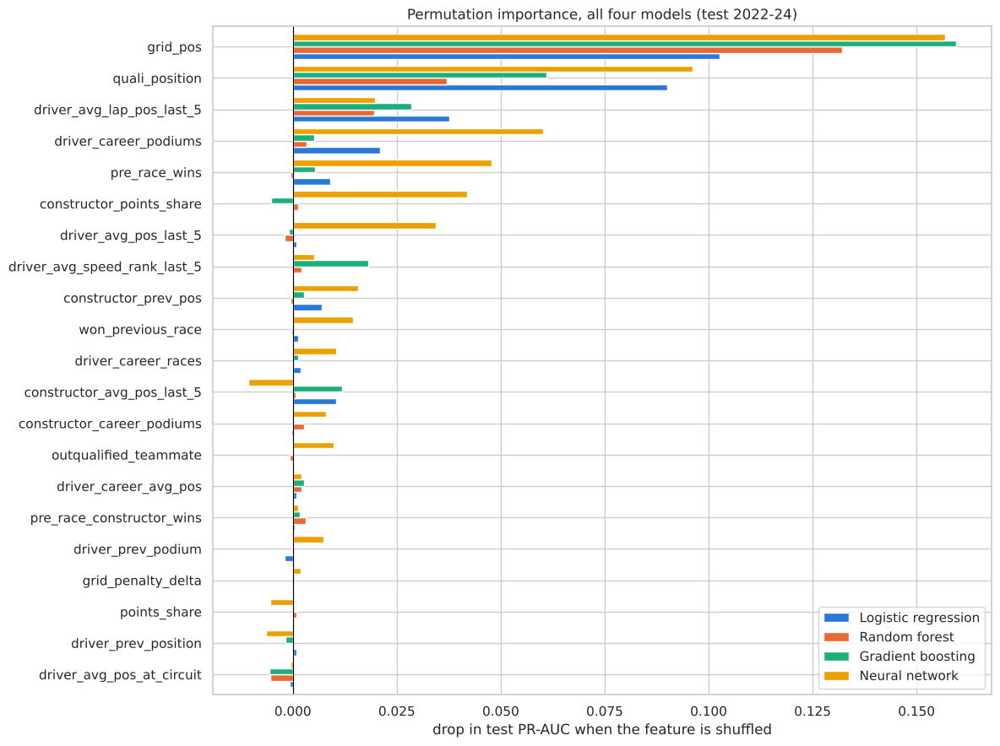

,Logistic regression,Random forest,Gradient boosting,Neural network
grid_pos,0.103,0.132,0.160,0.157
quali_position,0.090,0.037,0.061,0.096
driver_avg_lap_pos_last_5,0.038,0.020,0.029,0.020
driver_career_podiums,0.021,0.003,0.005,0.060
pre_race_wins,0.009,-0.001,0.005,0.048
constructor_points_share,0.000,0.001,-0.005,0.042
driver_avg_pos_last_5,0.001,-0.002,-0.001,0.034
driver_avg_speed_rank_last_5,0.000,0.002,0.018,0.005
constructor_prev_pos,0.007,-0.000,0.003,0.016
won_previous_race,0.001,-0.000,0.000,0.015


In [79]:
def permutation_drop(predict_fn, df, features, y, n_repeats=5, seed=0):
    # mean drop in PR-AUC when one feature column is shuffled (predict_fn takes a DataFrame)
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, predict_fn(df))
    drops = {}
    for col in features:
        scores_ = []
        for _ in range(n_repeats):
            shuffled = df.copy()
            shuffled[col] = rng.permutation(shuffled[col].values)
            scores_.append(base - average_precision_score(y, predict_fn(shuffled)))
        drops[col] = np.mean(scores_)
    return pd.Series(drops)

perm = pd.DataFrame({name: permutation_drop(lambda d, m=final_models[name]: m.predict_proba(d[MODEL_FEATURES])[:, 1],
                                            SETS['test'], MODEL_FEATURES, SETS['test']['podium'])
                     for name in MODELS})
perm = perm.loc[perm.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(12, 9))
perm.iloc[::-1].plot(kind='barh', ax=ax, color=[MODEL_COLORS[m] for m in MODELS], width=0.8)
ax.axvline(0, color='black', linewidth=0.8); ax.set_xlabel('drop in test PR-AUC when the feature is shuffled')
ax.set_title('Permutation importance, all four models (test 2022-24)')
plt.tight_layout(); plt.show()
perm.round(3).head(10)

**Observations**
- **`grid_pos` is the most important feature for all four models** (shuffling it costs 0.10–0.16 test PR-AUC),
  followed by `quali_position` (0.04–0.10).
- After those two, importance is small and spread out: lap position (0.02–0.04), speed rank (GB 0.02), career podiums.
- **The neural network spreads importance more** (career podiums 0.06, pre-race wins 0.05, constructor points share
  0.04), while the tree models concentrate on the grid. Shuffling one of several overlapping features costs little,
  because the others still carry the information — so small permutation values here do not mean "useless".

## 15.2 Global: SHAP (gradient boosting)
SHAP splits each prediction into one contribution per feature (in log-odds); the contributions add up from the
average prediction to the model's output for that row. `TreeExplainer` computes them exactly for tree models, so we
explain the gradient-boosting model. Two classes: the *no podium* plot is the exact mirror of the *podium* plot.

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


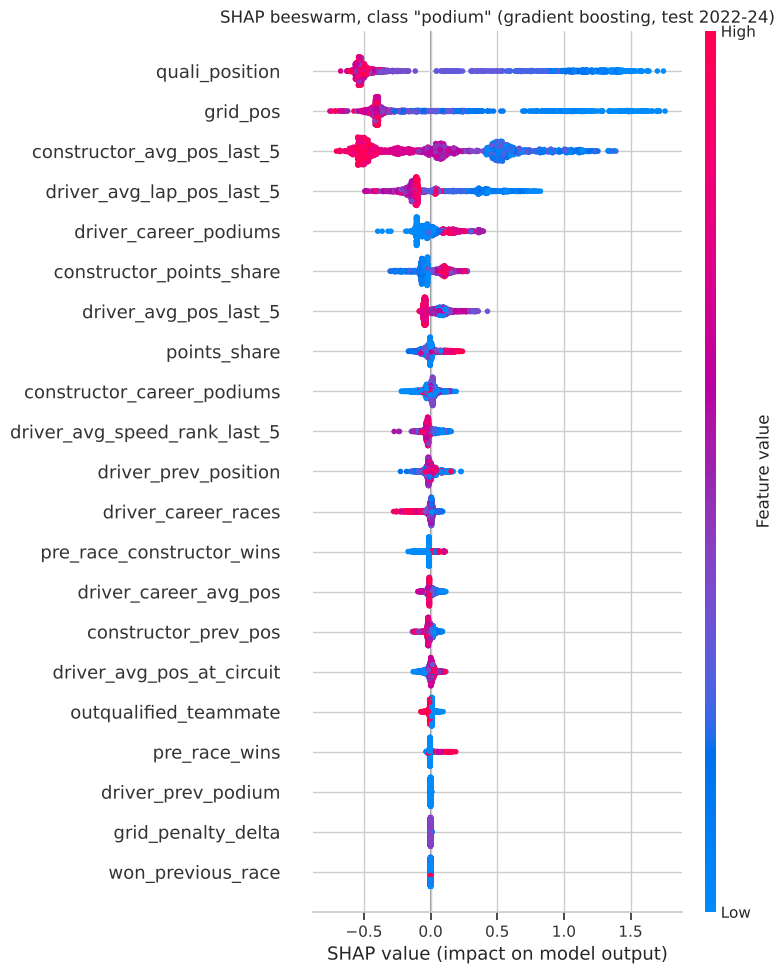

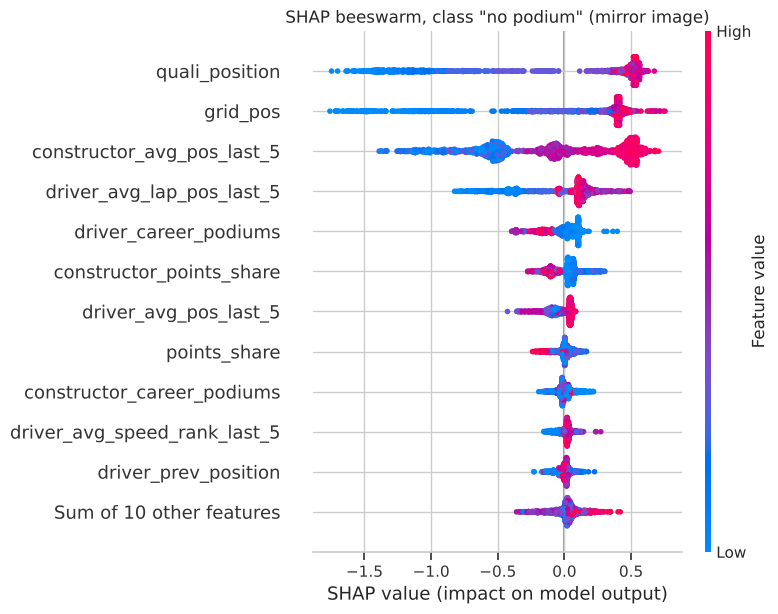

In [80]:
import shap
gb_model = final_models['Gradient boosting']
explainer = shap.TreeExplainer(gb_model)
shap_test = explainer(SETS['test'][MODEL_FEATURES])
shap.plots.beeswarm(shap_test, max_display=21, show=False)
plt.title('SHAP beeswarm, class "podium" (gradient boosting, test 2022-24)'); plt.tight_layout(); plt.show()
shap_no = shap.Explanation(values=-shap_test.values, base_values=-shap_test.base_values, data=shap_test.data,
                           feature_names=shap_test.feature_names)
shap.plots.beeswarm(shap_no, max_display=12, show=False)
plt.title('SHAP beeswarm, class "no podium" (mirror image)'); plt.tight_layout(); plt.show()

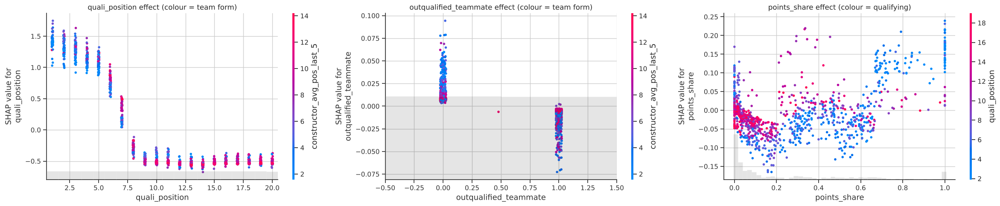

In [81]:
# How the two key interactions from the pre-training EDA look inside the model
fig, axes = plt.subplots(1, 3, figsize=(24, 5))
shap.plots.scatter(shap_test[:, 'quali_position'], color=shap_test[:, 'constructor_avg_pos_last_5'], ax=axes[0], show=False)
shap.plots.scatter(shap_test[:, 'outqualified_teammate'], color=shap_test[:, 'constructor_avg_pos_last_5'], ax=axes[1], show=False)
shap.plots.scatter(shap_test[:, 'points_share'], color=shap_test[:, 'quali_position'], ax=axes[2], show=False)
axes[0].set_title('quali_position effect (colour = team form)'); axes[1].set_title('outqualified_teammate effect (colour = team form)')
axes[2].set_title('points_share effect (colour = qualifying)')
plt.tight_layout(); plt.show()

**Observations**
- **Beeswarm:** `quali_position`, `grid_pos` and `constructor_avg_pos_last_5` dominate; low values (red = high value
  is *bad* for positions) push strongly towards podium. Team form and lap position come next.
- **`quali_position` has a step shape:** P1–P6 push up (+1 to +1.6 log-odds), the push collapses at P7–P8, and from
  P9 on every position gets the same small negative value — the same non-linear shape as the podium rate in 7.4a.
  Within a position, drivers of stronger teams (blue) get a higher push.
- **`outqualified_teammate` is tiny and slightly *negative* inside the model** (±0.05). Marginally, beating your
  teammate goes with more podiums (7.4c), but once the model already knows the qualifying position, being *ahead* of
  your teammate at a given position means the teammate is even further back — the car is weaker. A conditional effect
  can differ from the marginal correlation.
- **`points_share`** pushes up mainly above ~0.6 (title contenders), and more for good qualifiers.

## 15.3 SHAP vs the correlation matrix from before training (7.3)
Do the features the model relies on match the features that correlated with podium before training?

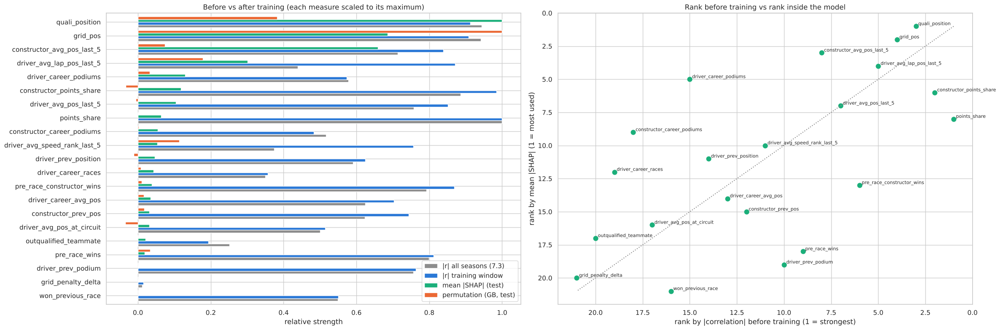

Spearman rank agreement of mean |SHAP| with |r| all seasons (7.3): 0.41
Spearman rank agreement of mean |SHAP| with |r| training window: 0.61
Spearman rank agreement of mean |SHAP| with permutation (GB, test): 0.48


,|r| all seasons (7.3),|r| training window,mean |SHAP| (test),"permutation (GB, test)",rank |r| all seasons (7.3),rank |r| training window,rank mean |SHAP| (test),"rank permutation (GB, test)"
quali_position,0.437,0.491,0.684,0.061,2,3,1,2
grid_pos,0.437,0.489,0.469,0.160,3,4,2,1
constructor_avg_pos_last_5,0.331,0.451,0.450,0.012,9,8,3,5
driver_avg_lap_pos_last_5,0.203,0.469,0.206,0.029,17,5,4,3
driver_career_podiums,0.268,0.308,0.089,0.005,13,15,5,7
constructor_points_share,0.410,0.530,0.081,-0.005,4,2,6,20
driver_avg_pos_last_5,0.351,0.458,0.071,-0.001,7,7,7,18
points_share,0.464,0.538,0.043,0.000,1,1,8,13
constructor_career_podiums,0.240,0.260,0.037,0.000,15,18,9,12
driver_avg_speed_rank_last_5,0.173,0.407,0.036,0.018,18,11,10,4


In [82]:
mean_abs_shap = pd.Series(np.abs(shap_test.values).mean(axis=0), index=MODEL_FEATURES)
corr_vs_shap = pd.DataFrame({
    '|r| all seasons (7.3)': matrix.loc[MODEL_FEATURES, 'podium'].abs(),
    '|r| training window': SETS['train'][MODEL_FEATURES].corrwith(SETS['train']['podium']).abs(),
    'mean |SHAP| (test)': mean_abs_shap,
    'permutation (GB, test)': perm['Gradient boosting']})
ranks = corr_vs_shap.rank(ascending=False).astype(int).add_prefix('rank ')
corr_vs_shap = corr_vs_shap.join(ranks).sort_values('mean |SHAP| (test)', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(24, 8))
norm = corr_vs_shap.iloc[:, :4] / corr_vs_shap.iloc[:, :4].max()
norm.iloc[::-1].plot(kind='barh', ax=axes[0], color=[GREY, BLUE, GREEN, ORANGE], width=0.8)
axes[0].set_title('Before vs after training (each measure scaled to its maximum)'); axes[0].set_xlabel('relative strength')
axes[1].scatter(corr_vs_shap['rank |r| training window'], corr_vs_shap['rank mean |SHAP| (test)'], s=60, color=GREEN)
for f, row in corr_vs_shap.iterrows():
    axes[1].annotate(f, (row['rank |r| training window'], row['rank mean |SHAP| (test)']), fontsize=8,
                     xytext=(4, 2), textcoords='offset points')
axes[1].plot([1, 21], [1, 21], color=GREY, linestyle=':'); axes[1].invert_xaxis(); axes[1].invert_yaxis()
axes[1].set(xlabel='rank by |correlation| before training (1 = strongest)', ylabel='rank by mean |SHAP| (1 = most used)',
            title='Rank before training vs rank inside the model')
plt.tight_layout(); plt.show()
for col in ['|r| all seasons (7.3)', '|r| training window', 'permutation (GB, test)']:
    print(f'Spearman rank agreement of mean |SHAP| with {col}: '
          f"{corr_vs_shap['mean |SHAP| (test)'].corr(corr_vs_shap[col], method='spearman'):.2f}")
corr_vs_shap.round(3)

**Observations: before training (correlation) vs inside the model (SHAP)**
- **Partial agreement:** the rank correlation between mean |SHAP| and |r| is **0.41** for the all-season matrix
  (7.3) and **0.61** for the training seasons. Agreement is better on the seasons the model actually learned from.
- **Agree:** the starting position (qualifying/grid) is at the top of both lists; team form and recent form are high
  in both.
- **`points_share` is #1 by correlation but only #8 by SHAP**, and `driver_prev_podium` / `pre_race_wins` (#8–10 by
  correlation) are near the bottom by SHAP. These features are strongly correlated with grid and team form
  (0.5–0.7, 7.3). Correlation counts each feature's *total* association; SHAP only credits what a feature adds
  **inside this model**, where the grid and team form already explain most of it.
- **`driver_avg_lap_pos_last_5` is #17 in the all-season matrix but #4 by SHAP** — exactly the placeholder effect found
  before training (7.4a): on real data it is one of the strongest features.
- **Conclusion:** correlation was a good first filter (no feature with high SHAP had near-zero correlation), but it
  cannot show redundancy. Several correlated features "share" one signal, and the model picks one representative per
  cluster.

## 15.4 Local explanations: many single predictions (test seasons)
Cases are picked automatically with the validation threshold of gradient boosting:
two **true positives**, three **false negatives** (missed podiums, lowest probability), three **false positives**
(highest-probability non-podiums), one **true negative** from the front rows, and one prediction **near the
threshold**. For each case: who it was, what happened in the race, a SHAP waterfall and a LIME explanation.

In [83]:
from lime.lime_tabular import LimeTabularExplainer
test_df = SETS['test'].copy()
test_df['probability'] = gb_model.predict_proba(test_df[MODEL_FEATURES])[:, 1]
test_df['predicted'] = (test_df['probability'] >= THRESHOLDS['Gradient boosting']).astype(int)
info = (test_df[['raceId', 'driverId']].reset_index()
        .merge(results[['raceId', 'driverId', 'positionOrder', 'statusId']], on=['raceId', 'driverId'])
        .merge(status[['statusId', 'status', 'category']], on='statusId')
        .merge(races[['raceId', 'name']], on='raceId')
        .merge(drivers[['driverId', 'forename', 'surname']], on='driverId').set_index('index'))
test_df = test_df.join(info[['positionOrder', 'status', 'category', 'name', 'forename', 'surname']])
test_df['driver'] = test_df['forename'] + ' ' + test_df['surname']

tp = test_df[(test_df['predicted'] == 1) & (test_df['podium'] == 1)].sort_values('probability')
fn = test_df[(test_df['predicted'] == 0) & (test_df['podium'] == 1)].sort_values('probability')
fp = test_df[(test_df['predicted'] == 1) & (test_df['podium'] == 0)].sort_values('probability')
tn = test_df[(test_df['predicted'] == 0) & (test_df['podium'] == 0) & (test_df['grid_pos'] <= 3)].sort_values('probability')
near = test_df.iloc[[np.argmin(np.abs(test_df['probability'] - THRESHOLDS['Gradient boosting']))]]
cases = pd.concat([tp.tail(1).assign(case='TP: most confident podium'), tp.head(1).assign(case='TP: least confident podium'),
                   fn.head(3).assign(case='FN: missed podium'), fp.tail(3).assign(case='FP: false alarm'),
                   tn.head(1).assign(case='TN: front-row start, correctly no podium'),
                   near.assign(case='near the threshold')])
print('threshold:', round(THRESHOLDS['Gradient boosting'], 3), '| test counts: TP', len(tp), 'FN', len(fn), 'FP', len(fp))
cases[['case', 'race_year', 'name', 'driver', 'constructor_name', 'grid_pos', 'quali_position', 'probability',
       'podium', 'positionOrder', 'status']].round(3)

threshold: 0.374 | test counts: TP 139 FN 65 FP 77


,case,race_year,name,driver,constructor_name,grid_pos,quali_position,probability,podium,positionOrder,status
25935,TP: most confident podium,2023,British Grand Prix,Max Verstappen,Red Bull,1,1.0,0.861,1,1,Finished
25692,TP: least confident podium,2022,Mexico City Grand Prix,Sergio Pérez,Red Bull,4,4.0,0.390,1,3,Finished
25999,FN: missed podium,2023,Dutch Grand Prix,Pierre Gasly,Alpine F1 Team,12,12.0,0.008,1,3,Finished
26597,FN: missed podium,2024,São Paulo Grand Prix,Pierre Gasly,Alpine F1 Team,13,15.0,0.009,1,3,Finished
25912,FN: missed podium,2023,Austrian Grand Prix,Sergio Pérez,Red Bull,15,15.0,0.055,1,3,Finished
25496,FP: false alarm,2022,British Grand Prix,Max Verstappen,Red Bull,2,2.0,0.798,0,7,Finished
26395,FP: false alarm,2024,Austrian Grand Prix,Max Verstappen,Red Bull,1,1.0,0.799,0,5,Finished
26236,FP: false alarm,2024,Australian Grand Prix,Max Verstappen,Red Bull,1,1.0,0.854,0,19,Brakes
25622,"TN: front-row start, correctly no podium",2022,Italian Grand Prix,Lando Norris,McLaren,3,7.0,0.062,0,7,Finished
25623,near the threshold,2022,Italian Grand Prix,George Russell,Mercedes,2,6.0,0.371,1,3,Finished


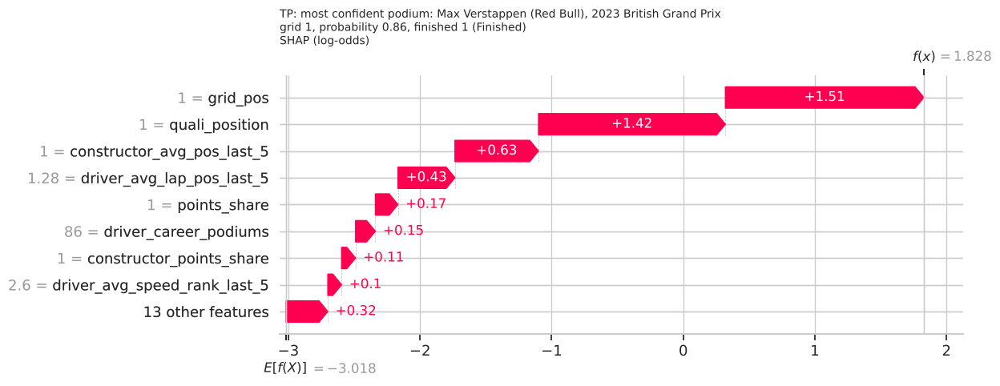

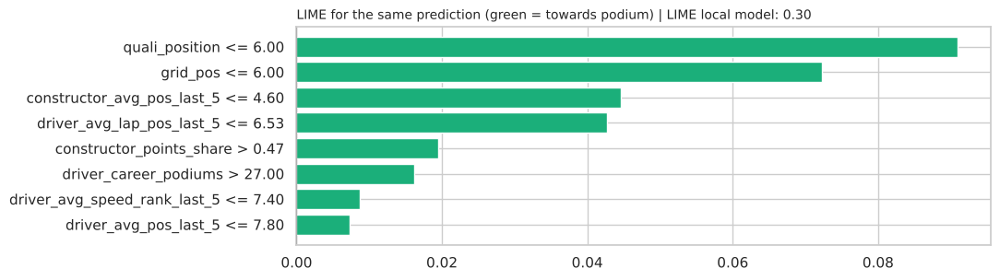

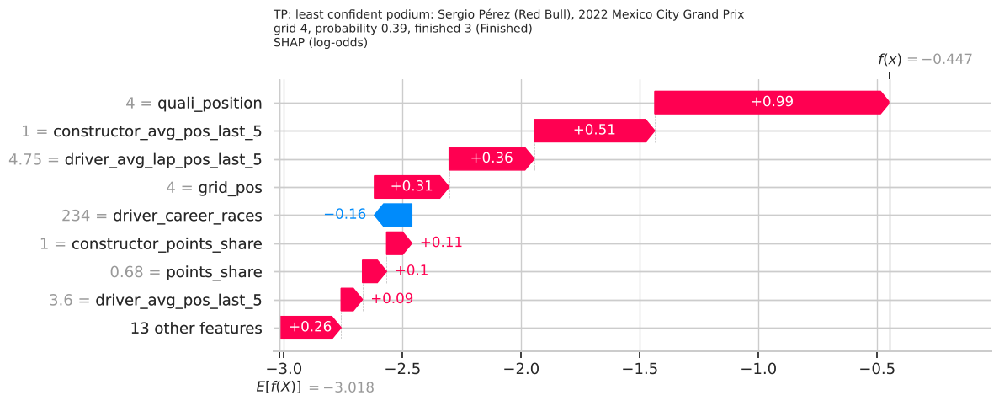

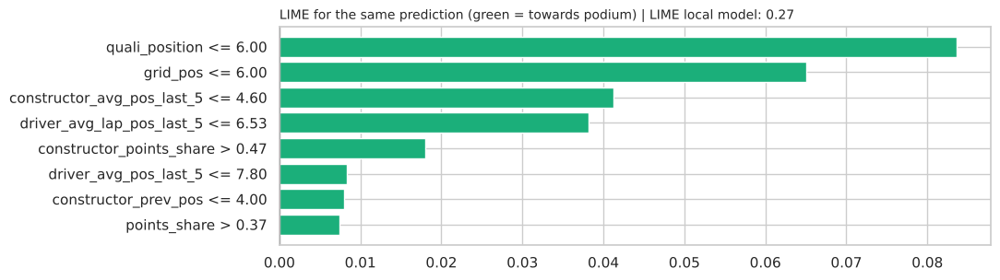

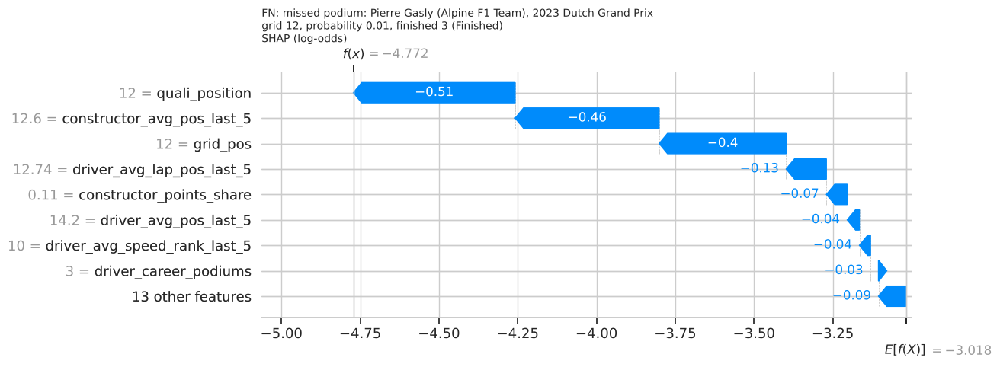

...

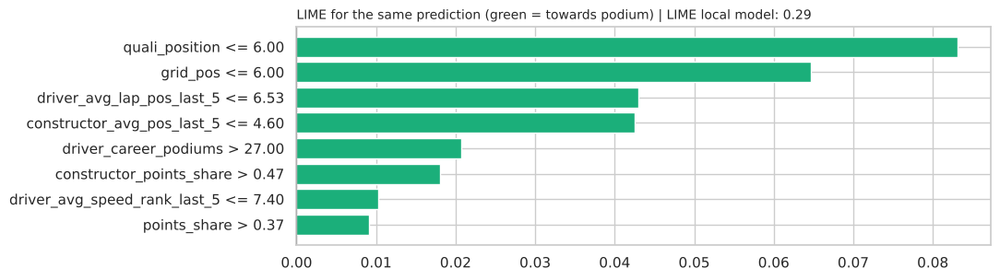

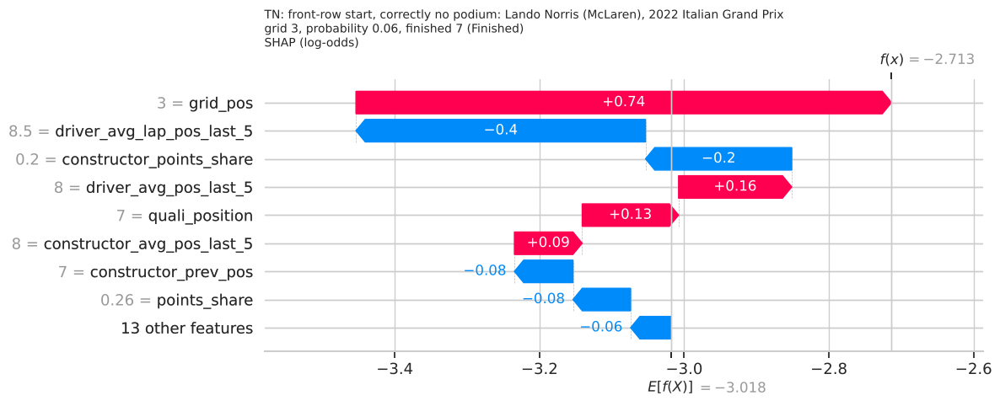

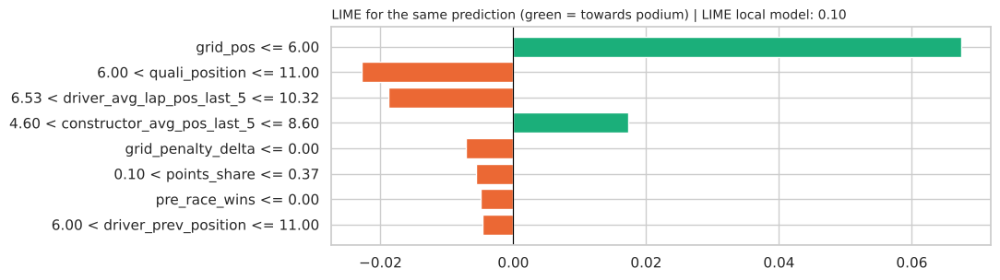

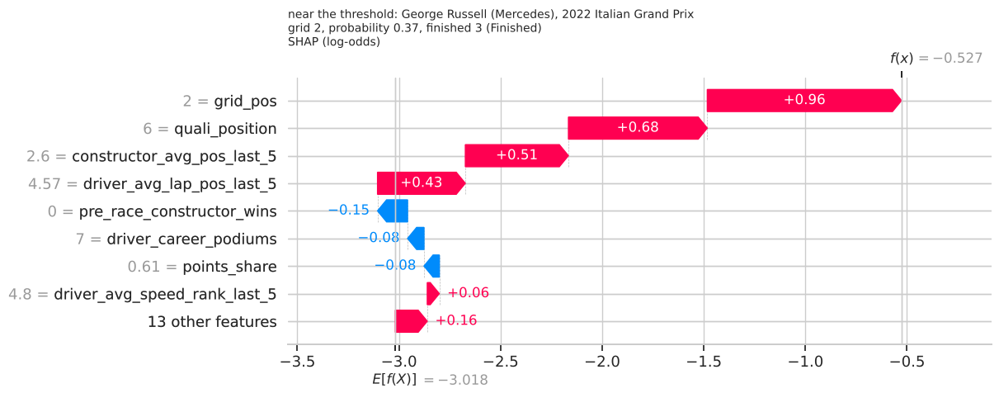

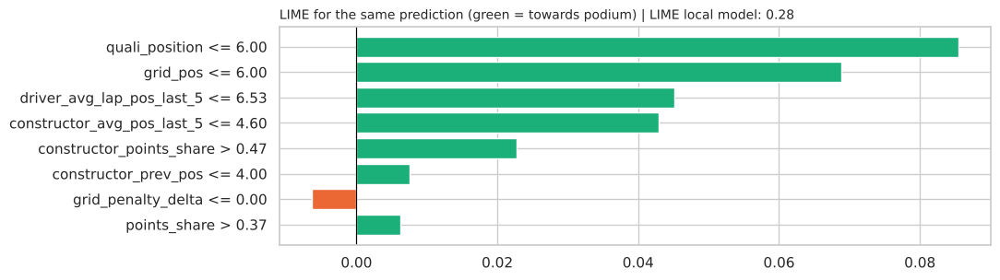

In [84]:
lime_explainer = LimeTabularExplainer(SETS['train'][MODEL_FEATURES].values, feature_names=MODEL_FEATURES,
                                      class_names=['no podium', 'podium'], mode='classification', random_state=42)
shap_cases = explainer(cases[MODEL_FEATURES])
shap_cases_display = shap.Explanation(values=shap_cases.values, base_values=shap_cases.base_values,
                                      data=np.round(cases[MODEL_FEATURES].values.astype(float), 2),
                                      feature_names=MODEL_FEATURES)
for k, (_, row) in enumerate(cases.iterrows()):
    title = (f"{row['case']}: {row['driver']} ({row['constructor_name']}), {row['race_year']} {row['name']}\n"
             f"grid {row['grid_pos']:.0f}, probability {row['probability']:.2f}, finished {row['positionOrder']:.0f} ({row['status']})")
    shap.plots.waterfall(shap_cases_display[k], max_display=9, show=False)
    plt.gcf().set_size_inches(11, 4.2)
    plt.title(title + '\nSHAP (log-odds)', fontsize=10, loc='left')
    plt.show()
    lime_exp = lime_explainer.explain_instance(row[MODEL_FEATURES].values.astype(float), gb_model.predict_proba,
                                               num_features=8)
    weights = lime_exp.as_list(label=1)[::-1]
    plt.figure(figsize=(11, 3.2))
    plt.barh([w[0] for w in weights], [w[1] for w in weights], color=[GREEN if w[1] > 0 else ORANGE for w in weights])
    plt.axvline(0, color='black', linewidth=0.8)
    plt.title(f"LIME for the same prediction (green = towards podium) | LIME local model: {lime_exp.local_pred[0]:.2f}",
              fontsize=10, loc='left')
    plt.tight_layout(); plt.show()

**What the local explanations show (SHAP and LIME agree on the main features in every case)**
- **True positives:** Verstappen, 2023 British GP (probability 0.86): pole + P1 qualifying (+1.5 and +1.4 log-odds), a
  team averaging P1 and the best running position. Pérez, 2022 Mexico (0.39, from P4): a top car but a lower slot —
  only just above the threshold.
- **Missed podiums (false negatives):** Gasly 2023 Dutch GP and 2024 São Paulo GP (from P12/P13, probability < 0.01):
  both **rain-affected races**; Pérez 2023 Austria (from P15). In each case the low grid slot and (for Alpine) weak
  team form push the prediction to almost 0. **The data has no weather or safety-car information**, so these
  podiums are unpredictable from pre-race features.
- **False alarms (false positives):** Verstappen 2024 Australia (pole, 0.85) retired with a **brake failure**; 2022
  Britain (P2) finished 7th after car damage; 2024 Austria (pole) finished 5th after a collision. Every pre-race
  signal was right; the race events were not predictable.
- **True negative:** Norris, 2022 Italy, started P3 but qualified P7 (others had penalties): the model trusts the
  qualifying position and team form and gives only 0.06 — he finished 7th. This is B3 in action: qualifying holds
  information beyond the grid slot.
- **Near the threshold:** Russell, 2022 Italy (from P2 after penalties, qualified P6): 0.371 vs threshold 0.374 —
  qualifying and grid pull in opposite directions; he finished 3rd.

## 15.5 Error analysis: which features push predictions the wrong way?
We look at the **validation** errors (so that anything we change is not chosen on the test seasons). For every
false negative we find the feature with the **strongest push downwards** (most negative SHAP value), and for every
false positive the feature with the **strongest push upwards**. Features that are often the main culprit are
candidates for an error-driven ablation.

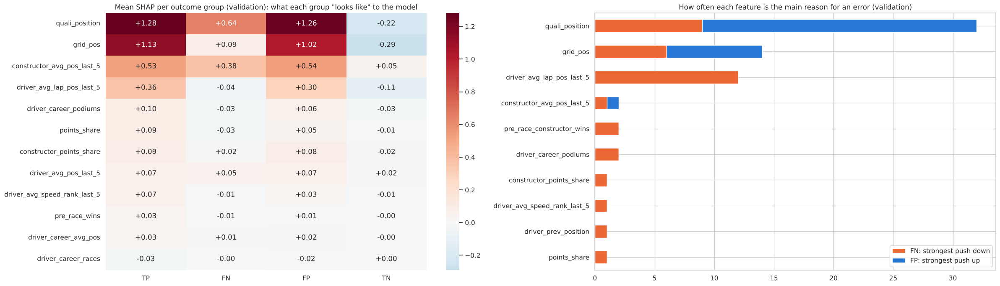

{'TP': 81, 'FN': 36, 'FP': 32, 'TN': 631}


,FN: strongest push down,FP: strongest push up,total
quali_position,9,23,32
grid_pos,6,8,14
driver_avg_lap_pos_last_5,12,0,12
constructor_avg_pos_last_5,1,1,2
pre_race_constructor_wins,2,0,2
driver_career_podiums,2,0,2
constructor_points_share,1,0,1
driver_avg_speed_rank_last_5,1,0,1


In [85]:
val_df = SETS['val'].copy()
val_df['probability'] = gb_model.predict_proba(val_df[MODEL_FEATURES])[:, 1]
val_df['predicted'] = (val_df['probability'] >= THRESHOLDS['Gradient boosting']).astype(int)
shap_val = explainer(val_df[MODEL_FEATURES])
sv = pd.DataFrame(shap_val.values, columns=MODEL_FEATURES, index=val_df.index)
groups = {'TP': (val_df['predicted'] == 1) & (val_df['podium'] == 1), 'FN': (val_df['predicted'] == 0) & (val_df['podium'] == 1),
          'FP': (val_df['predicted'] == 1) & (val_df['podium'] == 0), 'TN': (val_df['predicted'] == 0) & (val_df['podium'] == 0)}
mean_shap = pd.DataFrame({g: sv[mask].mean() for g, mask in groups.items()})
culprit = pd.DataFrame({'FN: strongest push down': sv[groups['FN']].idxmin(axis=1).value_counts(),
                        'FP: strongest push up': sv[groups['FP']].idxmax(axis=1).value_counts()}).fillna(0).astype(int)
culprit['total'] = culprit.sum(axis=1)
culprit = culprit.sort_values('total', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(24, 7))
sns.heatmap(mean_shap.loc[mean_shap.abs().max(axis=1).sort_values(ascending=False).index[:12]], annot=True, fmt='+.2f',
            cmap='RdBu_r', center=0, ax=axes[0])
axes[0].set_title('Mean SHAP per outcome group (validation): what each group "looks like" to the model')
culprit[['FN: strongest push down', 'FP: strongest push up']].head(10).iloc[::-1].plot(kind='barh', stacked=True, ax=axes[1],
                                                                                      color=[ORANGE, BLUE])
axes[1].set_title('How often each feature is the main reason for an error (validation)')
plt.tight_layout(); plt.show()
print({g: int(m.sum()) for g, m in groups.items()})
culprit.head(8)

In [86]:
# What do the errors have in common?  (validation, gradient boosting)
err = val_df.merge(results[['raceId', 'driverId', 'statusId']], on=['raceId', 'driverId'], how='left') \
            .merge(status[['statusId', 'category']], on='statusId', how='left')
err['outcome'] = np.select([err['predicted'].eq(1) & err['podium'].eq(1), err['predicted'].eq(0) & err['podium'].eq(1),
                            err['predicted'].eq(1) & err['podium'].eq(0)], ['TP', 'FN', 'FP'], 'TN')
profile = err.groupby('outcome').agg(rows=('podium', 'size'), median_grid=('grid_pos', 'median'),
                                     median_team_form=('constructor_avg_pos_last_5', 'median'),
                                     median_points_share=('points_share', 'median'),
                                     share_did_not_finish=('category', lambda s: (s != 'Finished').mean()))
profile.round(2)

,rows,median_grid,median_team_form,median_points_share,share_did_not_finish
outcome,,,,,
FN,36,5.0,6.0,0.29,0.00
FP,32,2.0,2.7,0.64,0.41
TN,631,12.0,8.8,0.08,0.16
TP,81,2.0,2.2,0.91,0.00


**Observations (validation 2020–21: 81 TP, 36 FN, 32 FP, 631 TN)**
- **The main "culprit" is almost always the starting position:** `quali_position` is the strongest wrong-direction
  push in 32 of the 68 errors, `grid_pos` in 14, lap position in 12. False negatives are drivers starting further
  back (median P5) with a midfield car; false positives start at the front (median P2) in a top car.
- **41 % of false positives did not finish** (vs 16 % of true negatives and 0 % of true positives): a large share
  of false alarms are retirements — events no pre-race feature can see.
- So the features are not "wrong": they point the right way, and the errors come from what happens during the race.

## 15.6 Error-driven ablation
The features that are most often the main reason for a validation error are removed one, two and three at a time;
all four models are retrained and compared with the full models on validation **and** test, together with the
number of false negatives and false positives on validation.

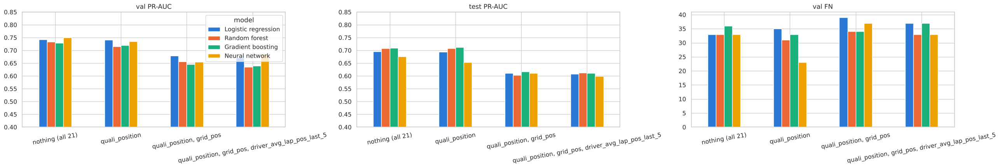

val PR-AUC                                                        test PR-AUC                                                 
model                                              Gradient boosting Logistic regression Neural network Random forest Gradient boosting Logistic regression Neural network Random forest
removed                                                                                                                                                                                 
nothing (all 21)                                               0.729               0.743          0.751         0.733             0.709               0.696          0.677         0.707
quali_position                                                 0.719               0.741          0.735         0.715             0.712               0.694          0.653         0.708
quali_position, grid_pos                                       0.645               0.679          0.655         0.656             0.616               0.611          0.611         0.604
quali_position, grid_pos, driver_avg_lap_pos_la...             0.639               0.671          0.684         0.634             0.611               0.608          0.598         0.613

In [87]:
culprits = list(culprit.index[:3])
err_rows = []
for k in range(1, 4):
    removed = culprits[:k]
    feats = [f for f in MODEL_FEATURES if f not in removed]
    for name in MODELS:
        _, probs = train_and_predict(name, feats, SETS, BEST_PARAMS[name])
        r = evaluate(name, probs, SETS)
        pred = (probs['val'] >= r['threshold']).astype(int); y = SETS['val']['podium'].values
        err_rows.append({'removed': ', '.join(removed), 'model': name, 'val PR-AUC': r['val PR-AUC'],
                         'test PR-AUC': r['test PR-AUC'], 'test F1': r['test F1'],
                         'val FN': int(((pred == 0) & (y == 1)).sum()), 'val FP': int(((pred == 1) & (y == 0)).sum())})
for name in MODELS:
    pred = (final_probs[name]['val'] >= THRESHOLDS[name]).astype(int); y = SETS['val']['podium'].values
    err_rows.append({'removed': 'nothing (all 21)', 'model': name, 'val PR-AUC': final_results.loc[name, 'val PR-AUC'],
                     'test PR-AUC': final_results.loc[name, 'test PR-AUC'], 'test F1': final_results.loc[name, 'test F1'],
                     'val FN': int(((pred == 0) & (y == 1)).sum()), 'val FP': int(((pred == 1) & (y == 0)).sum())})
error_ablation = pd.DataFrame(err_rows)
fig, axes = plt.subplots(1, 3, figsize=(26, 4.5))
for ax, metric in zip(axes, ['val PR-AUC', 'test PR-AUC', 'val FN']):
    error_ablation.pivot(index='removed', columns='model', values=metric)[MODELS].plot(
        kind='bar', ax=ax, color=[MODEL_COLORS[m] for m in MODELS], rot=10, legend=(metric == 'val PR-AUC'))
    ax.set_title(metric); ax.set_xlabel('')
    if 'PR-AUC' in metric:
        ax.set_ylim(0.4, 0.85)
plt.tight_layout(); plt.show()
error_ablation.pivot(index='removed', columns='model', values=['val PR-AUC', 'test PR-AUC']).round(3)

**Observations**
- Removing `quali_position` alone changes little (the grid carries almost the same information, 0.96 correlation):
  validation −0.002 to −0.018, test −0.002 to −0.024.
- **Removing quali and grid together destroys performance** (validation −0.06 to −0.10, test −0.08 to −0.10), and
  the number of missed podiums **rises** instead of falling.
- **Conclusion:** the features that "cause" the errors are the same ones that make the correct predictions. Errors
  come from race events (rain, retirements, collisions), not from misleading features, so removing them is not a fix.
  The full 21-feature set stays.

# 16. Bonus: a race-aware tier
The required models treat every row on its own. But a podium is **relative**: exactly three drivers per race get
one, so what matters is how a driver compares with **the other drivers in the same race**. The bonus tier adds this
structure in three steps, each evaluated on its own (no improvement is guaranteed, so we measure every step):

1. **Race-relative features:** for the key form/strength features, the driver's **rank inside this race** and his
   **gap to the best driver in this race**, plus the field size. All are pre-race values of drivers in the same
   race, so they are leakage-safe.
2. **Ensemble:** the average probability of the four models (different models make different mistakes).
3. **Race normalisation:** probabilities inside a race are rescaled so they add up to 3 (the number of podium
   places), capped at 1.

Settings are the tuned ones from Section 11; everything is chosen on validation.

In [88]:
RELATIVE_BASE = {'constructor_avg_pos_last_5': True, 'driver_avg_pos_last_5': True, 'driver_avg_lap_pos_last_5': True,
                 'driver_career_avg_pos': True, 'points_share': False, 'constructor_points_share': False}  # True = lower is better

def add_race_relative(df):
    # rank inside the race (1 = best) and gap to the best value in the race, for each key feature
    out = df.copy()
    g = out.groupby('raceId')
    for col, lower_is_better in RELATIVE_BASE.items():
        out[col + '_race_rank'] = g[col].rank(ascending=lower_is_better, method='min')
        best = g[col].transform('min' if lower_is_better else 'max')
        out[col + '_gap_to_best'] = (out[col] - best).abs()
    out['field_size'] = g['driverId'].transform('size')
    return out

RELATIVE_FEATURES = [f'{c}_{s}' for c in RELATIVE_BASE for s in ['race_rank', 'gap_to_best']] + ['field_size']
TIER_FEATURES = MODEL_FEATURES + RELATIVE_FEATURES

def race_normalise(race_ids, p):
    # rescale probabilities so that each race sums to 3 podium places (capped at 1)
    s = pd.Series(p).groupby(np.asarray(race_ids)).transform('sum').values
    return np.clip(3 * p / s, 0, 1)

class PodiumPredictor:
    # one interface for every candidate: single model or ensemble, with or without race-aware steps
    def __init__(self, name, models, features, race_relative=False, normalise=False):
        self.name, self.models, self.features = name, models, features
        self.race_relative, self.normalise = race_relative, normalise

    def predict_proba(self, df):
        X = add_race_relative(df) if self.race_relative else df
        p = np.mean([m.predict_proba(X[self.features])[:, 1] for m in self.models], axis=0)
        return race_normalise(df['raceId'].values, p) if self.normalise else p

data_rel = add_race_relative(data)
SETS_REL = split_by_season(data_rel, START)
print(len(RELATIVE_FEATURES), 'race-relative features:', RELATIVE_FEATURES)
SETS_REL['train'][RELATIVE_FEATURES + ['podium']].corr()['podium'].drop('podium').sort_values().round(3)

13 race-relative features: ['constructor_avg_pos_last_5_race_rank', 'constructor_avg_pos_last_5_gap_to_best', 'driver_avg_pos_last_5_race_rank', 'driver_avg_pos_last_5_gap_to_best', 'driver_avg_lap_pos_last_5_race_rank', 'driver_avg_lap_pos_last_5_gap_to_best', 'driver_career_avg_pos_race_rank', 'driver_career_avg_pos_gap_to_best', 'points_share_race_rank', 'points_share_gap_to_best', 'constructor_points_share_race_rank', 'constructor_points_share_gap_to_best', 'field_size']


constructor_points_share_gap_to_best     -0.487
points_share_gap_to_best                 -0.475
driver_avg_lap_pos_last_5_race_rank      -0.462
driver_avg_lap_pos_last_5_gap_to_best    -0.461
constructor_avg_pos_last_5_race_rank     -0.452
constructor_avg_pos_last_5_gap_to_best   -0.446
driver_avg_pos_last_5_gap_to_best        -0.446
points_share_race_rank                   -0.440
constructor_points_share_race_rank       -0.438
driver_avg_pos_last_5_race_rank          -0.429
driver_career_avg_pos_race_rank          -0.384
driver_career_avg_pos_gap_to_best        -0.370
field_size                               -0.030
Name: podium, dtype: float64

In [89]:
tier_models = {}
for name in MODELS:
    tier_models[name], _ = train_and_predict(name, TIER_FEATURES, SETS_REL, BEST_PARAMS[name])

CANDIDATES = {name: PodiumPredictor(name, [final_models[name]], MODEL_FEATURES) for name in MODELS}
CANDIDATES.update({
    'Ensemble of 4 (21 features)': PodiumPredictor('Ensemble of 4 (21 features)', list(final_models.values()), MODEL_FEATURES),
    'Ensemble of 4 + race normalisation': PodiumPredictor('Ensemble of 4 + race normalisation', list(final_models.values()),
                                                          MODEL_FEATURES, normalise=True)})
for name in MODELS:
    CANDIDATES[f'{name} + race-relative'] = PodiumPredictor(f'{name} + race-relative', [tier_models[name]], TIER_FEATURES,
                                                            race_relative=True)
CANDIDATES['TIER: ensemble + race-relative'] = PodiumPredictor('TIER: ensemble + race-relative', list(tier_models.values()),
                                                               TIER_FEATURES, race_relative=True)
CANDIDATES['TIER: ensemble + race-relative + normalisation'] = PodiumPredictor(
    'TIER: ensemble + race-relative + normalisation', list(tier_models.values()), TIER_FEATURES, race_relative=True, normalise=True)

candidate_probs = {n: {s: c.predict_proba(d) for s, d in SETS.items()} for n, c in CANDIDATES.items()}
candidates = pd.DataFrame([evaluate(n, candidate_probs[n], SETS) for n in CANDIDATES]).set_index('model')
candidates[['val PR-AUC', 'test PR-AUC', 'val ROC-AUC', 'test ROC-AUC', 'val F1', 'test F1', 'test precision', 'test recall']].round(3)

,val PR-AUC,test PR-AUC,val ROC-AUC,test ROC-AUC,val F1,test F1,test precision,test recall
model,,,,,,,,
Logistic regression,0.743,0.696,0.928,0.935,0.715,0.671,0.624,0.725
Random forest,0.733,0.707,0.935,0.939,0.709,0.675,0.650,0.701
Gradient boosting,0.729,0.709,0.932,0.937,0.704,0.662,0.644,0.681
Neural network,0.751,0.677,0.931,0.929,0.718,0.661,0.617,0.711
Ensemble of 4 (21 features),0.744,0.715,0.934,0.938,0.712,0.676,0.644,0.711
Ensemble of 4 + race normalisation,0.728,0.718,0.935,0.939,0.708,0.681,0.618,0.760
Logistic regression + race-relative,0.746,0.695,0.929,0.935,0.709,0.671,0.632,0.716
Random forest + race-relative,0.742,0.706,0.935,0.938,0.715,0.685,0.602,0.794
Gradient boosting + race-relative,0.729,0.700,0.926,0.936,0.708,0.655,0.536,0.843


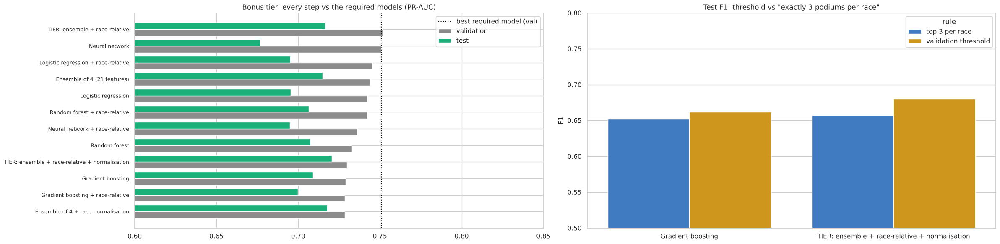

,model,split,rule,F1,precision,recall
0,Gradient boosting,val,top 3 per race,0.684,0.684,0.684
1,Gradient boosting,val,validation threshold,0.704,0.717,0.692
2,Gradient boosting,test,top 3 per race,0.652,0.652,0.652
3,Gradient boosting,test,validation threshold,0.662,0.644,0.681
4,TIER: ensemble + race-relative + normalisation,val,top 3 per race,0.701,0.701,0.701
5,TIER: ensemble + race-relative + normalisation,val,validation threshold,0.714,0.694,0.735
6,TIER: ensemble + race-relative + normalisation,test,top 3 per race,0.657,0.657,0.657
7,TIER: ensemble + race-relative + normalisation,test,validation threshold,0.680,0.618,0.755


In [90]:
# Decision rule natural for F1: exactly three podiums per race (no threshold needed)
def top3_per_race(df, p):
    return (pd.Series(p, index=df.index).groupby(df['raceId'].values).rank(ascending=False, method='first') <= 3).astype(int).values

top3_rows = []
for n in ['Gradient boosting', 'TIER: ensemble + race-relative + normalisation']:
    for s in ['val', 'test']:
        pred = top3_per_race(SETS[s], candidate_probs[n][s]); y = SETS[s]['podium']
        top3_rows.append({'model': n, 'split': s, 'rule': 'top 3 per race', 'F1': f1_score(y, pred),
                          'precision': precision_score(y, pred), 'recall': recall_score(y, pred)})
        pred = (candidate_probs[n][s] >= candidates.loc[n, 'threshold']).astype(int)
        top3_rows.append({'model': n, 'split': s, 'rule': 'validation threshold', 'F1': f1_score(y, pred),
                          'precision': precision_score(y, pred), 'recall': recall_score(y, pred)})
top3 = pd.DataFrame(top3_rows)

fig, axes = plt.subplots(1, 2, figsize=(24, 6))
order = candidates.sort_values('val PR-AUC').index
y = np.arange(len(order))
axes[0].barh(y - 0.2, candidates.loc[order, 'val PR-AUC'], 0.4, color=GREY, label='validation')
axes[0].barh(y + 0.2, candidates.loc[order, 'test PR-AUC'], 0.4, color=GREEN, label='test')
axes[0].set_yticks(y); axes[0].set_yticklabels(order, fontsize=9); axes[0].set_xlim(0.6, 0.85)
axes[0].axvline(candidates.loc[MODELS, 'val PR-AUC'].max(), color='black', linestyle=':', label='best required model (val)')
axes[0].legend(); axes[0].set_title('Bonus tier: every step vs the required models (PR-AUC)')
sns.barplot(data=top3[top3['split'] == 'test'], x='model', y='F1', hue='rule', ax=axes[1], palette=[BLUE, YELLOW])
axes[1].set_ylim(0.5, 0.8); axes[1].set_title('Test F1: threshold vs "exactly 3 podiums per race"'); axes[1].set_xlabel('')
plt.tight_layout(); plt.show()
top3.round(3)

**Observations (each step measured separately)**
- **Race-relative features** are strongly linked with podium on their own (|r| 0.37–0.49, e.g. gap to the best team
  in the race −0.49). Added to a single model they help logistic regression and random forest a little on
  validation (+0.003 / +0.009) and change little on test.
- **Ensembling the four models** gives the most stable gain: on test **0.715**, above every single model (best 0.709).
- **The full tier (ensemble + race-relative features) has the best validation PR-AUC of all candidates (0.752)** and a
  test PR-AUC of **0.717**: better than every required model on test (+0.008 over the best, gradient boosting, and
  +0.040 over the neural network that was best on validation). On validation the margin over the neural network is
  only 0.001, so the honest summary is: **the tier is at least as good as the best required model on validation and
  better on test, but not by a large or guaranteed margin**.
- **Race normalisation** (probabilities sum to 3 per race) raises test PR-AUC slightly (0.721) but lowers validation
  (0.730), so by our rule it is not chosen.
- **"Exactly 3 podiums per race"** sounds natural but gives a *lower* F1 than the validation threshold (test 0.657 vs
  0.680): some races have 2 clear favourites and an open third place, others have 4–5 candidates, and a fixed count
  ignores that.

# 17. Final model and summary of all experiments
## 17.1 Choosing the final model
**Rule (stated before looking at test):** among all candidates of Sections 11 and 16, the one with the **highest
validation PR-AUC** becomes the final model. Its test scores are then reported once.

In [91]:
FINAL_NAME = candidates['val PR-AUC'].idxmax()
FINAL = CANDIDATES[FINAL_NAME]
FINAL_THRESHOLD = candidates.loc[FINAL_NAME, 'threshold']
final_probs_best = candidate_probs[FINAL_NAME]
print('final model:', FINAL_NAME, '| features:', len(FINAL.features), '| threshold (validation):', round(FINAL_THRESHOLD, 3))

best_required = candidates.loc[MODELS, 'val PR-AUC'].idxmax()
cols = [f'{s} {m}' for s in ['train', 'val', 'test'] for m in ['PR-AUC', 'ROC-AUC', 'F1', 'precision', 'recall']]
headline = pd.concat([candidates.loc[list(dict.fromkeys([FINAL_NAME, best_required])), cols],
                      final_results.loc[['Baseline: grid <= 3 rule'], cols]]).T
headline.round(3)

final model: TIER: ensemble + race-relative | features: 34 | threshold (validation): 0.403


model,TIER: ensemble + race-relative,Neural network,Baseline: grid <= 3 rule
train PR-AUC,0.761,0.729,0.626
train ROC-AUC,0.952,0.946,0.909
train F1,0.707,0.694,0.646
train precision,0.624,0.628,0.647
train recall,0.815,0.775,0.646
val PR-AUC,0.752,0.751,0.639
val ROC-AUC,0.933,0.931,0.909
val F1,0.715,0.718,0.692
val precision,0.682,0.718,0.692
val recall,0.752,0.718,0.692


## 17.2 The final model visualised
Features used, what drives it (permutation importance on the test seasons, computed through the full pipeline so
race-relative features are recomputed after each shuffle), its curves, confusion matrix, calibration and per-season
scores, next to the best required model and the grid rule.

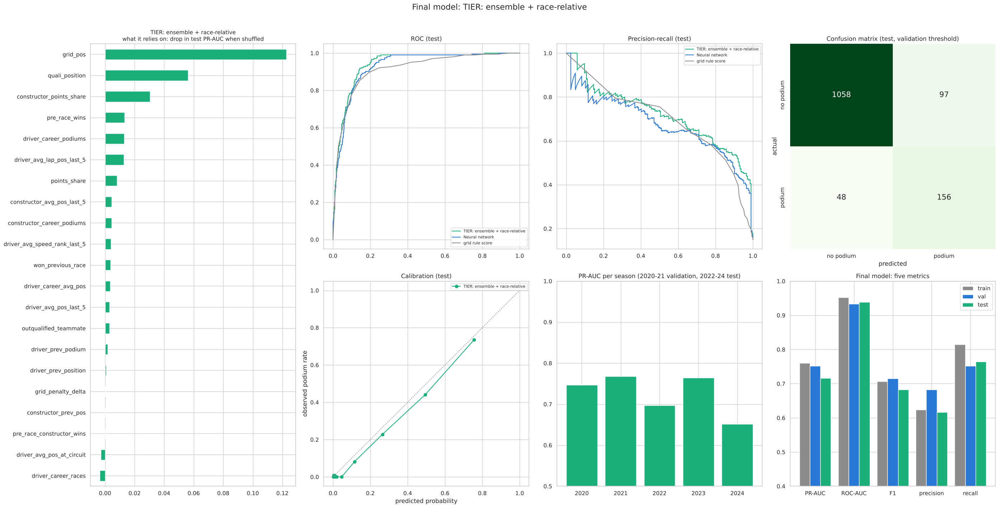

features used: ['quali_position', 'grid_pos', 'outqualified_teammate', 'grid_penalty_delta', 'driver_prev_position', 'driver_prev_podium', 'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5', 'driver_avg_speed_rank_last_5', 'won_previous_race', 'driver_career_avg_pos', 'driver_career_podiums', 'driver_career_races', 'driver_avg_pos_at_circuit', 'pre_race_wins', 'points_share', 'constructor_prev_pos', 'constructor_avg_pos_last_5', 'constructor_career_podiums', 'pre_race_constructor_wins', 'constructor_points_share', 'constructor_avg_pos_last_5_race_rank', 'constructor_avg_pos_last_5_gap_to_best', 'driver_avg_pos_last_5_race_rank', 'driver_avg_pos_last_5_gap_to_best', 'driver_avg_lap_pos_last_5_race_rank', 'driver_avg_lap_pos_last_5_gap_to_best', 'driver_career_avg_pos_race_rank', 'driver_career_avg_pos_gap_to_best', 'points_share_race_rank', 'points_share_gap_to_best', 'constructor_points_share_race_rank', 'constructor_points_share_gap_to_best', 'field_size']


In [92]:
final_perm = permutation_drop(FINAL.predict_proba, SETS['test'], MODEL_FEATURES, SETS['test']['podium'], n_repeats=3)
y_test = SETS['test']['podium']
fig = plt.figure(figsize=(28, 14))
gs = fig.add_gridspec(2, 4)
ax = fig.add_subplot(gs[:, 0])
final_perm.sort_values().plot(kind='barh', ax=ax, color=GREEN)
ax.set_title(f'{FINAL_NAME}\nwhat it relies on: drop in test PR-AUC when shuffled', fontsize=11)
for k, (title, fn) in enumerate([('ROC (test)', roc_curve), ('Precision-recall (test)', precision_recall_curve)]):
    ax = fig.add_subplot(gs[0, 1 + k])
    for name, p, color in [(FINAL_NAME, final_probs_best['test'], GREEN), (best_required, candidate_probs[best_required]['test'], BLUE),
                           ('grid rule score', rule_probs['test'], GREY)]:
        a, b, _ = fn(y_test, p)
        ax.plot(a, b, color=color, label=name) if fn is roc_curve else ax.plot(b, a, color=color, label=name)
    ax.set_title(title); ax.legend(fontsize=8)
ax = fig.add_subplot(gs[0, 3])
cm = confusion_matrix(y_test, (final_probs_best['test'] >= FINAL_THRESHOLD).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax, xticklabels=['no podium', 'podium'],
            yticklabels=['no podium', 'podium'], annot_kws={'size': 15})
ax.set(title='Confusion matrix (test, validation threshold)', xlabel='predicted', ylabel='actual')
ax = fig.add_subplot(gs[1, 1])
frac, mean_p = calibration_curve(y_test, final_probs_best['test'], n_bins=10, strategy='quantile')
ax.plot(mean_p, frac, marker='o', color=GREEN, label=FINAL_NAME); ax.plot([0, 1], [0, 1], linestyle=':', color=GREY)
ax.set(title='Calibration (test)', xlabel='predicted probability', ylabel='observed podium rate'); ax.legend(fontsize=8)
ax = fig.add_subplot(gs[1, 2])
seasons = [(y, d) for split in ['val', 'test'] for y, d in SETS[split].groupby('race_year')]
ax.bar([str(y) for y, _ in seasons], [average_precision_score(d['podium'], FINAL.predict_proba(d)) for _, d in seasons], color=GREEN)
ax.set_ylim(0.5, 1); ax.set_title('PR-AUC per season (2020-21 validation, 2022-24 test)')
ax = fig.add_subplot(gs[1, 3])
mets = ['PR-AUC', 'ROC-AUC', 'F1', 'precision', 'recall']
for k, (s, color) in enumerate([('train', GREY), ('val', BLUE), ('test', GREEN)]):
    ax.bar(np.arange(5) + (k - 1) * 0.27, [candidates.loc[FINAL_NAME, f'{s} {m}'] for m in mets], 0.27, color=color, label=s)
ax.set_xticks(range(5)); ax.set_xticklabels(mets); ax.set_ylim(0.4, 1); ax.legend(); ax.set_title('Final model: five metrics')
plt.suptitle(f'Final model: {FINAL_NAME}', fontsize=16, y=1.01)
plt.tight_layout(); plt.show()
print('features used:', FINAL.features)

**Final model: the race-aware tier (average of logistic regression, random forest, gradient boosting and the shallow
neural network, each trained on the 21 features + 13 race-relative features)**
- **Test 2022–24: PR-AUC 0.717, ROC-AUC 0.939, F1 0.683, precision 0.617, recall 0.765**; it finds 156 of the 204
  podiums, with 97 false alarms.
- **Train / validation / test PR-AUC = 0.761 / 0.752 / 0.717**: a small gap, no strong overfitting.
- **What it relies on:** the grid slot (−0.12 PR-AUC when shuffled) and qualifying (−0.06), then the team's share of
  the leader's points, season wins, career podiums and lap position — consistent with SHAP and the ablation.
- **Calibration** is close to the diagonal (a predicted 50 % is ~45 % in reality), so its probabilities can be read
  as chances.
- **Per season** it is best in 2021/2023 (~0.76) and worst in 2024 (0.65), like all models.
- Compared with the grid rule its PR curve is higher at high recall: it finds podiums from further back (e.g. strong
  cars after a penalty) that the rule cannot.

## 17.3 All experiments side by side
Every experiment of Sections 10–16 on one page (validation PR-AUC, the score used for decisions, next to test).

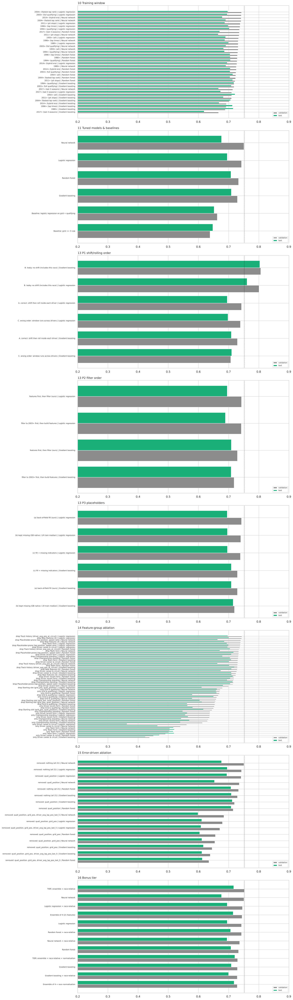

142 experiment results | dotted line = validation PR-AUC of the final model


,family,experiment,val PR-AUC,test PR-AUC
45,13 P1 shift/rolling order,B. leaky: no shift (includes this race) | Grad...,0.806,0.803
44,13 P1 shift/rolling order,B. leaky: no shift (includes this race) | Logi...,0.801,0.761
140,16 Bonus tier,TIER: ensemble + race-relative,0.752,0.717
39,11 Tuned models & baselines,Neural network,0.751,0.677
133,16 Bonus tier,Neural network,0.751,0.677
129,15 Error-driven ablation,removed: nothing (all 21) | Neural network,0.751,0.677
136,16 Bonus tier,Logistic regression + race-relative,0.746,0.695
134,16 Bonus tier,Ensemble of 4 (21 features),0.744,0.715
90,14 Feature-group ablation,drop Track history (driver_avg_pos_at_circuit)...,0.744,0.697
78,14 Feature-group ablation,drop New features (4) | Logistic regression,0.743,0.701


In [93]:
summary_rows = []
for _, r in window_results.iterrows():
    summary_rows.append(('10 Training window', f"{r['window']} | {r['model']}", r['val PR-AUC'], r['test PR-AUC']))
for name, r in final_results.iterrows():
    summary_rows.append(('11 Tuned models & baselines', name, r['val PR-AUC'], r['test PR-AUC']))
for df_, fam, key in [(p1, '13 P1 shift/rolling order', 'variant'), (p2, '13 P2 filter order', 'version'),
                      (p3, '13 P3 placeholders', 'version')]:
    for _, r in df_.iterrows():
        summary_rows.append((fam, f"{r[key]} | {r['model']}", r['val PR-AUC'], r['test PR-AUC']))
for _, r in ablation.iterrows():
    summary_rows.append(('14 Feature-group ablation', f"{r['run']} | {r['model']}", r['val PR-AUC'], r['test PR-AUC']))
for _, r in error_ablation.iterrows():
    summary_rows.append(('15 Error-driven ablation', f"removed: {r['removed']} | {r['model']}", r['val PR-AUC'], r['test PR-AUC']))
for name, r in candidates.iterrows():
    summary_rows.append(('16 Bonus tier', name, r['val PR-AUC'], r['test PR-AUC']))
all_experiments = pd.DataFrame(summary_rows, columns=['family', 'experiment', 'val PR-AUC', 'test PR-AUC'])

families = list(dict.fromkeys(all_experiments['family']))
fig, axes = plt.subplots(len(families), 1, figsize=(16, 0.24 * len(all_experiments) + 2.5 * len(families)))
for ax, fam in zip(axes, families):
    d = all_experiments[all_experiments['family'] == fam].sort_values('val PR-AUC')
    y = np.arange(len(d))
    ax.barh(y - 0.2, d['val PR-AUC'], 0.4, color=GREY, label='validation')
    ax.barh(y + 0.2, d['test PR-AUC'], 0.4, color=GREEN, label='test')
    ax.axvline(candidates.loc[FINAL_NAME, 'val PR-AUC'], color='black', linestyle=':', linewidth=1)
    ax.set_yticks(y); ax.set_yticklabels(d['experiment'], fontsize=7); ax.set_xlim(0.2, 0.9)
    ax.set_title(fam, loc='left', fontsize=11); ax.legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.show()
print(len(all_experiments), 'experiment results | dotted line = validation PR-AUC of the final model')
all_experiments.sort_values('val PR-AUC', ascending=False).head(10).round(3)

**Observations (142 results on one page)**
- The highest validation scores in the whole notebook belong to **P1-B, the leaky variant (0.80)** — the only
  "improvement" that is invalid. This is shown deliberately: a jump of that size is a leakage alarm, not a better
  model.
- Among valid experiments, the **bonus tier (0.752)**, the tuned neural network (0.751) and logistic regression with
  race-relative features (0.746) lead on validation; on test the ensembles lead (0.715–0.721).
- The **worst results** are all runs without grid and qualifying (keep-one career / team form, drop grid &
  qualifying, error-driven ablation of grid + quali): the starting position is the single indispensable input.
- Most other changes (windows from 1950 to 2014, tuning, placeholder handling, dropping one non-grid group) move
  PR-AUC by less than ±0.02: the model is robust to these choices, and the remaining error comes from race events.

# 18. Inference function
`predict_podium` takes the pre-race entries of **one race** (one row per driver, any subset of the 21 feature
columns may be missing), applies **exactly the same fill rules as Section 6** (no information from the race itself is
needed), computes the race-relative features if the final model uses them, and returns each driver's podium
probability and the yes/no decision at the validation threshold.

In [94]:
def predict_podium(entries, model=FINAL, threshold=FINAL_THRESHOLD):
    X = entries.copy()
    for col in MODEL_FEATURES + ['raceId', 'driverId']:
        if col not in X:
            X[col] = np.nan
    X['raceId'] = X['raceId'].fillna(-1)
    filled_now = X[MODEL_FEATURES].isna()
    # same rules as 6.6-6.8 (pre-race facts only)
    last = X['grid_pos'].where(X['grid_pos'] > 0).max()
    X['grid_pos'] = X['grid_pos'].where(X['grid_pos'] > 0, (last if pd.notna(last) else 20) + 1)
    X['quali_position'] = X['quali_position'].fillna(X['grid_pos'])
    X['grid_penalty_delta'] = X['grid_penalty_delta'].fillna(X['grid_pos'] - X['quali_position'])
    X['outqualified_teammate'] = X['outqualified_teammate'].fillna(0.5)
    zero_cols = ['driver_prev_podium', 'won_previous_race', 'pre_race_wins', 'pre_race_constructor_wins',
                 'points_share', 'constructor_points_share', 'driver_career_podiums', 'driver_career_races',
                 'constructor_career_podiums']
    X[zero_cols] = X[zero_cols].fillna(0)
    back_of_field = ['driver_prev_position', 'driver_avg_pos_last_5', 'driver_career_avg_pos', 'constructor_prev_pos',
                     'constructor_avg_pos_last_5', 'driver_avg_speed_rank_last_5', 'driver_avg_lap_pos_last_5']
    X[back_of_field] = X[back_of_field].fillna(20)
    X['driver_avg_pos_at_circuit'] = X['driver_avg_pos_at_circuit'].fillna(X['driver_career_avg_pos'])
    proba = model.predict_proba(X)
    out = entries[[c for c in ['driverId', 'constructor_name', 'grid_pos'] if c in entries]].copy()
    out['podium probability'] = proba.round(3)
    out['predicted podium'] = (proba >= threshold).astype(int)
    out['values filled'] = filled_now.sum(axis=1).values
    return out.sort_values('podium probability', ascending=False)

# Demo 1: a complete record set -- the last race of the test seasons, all features present
last_race = SETS['test'][SETS['test']['raceId'] == SETS['test'].sort_values(['race_year', 'race_round'])['raceId'].iloc[-1]]
names = drivers.set_index('driverId')[['forename', 'surname']].agg(' '.join, axis=1)
demo = predict_podium(last_race)
demo.insert(1, 'driver', demo['driverId'].map(names))
demo['actual podium'] = demo.index.map(last_race['podium'])
print(races.loc[races['raceId'] == last_race['raceId'].iloc[0], ['year', 'name']].values[0])
demo.head(8)

[2024 'Abu Dhabi Grand Prix']


,driverId,driver,constructor_name,grid_pos,podium probability,predicted podium,values filled,actual podium
26659,846,Lando Norris,McLaren,1,0.832,1,0,1
26654,830,Max Verstappen,Red Bull,4,0.687,1,0,0
26664,857,Oscar Piastri,McLaren,2,0.657,1,0,0
26655,832,Carlos Sainz,Ferrari,3,0.596,1,0,1
26660,847,George Russell,Mercedes,6,0.349,0,0,0
26658,844,Charles Leclerc,Ferrari,19,0.164,0,0,1
26648,1,Lewis Hamilton,Mercedes,16,0.097,0,0,0
26651,815,Sergio Pérez,Red Bull,10,0.088,0,0,0


In [95]:
# Demo 2: partially missing records -- the same race, but
#  (a) the race's fastest qualifier with no qualifying position, no standings and no recent form, and
#  (b) a debutant: only his grid slot and team form are known
partial = last_race.copy()
fav = partial['quali_position'].idxmin()
partial.loc[fav, ['quali_position', 'grid_penalty_delta', 'points_share', 'pre_race_wins', 'driver_avg_pos_last_5',
                  'driver_avg_lap_pos_last_5']] = np.nan
debut = partial.iloc[[0]].copy()
debut['driverId'] = -1
keep = ['raceId', 'driverId', 'grid_pos', 'constructor_avg_pos_last_5', 'constructor_prev_pos', 'constructor_points_share',
        'constructor_career_podiums', 'pre_race_constructor_wins', 'constructor_name']
debut = debut[keep].assign(grid_pos=10)
debut.index = [-1]                                   # a new row, not a copy of another driver's row
partial_out = predict_podium(pd.concat([partial, debut]))
partial_out.insert(1, 'driver', partial_out['driverId'].map(names).fillna('debutant (driverId -1)'))
partial_out['probability with complete data'] = partial_out['driverId'].map(demo.set_index('driverId')['podium probability'])
partial_out.head(8)

,driverId,driver,constructor_name,grid_pos,podium probability,predicted podium,values filled,probability with complete data
26654,830,Max Verstappen,Red Bull,4,0.687,1,0,0.687
26664,857,Oscar Piastri,McLaren,2,0.660,1,0,0.657
26655,832,Carlos Sainz,Ferrari,3,0.595,1,0,0.596
26659,846,Lando Norris,McLaren,1,0.525,1,6,0.832
26660,847,George Russell,Mercedes,6,0.344,0,0,0.349
26658,844,Charles Leclerc,Ferrari,19,0.168,0,0,0.164
-1,-1,debutant (driverId -1),Mercedes,10,0.143,0,15,NaN
26648,1,Lewis Hamilton,Mercedes,16,0.105,0,0,0.097


**Observations**
- **Complete records (2024 Abu Dhabi GP):** Norris from pole gets 0.83 (won), Sainz from P3 0.60 (finished 2nd) — both
  podiums found. Verstappen (P4, 0.69) and Piastri (P2, 0.66) are false alarms (Piastri dropped back after a first-lap
  collision). **Leclerc started P19 after a grid penalty and finished 3rd**: the model gives him 0.16 — far above a
  normal P19 (~0) because his qualifying position was better than his grid slot (B3), but still below the threshold.
- **Partially missing records:** with 6 values removed (qualifying, standings, recent form), Norris's probability falls
  from 0.83 to 0.53 — the fills are deliberately conservative (back of field, 0 points) — but pole position still
  keeps him above the threshold. A debutant with only a grid slot (P10) and his team's form gets 0.14. The function
  never fails on missing values and always uses only pre-race information.

# 19. Deliverables checklist (Milestone 1)
| Requirement (brief) | Where |
|---|---|
| EDA before and after cleaning, with plots | 2, 4 |
| Sentinels (`\N`), semantic typing of dates and durations | 3.1, 3.2 |
| Grain: one row per (`raceId`, `driverId`), duplicate rule documented | 2.2, 3.3 |
| Primary keys unique/non-null, foreign keys reconcile, raw CSVs untouched | 2.2, 2.3, 3.7 |
| Data-engineering questions Q1–Q3 with plots, grain / missingness / cutoff | 5 (+ bonus B1–B5 in 7.6) |
| Feature selection with evidence and plots; leakage-safe form features | 6, 7 |
| Effect of preprocessing on distributions; ≥ 2 preprocessing-order experiments | 6.9; 13 (P1–P3) |
| Split justified (by season, train / validation 2020–21 / test 2022–24) | 8, 9, 10 |
| ≥ 2 statistical models + shallow NN, how they work and their limitations | 11.3 |
| Baseline | 11.1 |
| ROC-AUC, PR-AUC, F1 (+ precision, recall) on train / validation / test; primary/secondary metric | 8, 11.3, 12 |
| Thresholds and hyperparameters from train/validation only | 8, 11.2 |
| ≥ 3 modelling attempts compared | 10, 11.2, 13, 14, 16 |
| Training/validation curves | 11.4 |
| Feature-group ablation | 14, 15.6 |
| Permutation importance + SHAP global; LIME and local SHAP; not causal | 15 |
| Inference function on a complete and a partially-missing record | 18 |